# 01 — Development and Verification of the 2D Catheter Navigation Environment

## Overview

This notebook develops and verifies a configurable 2D catheter navigation environment for comparing **Model Predictive Control (MPC)** and **Soft Actor-Critic (SAC)** in simplified vascular navigation tasks inspired by mechanical thrombectomy.

The environment will support two vessel geometries:

- **S-shaped vessel:** Two smoothly connected circular arcs requiring navigation through successive bends.
- **Y-shaped bifurcation:** A common inlet dividing into two branches, requiring navigation towards a specified target branch.

Both geometries will support constant or spatially varying vessel widths, including optional localised narrowing (stenosis).

Catheter motion will be governed by controller forces and blood-flow drag, with position and velocity updated using Runge–Kutta integration. The environment will use the Gymnasium interface to provide a common simulation framework for both controllers.

## Development Plan

The environment will be developed incrementally:

1. **Vessel geometry:** Construct and visualise the S-shaped vessel.
2. **Geometric calculations:** Implement wall clearance, centreline distance, target progress and local tangent calculations.
3. **Blood-flow model:** Implement a simplified Poiseuille-inspired velocity profile.
4. **Catheter dynamics & Numerical Integration:** Model control forces, quadratic drag, acceleration and update catheter position and velocity using Runge-Kutta method. 
5. **Gymnasium implementation:** Define actions, observations, rewards and episode termination.
6. **Verification:** Test geometry, physics, numerical accuracy and environment functionality.
7. **Controll Feasibility and Task difficulty** Test that a controller can navigate to the target location in the vessel and ensure that the task is not trivial

The S-shaped environment will be developed and verified first. Next the S-shaped environment will be modified to include stenosis narrowing (mimicing narrowing in real blood vessels due to circumstances such as fat on the vessel walls) Finally,  The Y-shaped bifurcation and corresponding stenosis will be developed. 

## Parameterisation and Reproducibility

Physical parameters, geometric properties and simulation settings will be configurable rather than hardcoded. This will support sensitivity analysis, ablation studies and robustness testing.

Baseline physical parameters will be informed by published literature, while experimental configurations and random seeds will be recorded to support reproducibility.

## Expected Outcome

A **verified, reusable Gymnasium environment** supporting both vessel geometries, configurable physical conditions and subsequent MPC–SAC benchmarking.

In [ ]:

# ============================================================
# LIBRARY IMPORTS AND PROJECT SETUP
# ============================================================

# Additional libraries will be imported as they become necessary

# Numerical calculations for vessel geometry, forces and motion.
import numpy as np
from scipy.spatial import cKDTree #To calculate the distance from the vessel centreline or vessel wall
from scipy.integrate import solve_ivp #To integrate the catheter's state over time using the adaptive Runge-Kutta method

# Plotting vessel geometry and catheter trajectories.
import matplotlib.pyplot as plt
from matplotlib.path import Path # Matplotlib utility for checking if a point is inside a polygon (vessel)


# Organising configurable physical and simulation parameters.
from dataclasses import dataclass
from dataclasses import replace

# Improve readability of displayed numerical results.
np.set_printoptions(precision=5, suppress=True)

# Library for creating and managing the gymnasium environment.
import gymnasium as gym
from gymnasium import spaces
from gymnasium.utils.env_checker import check_env #To validate the custom environment implementation against the Gymnasium API.

#Import Stable-Baselines3 for reinforcement learning algorithms and environment wrappers.
import stable_baselines3 as sb3 
from stable_baselines3 import SAC #Import the Soft Actor-Critic algorithm from Stable-Baselines3.
from stable_baselines3.common.env_checker import check_env as sb3_check_env  #To check that our custom environment is compatible with Stable-Baselines3.
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize #Import the vectorised environment and normalisation wrapper from Stable-Baselines3. To be used for observation normalisation for stable SAC training.

#Additiional Libraries
from functools import partial #This wrapper will help modify or improve functionalithy of some of my custom functions without changing their original implementation.

print("Project setup completed successfully.")


Project setup completed successfully.


In [2]:
#To be used for rendering the catheter navigation environment in Jupyter Notebook.
%matplotlib widget 

## Stage 1 — Vessel Geometry

### 1.1 Mathematical Definition of the S-Shaped Vessel

The S-shaped vessel centreline will be constructed from two smoothly connected circular arcs, as specified in the research proposal.

A circular arc can be represented parametrically as:

$$
x(\theta)=C_x+R_c\cos(\theta)
$$

$$
y(\theta)=C_y+R_c\sin(\theta)
$$

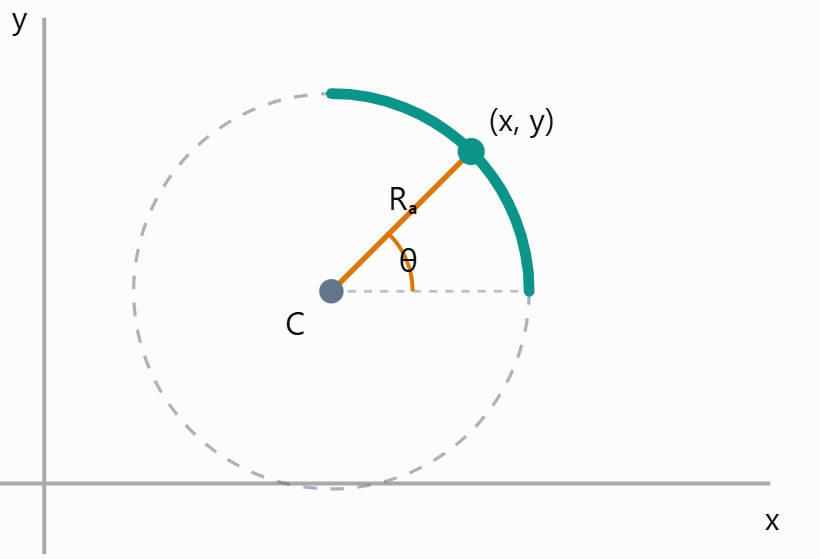

where:

- \(C_x,C_y\): Coordinates of the circle's centre.
- \(R_c\): Radius of curvature of the centreline.
- \(theta\): Angular position along the arc (radians).

The vessel will consist of two arcs with centres \(C_1\) and \(C_2\), joined such that their endpoints and tangent directions coincide, ensuring a continuous and smooth centreline.

Vessel boundaries will be generated from the centreline using a configurable local half-width \(R_v(s)\), where \(s\) is the distance along the centreline. Initially, a constant half-width will be used, with provision for narrowing (stenosis) in subsequent experiments.

All geometric parameters will be configurable rather than hardcoded.

In [3]:

# ============================================================
# S-SHAPED VESSEL CONFIGURATION
# ============================================================

@dataclass
class SVesselConfig:
    """Configurable parameters for the S-shaped centreline."""

    # Radii of curvature for the two circular arcs (m).
    arc_radius_1: float
    arc_radius_2: float

    # Angular extent of each arc (radians).
    arc_angle_1: float
    arc_angle_2: float

    # Starting position of the centreline (m).
    start_x: float
    start_y: float

    # Initial centreline direction (radians).
    start_angle: float

    # Number of points used to plot each arc.
    num_points: int


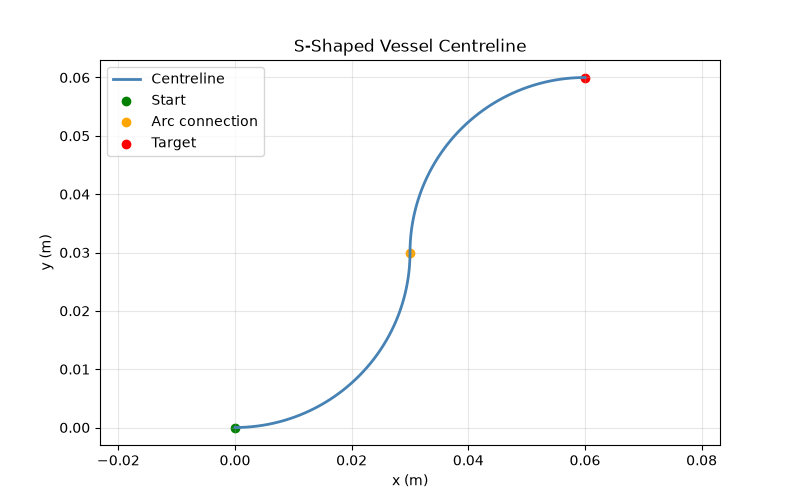

In [4]:

# ============================================================
# GENERATE THE S-SHAPED VESSEL CENTRELINE
# ============================================================

#The idea is to first generate the centre line of ths S-shaped vessel using two circular arcs joined seamlessly. 
#Then we generate the vessel wall by offsetting the centreline by a specified radius.

def generate_s_centreline(config):
    """
    Generate two tangentially connected circular arcs.

    Parameters:
        config: SVesselConfig containing the arc parameters.

    Returns:
        centreline: Array of [x, y] coordinates (m).
        join_index: Index where the two arcs connect.
    """

    def generate_arc(start, heading, radius, angle, points):
        """Generate an arc from its start point and direction."""

        theta = np.linspace(0, angle, points)

        # Calculate positions along the circular arc.
        x = start[0] + radius * (
            np.sin(heading + theta) - np.sin(heading)
        )

        y = start[1] - radius * (
            np.cos(heading + theta) - np.cos(heading)
        )

        return np.column_stack((x, y))

    # Generate the first arc (anticlockwise).
    start = np.array([config.start_x, config.start_y])

    arc1 = generate_arc(
        start,
        config.start_angle,
        config.arc_radius_1,
        config.arc_angle_1,
        config.num_points
    )

    # The second arc begins where the first arc ends.
    join_point = arc1[-1]

    # Tangent direction at the end of the first arc.
    join_heading = config.start_angle + config.arc_angle_1

    # Generate the second arc in the opposite direction.
    # Negating the angle reverses the curvature.
    arc2 = generate_arc(
        join_point,
        join_heading,
        -config.arc_radius_2,
        -config.arc_angle_2,
        config.num_points
    )

    # Combine both arcs without duplicating the connection point.
    centreline = np.vstack((arc1, arc2[1:]))

    join_index = len(arc1) - 1

    return centreline, join_index


# --- Illustrative parameters for initial geometry testing ---
# These are demonstration values, not literature-informed values.

config = SVesselConfig(
    arc_radius_1=0.03,
    arc_radius_2=0.03,
    arc_angle_1=np.deg2rad(90),
    arc_angle_2=np.deg2rad(90),
    start_x=0.0,
    start_y=0.0,
    start_angle=0.0,
    num_points=100
)

# Generate the centreline.
centreline, join_index = generate_s_centreline(config)

# --- Visualise the result ---

plt.figure(figsize=(8, 5))

plt.plot(centreline[:, 0], centreline[:, 1],
         color="steelblue", linewidth=2, label="Centreline")

plt.scatter(*centreline[0], color="green", label="Start")
plt.scatter(*centreline[join_index], color="orange",
            label="Arc connection")
plt.scatter(*centreline[-1], color="red", label="Target")

plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.title("S-Shaped Vessel Centreline")
plt.axis("equal")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


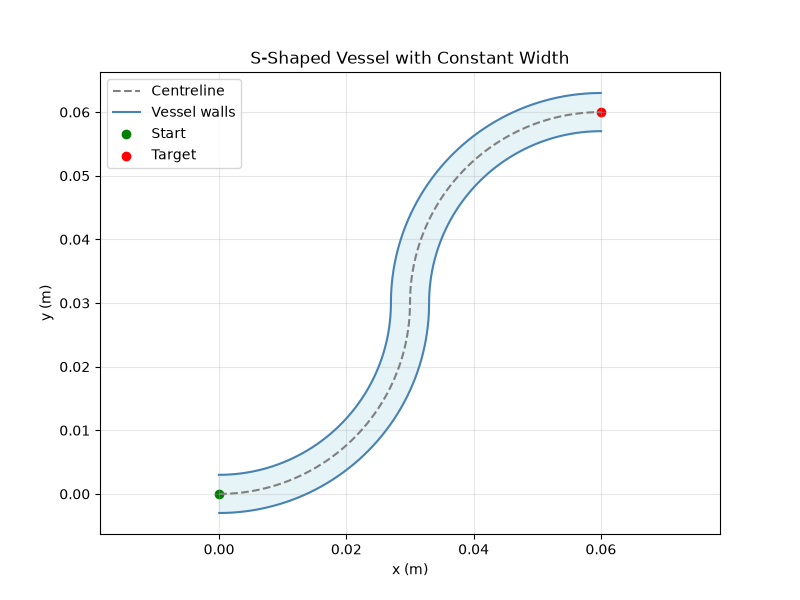

In [5]:

# ============================================================
# GENERATE THE VESSEL BOUNDARIES
# ============================================================

# Here, we generate the vessel walls by offsetting the centreline by a specified radius. The walls are generated perpendicular to the centreline at each point.

def constant_width(s, radius):
    """
    Return a constant vessel half-width along the centreline.

    Parameters:
        s(array): Distances along the vessel centreline (m). Each value represents a position along the vessel.

        radius(float): Constant vessel half-width (m). Distance from the centreline to either wall.

    Returns:
        array: Vessel half-width at each position in s (m).
    """
    return np.full_like(s, radius, dtype=float)



def generate_vessel_walls(centreline, width_profile, radius):
    """
    Generate vessel walls perpendicular to the centreline.

    Parameters:
        centreline: Array of [x, y] coordinates (m).
        width_profile: Function returning local half-widths.
        radius: Baseline vessel half-width (m).

    Returns:
        wall1, wall2: Vessel boundary coordinates (m).
        s: Cumulative distance along the centreline (m).
    """

    # Calculate cumulative distance along the centreline.
    segments = np.diff(centreline, axis=0)
    segment_lengths = np.linalg.norm(segments, axis=1)
    s = np.concatenate(([0.0], np.cumsum(segment_lengths)))

    # Estimate the local tangent direction.
    dx = np.gradient(centreline[:, 0], s)
    dy = np.gradient(centreline[:, 1], s)

    tangents = np.column_stack((dx, dy))
    tangents /= np.linalg.norm(tangents, axis=1)[:, None]

    # Rotate each tangent by 90 degrees to obtain its unit normal.
    normals = np.column_stack((-tangents[:, 1], tangents[:, 0]))

    # Obtain the local half-width from the supplied profile.
    local_radius = width_profile(s, radius)

    # Generate both walls using the local normal directions.
    wall1 = centreline + local_radius[:, None] * normals
    wall2 = centreline - local_radius[:, None] * normals

    return wall1, wall2, s


# --- Illustrative vessel width ---
# 3 mm is used for visualisation, not as a validated parameter.
vessel_radius = 0.003  # m

wall1, wall2, s = generate_vessel_walls(
    centreline,
    constant_width,
    vessel_radius
)

# --- Visualise the centreline and vessel walls ---

plt.figure(figsize=(8, 6))

plt.plot(centreline[:, 0], centreline[:, 1],
         "--", color="grey", label="Centreline")

plt.plot(wall1[:, 0], wall1[:, 1],
         color="steelblue", label="Vessel walls")

plt.plot(wall2[:, 0], wall2[:, 1],
         color="steelblue")

plt.fill(
    np.concatenate((wall1[:, 0], wall2[::-1, 0])),
    np.concatenate((wall1[:, 1], wall2[::-1, 1])),
    color="lightblue", alpha=0.3
)

plt.scatter(*centreline[0], color="green", label="Start")
plt.scatter(*centreline[-1], color="red", label="Target")

plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.title("S-Shaped Vessel with Constant Width")
plt.axis("equal")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## Stage 2 — Geometric Calculations

### 2.1 Centreline Distance and Wall Clearance

To evaluate catheter navigation, the environment must determine the catheter's position relative to the vessel geometry.

For any catheter position \(P=(x,y)\), we will calculate:

1. **Centreline deviation:** The shortest distance between the catheter tip and the vessel centreline.
2. **Wall clearance:** The minimum distance between the catheter tip and the vessel walls.
3. **Distance to target:** The distance from the catheter to the target blood clot measured along the vessel centreline. 

For a locally constant-width vessel, wall clearance can be approximated by:

$$
d_{\text{wall}}=R_v-|r|
$$

where \(R_v\) is the vessel half-width and \(r\) is the signed lateral deviation from the centreline.

A positive clearance indicates that the catheter is within the vessel, zero indicates contact with the wall, and a negative value indicates a boundary violation.

These calculations will later be used for wall-safety evaluation, reward and cost functions, and episode termination.

The implementation will use the existing vessel geometry and remain compatible with future variations in vessel width.

Centreline distance: 0.001628 m
Nearest centreline point: [0.0315  0.03936]


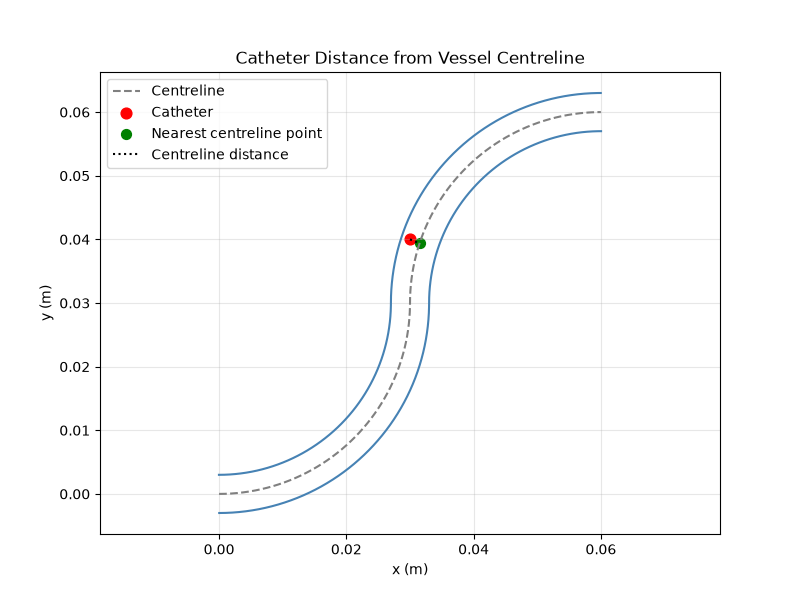

In [6]:
# ============================================================
# DISTANCE FROM THE VESSEL CENTRELINE
# ============================================================

#This cell calculates the distance from the catheter to the centreline and identifies the nearest centreline coordinates. 

def centreline_distance(position, centreline):
    """
    Find the nearest sampled centreline point.
    This is a simplified approximation to determine the catheter's distance from the vessel centreline.

    Parameters:
        position: Catheter position [x, y] (m).
        centreline: Array of centreline coordinates (m).

    Returns:
        distance: Distance to the nearest centreline point (m).
        nearest_point: Coordinates of the nearest point (m).
        nearest_index: Index of that point in the centreline.
    """

    # Build a spatial search tree from the centreline coordinates.
    tree = cKDTree(centreline)

    # Find the nearest centreline point to the catheter.
    distance, nearest_index = tree.query(position)

    nearest_point = centreline[nearest_index]

    return distance, nearest_point, nearest_index


# --- Example catheter position ---
# Illustrative test position; not an initial condition for training.
catheter_position = np.array([0.03, 0.04])

# Calculate distance to the centreline.
distance, nearest_point, nearest_index = centreline_distance(
    catheter_position,
    centreline
)

print(f"Centreline distance: {distance:.6f} m")
print(f"Nearest centreline point: {nearest_point}")


# --- Visualise the calculation ---

plt.figure(figsize=(8, 6))

plt.plot(centreline[:, 0], centreline[:, 1],
         "--", color="grey", label="Centreline")

plt.plot(wall1[:, 0], wall1[:, 1], color="steelblue")
plt.plot(wall2[:, 0], wall2[:, 1], color="steelblue")

plt.scatter(*catheter_position, color="red", s=60,
            label="Catheter")

plt.scatter(*nearest_point, color="green", s=50,
            label="Nearest centreline point")

plt.plot(
    [catheter_position[0], nearest_point[0]],
    [catheter_position[1], nearest_point[1]],
    "k:", label="Centreline distance"
)

plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.title("Catheter Distance from Vessel Centreline")
plt.axis("equal")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


Distance to nearest wall: 0.001385 m
Nearest wall point: [0.02865 0.0403 ]


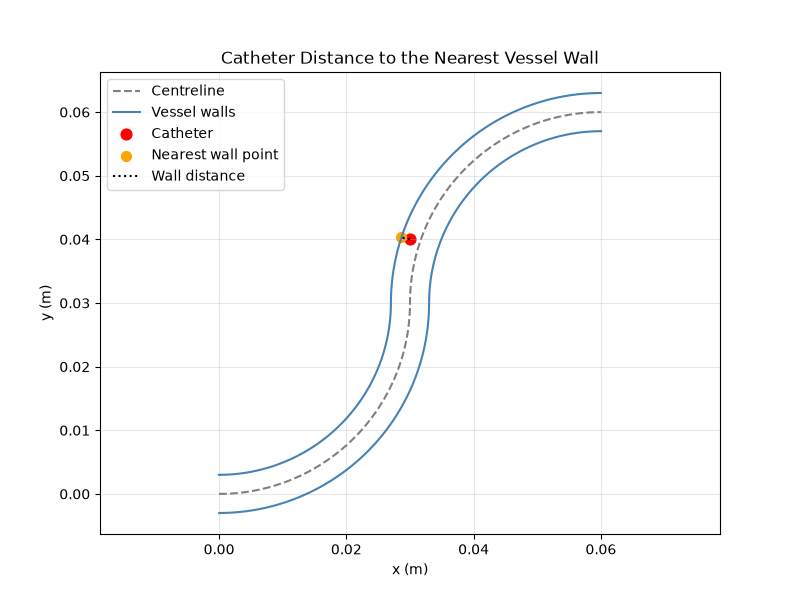

In [7]:

# ============================================================
# CALCULATE DISTANCE TO THE NEAREST VESSEL WALL
# ============================================================

#This cell calculates the distance from the catheter to the nearest vessel wall and identifies the coordinates of the wall closest to the catheter.

def wall_clearance(position, wall1, wall2):
    """
    Calculate the distance to the nearest sampled vessel wall point.

    Parameters:
        position: Catheter position [x, y] (m).
        wall1: Coordinates of the first vessel wall (m).
        wall2: Coordinates of the second vessel wall (m).

    Returns:
        distance: Distance to the nearest wall point (m).
        nearest_point: Coordinates of the nearest wall point (m).
    """

    # Combine both vessel walls into one array.
    wall_points = np.vstack((wall1, wall2))

    # Build a search tree and find the nearest wall point.
    tree = cKDTree(wall_points)
    distance, nearest_index = tree.query(position)

    nearest_point = wall_points[nearest_index]

    return distance, nearest_point


# --- Calculate clearance for the chosen catheter position ---

distance_wall, nearest_wall_point = wall_clearance(
    catheter_position, wall1, wall2
)

print(f"Distance to nearest wall: {distance_wall:.6f} m")
print(f"Nearest wall point: {nearest_wall_point}")


# --- Visualise the calculation ---

plt.figure(figsize=(8, 6))

plt.plot(centreline[:, 0], centreline[:, 1],
         "--", color="grey", label="Centreline")

plt.plot(wall1[:, 0], wall1[:, 1],
         color="steelblue", label="Vessel walls")

plt.plot(wall2[:, 0], wall2[:, 1],
         color="steelblue")

plt.scatter(*catheter_position, color="red", s=60,
            label="Catheter")

plt.scatter(*nearest_wall_point, color="orange", s=50,
            label="Nearest wall point")

# Draw the measured distance.
plt.plot(
    [catheter_position[0], nearest_wall_point[0]],
    [catheter_position[1], nearest_wall_point[1]],
    "k:", label="Wall distance"
)

plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.title("Catheter Distance to the Nearest Vessel Wall")
plt.axis("equal")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


P1: [0.03 0.04], Clearance: 0.001385 m, Inside: True
P2: [0.04 0.04], Clearance: -0.004640 m, Inside: False
P3: [0.03 0.03], Clearance: 0.003000 m, Inside: True


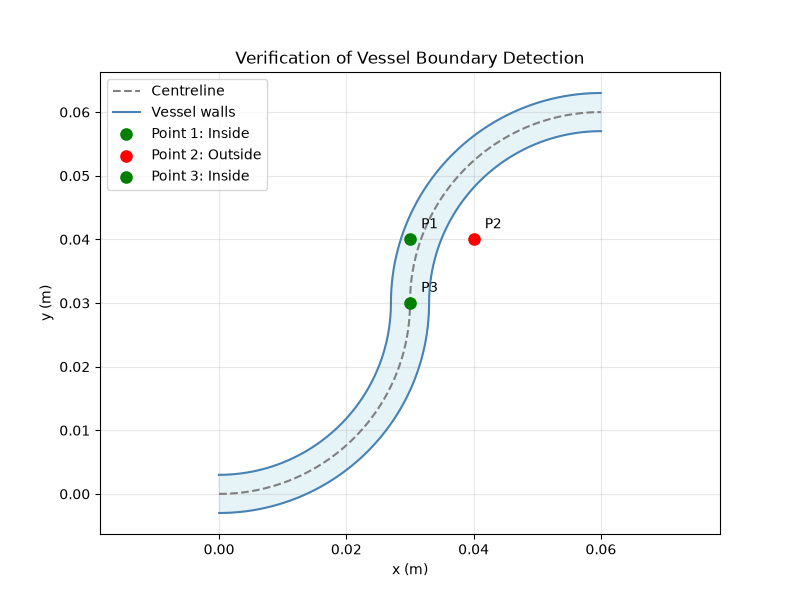

In [8]:

# ============================================================
# DETECT VESSEL BOUNDARY VIOLATIONS
# ============================================================

#This cell checks whether the catheter is inside or outside the vessel and calculates the distance (+ve or -ve) to the nearest wall.

def signed_wall_clearance(position, wall1, wall2, tolerance=1e-8):
    """
    Calculate signed wall clearance for a catheter position.

    Parameters:
        position: Catheter position [x, y] (m).
        wall1: First vessel boundary coordinates (m).
        wall2: Second vessel boundary coordinates (m).
        tolerance: Numerical threshold for boundary contact (m).

    Returns:
        signed_distance: Positive inside, negative outside (m).
        inside: Boolean indicating whether the catheter is inside.
    """

    # Combine both walls into a closed vessel boundary.
    boundary = np.vstack((wall1, wall2[::-1]))

    # Create a polygon representing the vessel interior.
    vessel_polygon = Path(boundary, closed=True)

    # Check whether the catheter lies inside the vessel.
    inside = bool(vessel_polygon.contains_point(position))

    # Reuse Cell 9 to calculate the nearest-wall distance.
    distance, _ = wall_clearance(position, wall1, wall2)

    # Treat very small distances as boundary contact.
    if distance <= tolerance:
        signed_distance = 0.0
    elif inside:
        signed_distance = distance
    else:
        signed_distance = -distance

    return signed_distance, inside



# --- Test additional catheter positions ---

test_positions = np.array([
    [0.030, 0.040],  # Inside the vessel
    [0.040, 0.040],  # Outside the vessel
    [0.030, 0.030],  # On the centreline
])

# --- Visualise the vessel and test positions ---

plt.figure(figsize=(8, 6))

# Shade the vessel interior.
plt.fill(
    np.concatenate((wall1[:, 0], wall2[::-1, 0])),
    np.concatenate((wall1[:, 1], wall2[::-1, 1])),
    color="lightblue", alpha=0.3
)

# Plot the centreline and vessel walls.
plt.plot(centreline[:, 0], centreline[:, 1],
         "--", color="grey", label="Centreline")

plt.plot(wall1[:, 0], wall1[:, 1],
         color="steelblue", label="Vessel walls")

plt.plot(wall2[:, 0], wall2[:, 1],
         color="steelblue")

# Check and plot each catheter position.
for i, position in enumerate(test_positions):

    clearance, is_inside = signed_wall_clearance(
        position, wall1, wall2
    )

    # Green indicates inside; red indicates outside.
    color = "green" if is_inside else "red"
    status = "Inside" if is_inside else "Outside"

    plt.scatter(*position, color=color, s=65, zorder=5,
                label=f"Point {i+1}: {status}")

    # Label each point on the plot.
    plt.annotate(
        f"P{i+1}",
        xy=position,
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=10
    )

    print(
        f"P{i+1}: {position}, "
        f"Clearance: {clearance:.6f} m, "
        f"Inside: {is_inside}"
    )

plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.title("Verification of Vessel Boundary Detection")
plt.axis("equal")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


Target position: [0.04625 0.05667]
Remaining centreline distance: 0.023324 m


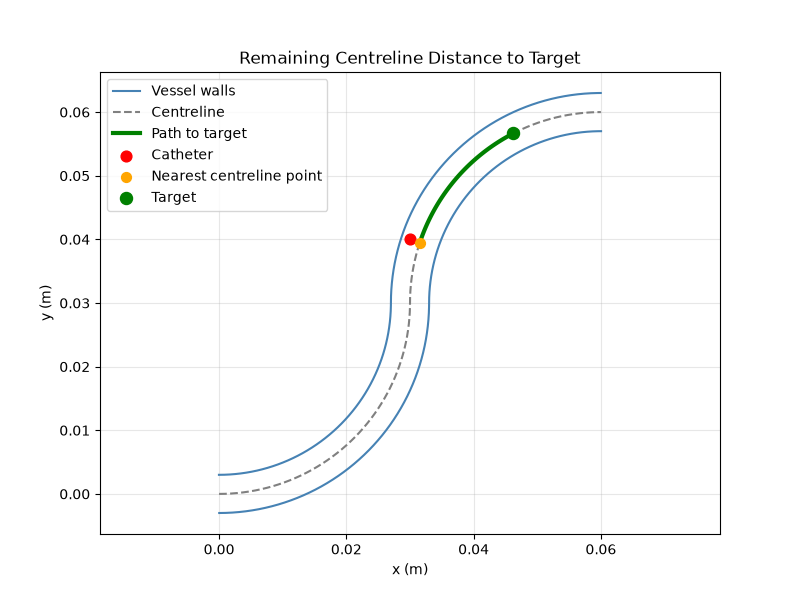

In [9]:

# ============================================================
# ADJUSTABLE BLOOD CLOT TARGET POSITION AND CENTRELINE DISTANCE
# ============================================================

#This cell defines a blood clot target along the vessel centreline and calculates the remaining distance from the catheter to that target.
#The position of the target can be adjusted to any point along the centreline by changing the target_fraction value (between 0 and 1). 
#A target_fraction of 0.85 corresponds to a position 85% along the total vessel length.

def define_target(centreline, s, target_fraction):
    """
    Define a target along the sampled vessel centreline.

    Parameters:
        centreline: Array of centreline coordinates (m).
        s: Cumulative centreline distances (m).
        target_fraction: Target location as a fraction of total
                         vessel length (between 0 and 1).

    Returns:
        target_position: Target coordinates [x, y] (m).
        target_index: Index of the nearest centreline point.
    """

    # Ensure the target fraction is within the permitted range.
    if not 0 < target_fraction < 1:
        raise ValueError("target_fraction must be between 0 and 1.")

    # Calculate the desired target distance along the vessel.
    target_s = target_fraction * s[-1]

    # Find the sampled point closest to the desired distance.
    target_index = np.argmin(np.abs(s - target_s))

    # Retrieve the corresponding target coordinates.
    target_position = centreline[target_index]

    return target_position, target_index



def distance_to_target(position, centreline, s, target_index):
    """
    Calculate remaining centreline distance to a specified target.

    Parameters:
        position: Catheter position [x, y] (m).
        centreline: Sampled centreline coordinates (m).
        s: Cumulative centreline distances (m).
        target_index: Index of the target on the centreline.

    Returns:
        remaining_distance: Signed centreline distance to the target (m).
        nearest_index: Nearest centreline index to the catheter.
    """

    # Locate the catheter along the sampled centreline.
    _, _, nearest_index = centreline_distance(
        position, centreline
    )

    # Get the cumulative distances of the catheter and target.
    current_s = s[nearest_index]
    target_s = s[target_index]

    # Signed remaining progress: negative after passing the target.
    remaining_distance = target_s - current_s

    return remaining_distance, nearest_index


# Illustrative target location: 85% along the vessel.
target_fraction = 0.85

target_position, target_index = define_target(
    centreline, s, target_fraction
)

# --- Calculate remaining distance ---

remaining_distance, nearest_index = distance_to_target(
    catheter_position, centreline, s, target_index
)

print(f"Target position: {target_position}")
print(f"Remaining centreline distance: {remaining_distance:.6f} m")


# --- Visualise the remaining path ---

plt.figure(figsize=(8, 6))

# Plot the vessel boundaries and centreline.
plt.plot(wall1[:, 0], wall1[:, 1],
         color="steelblue", label="Vessel walls")

plt.plot(wall2[:, 0], wall2[:, 1], color="steelblue")

plt.plot(centreline[:, 0], centreline[:, 1],
         "--", color="grey", label="Centreline")

# Highlight the route between catheter and target.
start_index = min(nearest_index, target_index)
end_index = max(nearest_index, target_index)

remaining_path = centreline[start_index:end_index + 1]

plt.plot(remaining_path[:, 0], remaining_path[:, 1],
         color="green", linewidth=3, label="Path to target")

# Mark catheter, nearest centreline point and target.
plt.scatter(*catheter_position, color="red", s=60,
            label="Catheter", zorder=5)

plt.scatter(*centreline[nearest_index],
            color="orange", s=50,
            label="Nearest centreline point", zorder=5)

plt.scatter(*target_position, color="green", s=75,
            label="Target", zorder=5)

plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.title("Remaining Centreline Distance to Target")
plt.axis("equal")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()



### Local Tangent, Normal and Lateral Offset

To model blood flow along the curved vessel, we will first need functions to calculate the local blood flow direction (local tangent), normal and lateral offset. These will be used to inform how the blood-flow  profile in stage 3 affect the catheter. 


In [10]:

# ============================================================
# LOCAL TANGENT AND NORMAL VECTORS
# ============================================================

def local_directions(position, centreline, s):
    """
    Calculate the local unit tangent and normal vectors.

    Parameters:
        position: Catheter position [x, y] (m).
        centreline: Sampled centreline coordinates (m).
        s: Cumulative centreline distances (m).

    Returns:
        tangent: Unit vector along the centreline.
        normal: Unit vector perpendicular to the centreline.
        signed_offset: Signed catheter deviation (m).
    """

    # Find the nearest sampled centreline point.
    _, nearest_point, nearest_index = centreline_distance(
        position, centreline
    )

    # Estimate the tangent vectors along the centreline.
    dx = np.gradient(centreline[:, 0], s)
    dy = np.gradient(centreline[:, 1], s)

    # Select the tangent at the nearest centreline point.
    tangent = np.array([
        dx[nearest_index],
        dy[nearest_index]
    ])

    # Normalise the tangent to unit length.
    tangent = tangent / np.linalg.norm(tangent)

    # Rotate the tangent by 90 degrees to get the normal.
    normal = np.array([-tangent[1], tangent[0]])

    # Calculate signed displacement from the centreline.
    displacement = position - nearest_point
    signed_offset = np.dot(displacement, normal)

    return tangent, normal, signed_offset


# --- Test using the chosen catheter position ---

tangent, normal, signed_offset = local_directions(
    catheter_position, centreline, s
)

print(f"Local tangent: {tangent}")
print(f"Local normal: {normal}")
print(f"Signed centreline offset: {signed_offset:.6f} m")


Local tangent: [0.31203 0.95007]
Local normal: [-0.95007  0.31203]
Signed centreline offset: 0.001622 m



## Stage 3 — Blood Flow Modelling

This stage implements a simplified, Poiseuille-inspired blood-flow model within the vessel. The flow velocity depends on the catheter's lateral offset from the centreline, the local vessel radius, and the local tangent direction.

The model assumes maximum flow speed at the centreline and decreasing speed towards the vessel walls:

$$
u(r)=u_{\max}\left(1-\frac{r^2}{R^2}\right)
$$

where:
- $u_{\max}$ is the maximum blood-flow speed (m/s).
- $r$ is the catheter's lateral offset from the centreline (m).
- $R$ is the local vessel radius (m).

The scalar flow speed is combined with the local unit tangent to obtain the two-dimensional blood-flow velocity:

$$
\mathbf{v}_{\mathrm{flow}}=u(r)\,\hat{\mathbf{t}}
$$

All flow parameters will be configurable to support different vessel geometries and robustness experiments.


In [11]:

# ============================================================
# BLOOD-FLOW VELOCITY
# ============================================================

# Here, using the local tangent (local blood flow direction) and lateral offset, we calculate the local Poiseuille-inspired blood-flow velocity.
# The flow speed is maximum at the centreline and decreases parabolically to zero at the vessel walls.

def blood_flow_velocity(position, centreline, s, local_radius, max_flow_speed):
    """
    Calculate the local Poiseuille-inspired blood-flow velocity.

    Parameters:
        position: Catheter position [x, y] (m).
        centreline: Sampled centreline coordinates (m).
        s: Cumulative centreline distances (m).
        local_radius: Vessel half-width at each centreline point (m).
        max_flow_speed: Maximum blood-flow speed (m/s).

    Returns:
        flow_velocity: Two-dimensional blood-flow velocity [vx, vy] (m/s).
    """

    # Obtain the local flow direction and lateral offset.
    tangent, _, signed_offset = local_directions(
        position, centreline, s
    )

    # Identify the nearest centreline location.
    _, _, nearest_index = centreline_distance(
        position, centreline
    )

    # Get the vessel radius at that location.
    radius = local_radius[nearest_index]

    # Calculate blood-flow speed using the parabolic profile.
    flow_speed = max_flow_speed * (
        1 - (signed_offset / radius)**2
    )

    # Prevent negative flow speeds outside the nominal profile.
    flow_speed = max(0.0, flow_speed)

    # Convert scalar speed to a two-dimensional velocity vector.
    flow_velocity = flow_speed * tangent

    return flow_velocity


# --- Test the function ---

# Configurable illustrative maximum blood-flow speed.
max_flow_speed = 0.20  # m/s

# Constant-width profile from Cell 6.
local_radius = constant_width(s, vessel_radius)

flow_velocity = blood_flow_velocity(
    catheter_position,
    centreline,
    s,
    local_radius,
    max_flow_speed
)

print(f"Catheter position: {catheter_position}")
print(f"Blood-flow velocity: {flow_velocity} m/s")
print(f"Blood-flow speed: {np.linalg.norm(flow_velocity):.6f} m/s")


Catheter position: [0.03 0.04]
Blood-flow velocity: [0.04415 0.13444] m/s
Blood-flow speed: 0.141502 m/s



## Stage 4 — Catheter Dynamics and Numerical Integration

This stage models the catheter tip as a point mass moving under the combined influence of controller-applied forces and blood-flow-induced drag.

The catheter state is:

$$
\mathbf{x}=[x,\ y,\ v_x,\ v_y]
$$

The controller applies forces:

$$
\mathbf{F}_{control}=[F_x,\ F_y]
$$

The relative velocity between blood flow and catheter motion is:

$$
\mathbf{v}_{rel}=\mathbf{v}_{flow}-\mathbf{v}_{catheter}
$$


The fluid disturbance acting on the catheter is approximated using the quadratic drag formulation specified in the research proposal:

$$
\mathbf{F}_{drag}=
\frac{1}{2}\rho_b C_d A
\|\mathbf{v}_{flow}-\mathbf{v}_{catheter}\|
(\mathbf{v}_{flow}-\mathbf{v}_{catheter})
$$

where $\rho_b$ is blood density, $C_d$ is the dimensionless drag coefficient, and $A$ is the catheter reference area.


Using Newton's second law:

$$
\mathbf{a}=\frac{\mathbf{F}_{control}+\mathbf{F}_{drag}}{m}
$$

The resulting differential equations will be integrated using the Runge–Kutta method to update the catheter's position and velocity.

All physical parameters, including mass, drag coefficient, control forces, and integration timestep, will remain configurable.


In [12]:

# ============================================================
# CATHETER DYNAMICS WITH QUADRATIC DRAG
# ============================================================

#With this function, we calculate the catheter's acceleration based on Newton's second law, considering both the control force and the quadratic drag force from the blood flow.

def catheter_dynamics(state, control_force, flow_velocity,
                      mass, blood_density, drag_coefficient, reference_area):
    """
    Calculate catheter state derivatives using Newton's second law.

    Parameters:
        state: [x, y, vx, vy] (m, m/s).
        control_force: Applied force [Fx, Fy] (N).
        flow_velocity: Local blood velocity [ux, uy] (m/s).
        mass: Effective catheter tip mass (kg).
        blood_density: Blood density (kg/m^3).
        drag_coefficient: Dimensionless drag coefficient.
        reference_area: Catheter reference area (m^2).

    Returns:
        state_derivative: [vx, vy, ax, ay].
    """

    # Check physical parameter validity.
    if mass <= 0 or blood_density <= 0 or reference_area <= 0:
        raise ValueError("Mass, blood density and reference area must be positive.")

    if drag_coefficient < 0:
        raise ValueError("Drag coefficient cannot be negative.")

    # Extract catheter velocity from the state.
    catheter_velocity = state[2:4]

    # Calculate blood velocity relative to the catheter.
    relative_velocity = flow_velocity - catheter_velocity

    # Calculate quadratic drag force from the proposal.
    drag_force = (
        0.5 * blood_density * drag_coefficient * reference_area
        * np.linalg.norm(relative_velocity)
        * relative_velocity
    )

    # Calculate catheter acceleration.
    acceleration = (control_force + drag_force) / mass

    # Construct the state derivative.
    state_derivative = np.concatenate(
        (catheter_velocity, acceleration)
    )

    return state_derivative


# --- Test using illustrative parameters ---

state = np.array([0.03, 0.04, 0.01, 0.02])
control_force = np.array([0.0, 0.0])

mass = 0.001               # kg
blood_density = 1060.0     # kg/m^3
drag_coefficient = 1.0     # dimensionless
reference_area = 1e-6      # m^2

state_derivative = catheter_dynamics(
    state, control_force, flow_velocity,
    mass, blood_density, drag_coefficient, reference_area
)

print(f"Catheter velocity: {state_derivative[:2]} m/s")
print(f"Catheter acceleration: {state_derivative[2:]} m/s²")
print(f"Full state derivative: {state_derivative}")


Catheter velocity: [0.01 0.02] m/s
Catheter acceleration: [0.00216 0.00724] m/s²
Full state derivative: [0.01    0.02    0.00216 0.00724]


In [13]:

# ============================================================
# CATHETER STATE UPDATE USING RK45
# ============================================================

#Here, we integrate the catheter's state over a single timestep using the RK45 method. 
#The Scipy `solve_ivp` function is used to perform the integration, which allows for adaptive step sizing and error control.


def integrate_catheter(state, control_force, dt, centreline, s,
                       local_radius, max_flow_speed, mass,
                       blood_density, drag_coefficient, reference_area,
                       rtol=1e-6, atol=1e-9):
    """
    Advance the catheter state by one timestep using RK45.

    Parameters:
        state: Current catheter state [x, y, vx, vy].
        control_force: Applied force [Fx, Fy] (N).
        dt: Simulation timestep (s).
        centreline, s, local_radius: Vessel geometry parameters for the centreline, cumulative distance, and local radius.
        max_flow_speed: Maximum blood-flow speed (m/s).
        mass: Effective catheter mass (kg).
        blood_density: Blood density (kg/m^3).
        drag_coefficient: Dimensionless drag coefficient.
        reference_area: Catheter reference area (m^2).
        rtol, atol: RK45 error tolerances.

    Returns:
        next_state: Updated catheter state [x, y, vx, vy].
    """

    if dt <= 0:
        raise ValueError("Timestep must be positive.")

    # Define the differential equations evaluated by RK45.
    def combined_dynamics(t, current_state):

        # Obtain the catheter's current estimated position.
        position = current_state[:2]

        # Recalculate blood velocity at that position.
        flow_velocity = blood_flow_velocity(
            position, centreline, s, local_radius, max_flow_speed
        )

        # Calculate the corresponding state derivatives.
        return catheter_dynamics(
            current_state, control_force, flow_velocity,
            mass, blood_density, drag_coefficient, reference_area
        )

    # Integrate over one simulation timestep.
    solution = solve_ivp(
        combined_dynamics,
        t_span=(0.0, dt),
        y0=state,
        method="RK45",
        rtol=rtol,
        atol=atol
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    # Extract the state at the end of the timestep.
    next_state = solution.y[:, -1]

    return next_state


# --- Test with the illustrative parameters from Cell 14 ---

dt = 0.01  # Simulation timestep (s)

next_state = integrate_catheter(
    state, control_force, dt,
    centreline, s, local_radius, max_flow_speed,
    mass, blood_density, drag_coefficient, reference_area
)

print(f"Initial state: {state}")
print(f"Updated state: {next_state}")
print(f"Change in state: {next_state - state}")


Initial state: [0.03 0.04 0.01 0.02]
Updated state: [0.0301  0.0402  0.01002 0.02007]
Change in state: [0.0001  0.0002  0.00002 0.00007]



## Stage 5 & 6 —  Gymnasium Environment Implementation and Verification

This stage integrates the previously developed geometry, blood-flow, catheter-dynamics and RK45 functions into a reusable simulation environment compatible with Gymnasium.

The environment will support different vessel geometries while maintaining identical catheter physics and simulation rules for SAC and MPC.

The development will involve:

1. **Vessel geometry classes:** Implement an `SVessel` class using the existing S-shaped geometry functions, with a common interface that can later support a Y-shaped bifurcation and variable vessel widths.

2. **Configurable simulation parameters:** Organise geometric, physical, numerical and task parameters so they can be adjusted without modifying the underlying functions.

3. **Gymnasium environment:** Implement the environment's observation space, continuous action space, `reset()` and `step()` methods.

4. **Navigation objectives and safety:** Define conditions for regarding a navigation as successful and distinguish side-wall violations from entrance and distal exits.

5. **Reward function and episode termination:** Implement configurable rewards, penalties and termination conditions that can be applied consistently across both controllers.

6. **Verification**: This is stage 6 involving testing the geometry and the environment for physical and Numerical correcteness. Ideally, this should be a standalone. 

Stages 5 and 6 are merged because it is ideal to adopt an incrementaal apporach to implementing the environment. In this approach, we implement the environment incrementally, feature after feature. At each stage, the enviromnet and features will be verified(stage 6) for required correctness and functinality before implementing the next feature. This makes implementation and problem diagnosis easier. 




In [14]:

# ============================================================
# S-SHAPED VESSEL GEOMETRY CLASS
# ============================================================

#This cells wraps the previously defined functions into a single class, SVessel.
#This will be used to encapsulate the S-shaped vessel geometry and provide methods for geometric calculations in the gymnaisum environment.

class SVessel:
    """Store S-shaped vessel geometry and provide geometric calculations."""

    def __init__(self, config, width_profile, radius, target_fraction):

        # Generate the centreline using generate_s_centreline function from earlier cells.
        self.centreline, self.join_index = generate_s_centreline(config)

        # Generate vessel walls and cumulative distances using Cell 6.
        self.wall1, self.wall2, self.s = generate_vessel_walls(
            self.centreline, width_profile, radius
        )

        # Store the local vessel radius at each centreline point.
        self.local_radius = width_profile(self.s, radius)


        # Exception handndling for invalid vessel radius values.
        if not np.all(np.isfinite(self.local_radius)) or np.any(self.local_radius <= 0):
            raise ValueError("All vessel radii must be finite and positive.")

        # Define the target using Cell 11.
        self.target_position, self.target_index = define_target(
            self.centreline, self.s, target_fraction
        )

        # Store the total centreline length.
        self.length = self.s[-1]

    def distance_to_target(self, position):
        """Return signed remaining centreline progress to the target."""

        remaining_distance, _ = distance_to_target(
            position, self.centreline, self.s, self.target_index
        )

        return remaining_distance

    def wall_clearance(self, position):
        """Return signed wall clearance and inside/outside classification."""

        return signed_wall_clearance(
            position, self.wall1, self.wall2
        )

    def flow_direction(self, position):
        """Return the local unit tangent vector."""

        tangent, _, _ = local_directions(
            position, self.centreline, self.s
        )

        return tangent

    def lateral_offset(self, position):
        """Return the signed lateral offset from the centreline."""

        _, _, signed_offset = local_directions(
            position, self.centreline, self.s
        )

        return signed_offset


# --- Create an S-shaped vessel using our existing configuration ---

vessel = SVessel(
    config=config,
    width_profile=constant_width,
    radius=vessel_radius,
    target_fraction=0.85
)

# --- Test the class ---

print(f"Vessel length: {vessel.length:.6f} m")
print(f"Target position: {vessel.target_position}")
print(f"Signed target progress: {vessel.distance_to_target(catheter_position):.6f} m")
print(f"Wall clearance: {vessel.wall_clearance(catheter_position)}")
print(f"Flow direction: {vessel.flow_direction(catheter_position)}")
print(f"Lateral offset: {vessel.lateral_offset(catheter_position):.6f} m")


Vessel length: 0.094247 m
Target position: [0.04625 0.05667]
Signed target progress: 0.023324 m
Wall clearance: (0.0013845983937325168, True)
Flow direction: [0.31203 0.95007]
Lateral offset: 0.001622 m


In [15]:
# ============================================================
# ENVIRONMENT CONFIGURATION
# ============================================================
#Similar to the SVesselConfig class, this EnvironmentConfig class encapsulates the physical, numerical and navigation parameters for the catheter navigation environment.
@dataclass
class EnvironmentConfig:
    """Configurable physical, numerical and navigation parameters."""

    # Catheter and blood-flow parameters
    mass: float
    blood_density: float
    drag_coefficient: float
    reference_area: float
    max_flow_speed: float

    # Controller limits
    max_force: float

    # Numerical integration
    dt: float
    rtol: float
    atol: float

    # Navigation task
    target_tolerance: float
    max_episode_steps: int

    def __post_init__(self):
        """Validate configuration parameters after initialisation."""

        positive_values = {
            "mass": self.mass,
            "blood_density": self.blood_density,
            "reference_area": self.reference_area,
            "max_force": self.max_force,
            "dt": self.dt,
            "rtol": self.rtol,
            "atol": self.atol,
            "max_episode_steps": self.max_episode_steps
        }

        for name, value in positive_values.items():
            if not np.isfinite(value) or value <= 0:
                raise ValueError(f"{name} must be finite and positive.")

        nonnegative_values = {
            "drag_coefficient": self.drag_coefficient,
            "max_flow_speed": self.max_flow_speed,
            "target_tolerance": self.target_tolerance
        }

        for name, value in nonnegative_values.items():
            if not np.isfinite(value) or value < 0:
                raise ValueError(f"{name} must be finite and non-negative.")

        if not isinstance(self.max_episode_steps, int):
            raise ValueError("max_episode_steps must be an integer.")


# --- Create an illustrative environment configuration ---

env_config = EnvironmentConfig(
    mass=0.001,               # kg
    blood_density=1060.0,     # kg/m^3
    drag_coefficient=1.0,     # dimensionless
    reference_area=1e-6,      # m^2
    max_flow_speed=0.20,      # m/s
    max_force=0.001,          # N
    dt=0.01,                 # s
    rtol=1e-6,
    atol=1e-9,
    target_tolerance=0.002,   # m (2 mm along centreline)
    max_episode_steps=1000
)

print(env_config)


EnvironmentConfig(mass=0.001, blood_density=1060.0, drag_coefficient=1.0, reference_area=1e-06, max_flow_speed=0.2, max_force=0.001, dt=0.01, rtol=1e-06, atol=1e-09, target_tolerance=0.002, max_episode_steps=1000)


In [16]:

# ============================================================
# DEFINE THE CATHETER NAVIGATION ENVIRONMENT
# ============================================================

#In this cell, we begin defining a custom Gymnasium environment for catheter navigation.
#The environment will encapsulate the dynamics, observation space, and action space for reinforcement learning agents.

class CatheterEnv(gym.Env):
    """Shared catheter navigation environment for SAC and MPC."""

    def __init__(self, vessel, config):
        #It takes the vessel geometry and configuration objects as input parameters 
        super().__init__()

        self.vessel = vessel
        self.config = config

        # Controller forces [Fx, Fy].
        self.action_space = spaces.Box(
            low=-config.max_force,
            high=config.max_force,
            shape=(2,),
            dtype=np.float32
        )

        # Set the dimensionality of the observation space [x, y, vx, vy, d_target, d_wall].
        self.observation_space = spaces.Box(
            low=-np.inf,
            high=np.inf,
            shape=(6,),
            dtype=np.float32
        )

        # Initialise episode state and step counter.
        self.state = None
        self.steps = 0
        self.episode_done = False #Only reset the environment when the episode is done.

    def _get_observation(self):
        """Construct the six-dimensional observation vector from the current catheter state. 
        Recall that from the project proposal, the catheter state is a four-dimensional vector [x, y, vx, vy] and is different from the observation vector which RL agent needs to make decisions.
        Observation vector includes the distance to the target and the distance to the nearest vessel wall."""

        position = self.state[:2]

        #Extract the distance to the target and the distance to the nearest wall from the vessel object.
        d_target = self.vessel.distance_to_target(position)
        d_wall, _ = self.vessel.wall_clearance(position)

        observation = np.array([
            self.state[0],
            self.state[1],
            self.state[2],
            self.state[3],
            d_target,
            d_wall
        ], dtype=np.float32)

        return observation

    def reset(self, *, seed=None, options=None):
        """Reset catheter position, velocity and episode counter.
        This is needed to ensure that the environment is in a valid state before starting a new episode.
        Parameters:
            seed: Optional random seed for reproducibility.
            Options: A dictionary of options for the reset.
        Returns:
            observation: The initial observation vector after reset.
            info: Additional information about the environment state after reset.
        """

        super().reset(seed=seed)

        #Iniitialize the reset options as an empty dictionary if none are provided.
        if options is None:
            options = {}

        # Start just inside the vessel entrance.
        initial_position = options.get(
            "initial_position", self.vessel.centreline[1]
        )

        # Start at rest unless another velocity is supplied.
        initial_velocity = options.get(
            "initial_velocity", [0.0, 0.0]
        )

        # Construct the four-dimensional physical state.
        self.state = np.concatenate((
            np.asarray(initial_position, dtype=float),
            np.asarray(initial_velocity, dtype=float)
        ))

        #Ensure that the initial state is valid: it must contain four finite values and the catheter must be inside the vessel.
        if self.state.shape != (4,) or not np.all(np.isfinite(self.state)):
            raise ValueError("Initial state must contain four finite values.")

        _, inside = self.vessel.wall_clearance(self.state[:2])

        if not inside:
            raise ValueError("Initial catheter position must be inside the vessel.")

        self.steps = 0
        self.episode_done = False

        #Obtain the initial observation vector and additional information about the environment state.
        observation = self._get_observation()

        info = {
            "target_position": self.vessel.target_position.copy(),
            "inside_vessel": inside
        }

        return observation, info

    def step(self, action):
        """Advance the catheter and evaluate navigation outcomes.
        Parameters:
            action: Control force [Fx, Fy] (N).
            Returns: xx
            observation: Updated observation vector."""
        
        #Validate current state 
        if self.state is None or self.episode_done:
            raise RuntimeError("Call reset() before stepping a new episode.")

        # Validate the controller's applied forces.
        action = np.asarray(action, dtype=float)

        if action.shape != (2,) or not np.all(np.isfinite(action)):
            raise ValueError("Action must contain two finite force values.")

        if not self.action_space.contains(action.astype(np.float32)):
            raise ValueError("Action exceeds the configured force limits.")        

        # Advance the physical state using RK45 (Cell 15).
        self.state = integrate_catheter(
            self.state, action, self.config.dt,
            self.vessel.centreline,
            self.vessel.s,
            self.vessel.local_radius,
            self.config.max_flow_speed,
            self.config.mass,
            self.config.blood_density,
            self.config.drag_coefficient,
            self.config.reference_area,
            rtol=self.config.rtol,
            atol=self.config.atol
        )

        self.steps += 1 #Increament of the step counter

        # Evaluate geometry at the updated catheter position.
        position = self.state[:2]
        d_target = self.vessel.distance_to_target(position)
        d_wall, inside = self.vessel.wall_clearance(position)

        # Determine success or failure at the updated state.
        success = inside and (d_target <= self.config.target_tolerance) #success is defined as being inside the vessel and within the target tolerance along the centreline.
        vessel_exit = not inside 

        terminated = bool(success or vessel_exit) #Terminate the episode if the catheter has either successfully reached the target or exited the vessel.
        truncated = bool(
            self.steps >= self.config.max_episode_steps
            and not terminated
        )  #Truncate the episode if the maximum number of steps is reached without success or vessel exit.

        if success:
            outcome = "success"
        elif vessel_exit:
            outcome = "vessel_exit"
        elif truncated:
            outcome = "time_limit"
        else:
            outcome = "ongoing"

        self.episode_done = terminated or truncated #End the episode if either termination or truncation conditions are met.

        # Reward calculation TBI...0 is the placeholder for now. 
        reward = 0.0

        observation = self._get_observation()

        info = {
            "outcome": outcome,
            "is_success": bool(success),
            "inside_vessel": bool(inside),
            "target_progress": float(d_target),
            "wall_clearance": float(d_wall)
        }

        return observation, reward, terminated, truncated, info

         

# --- Test a single environment step ---

env = CatheterEnv(vessel=vessel, config=env_config)

initial_observation, _ = env.reset(seed=42)

# Apply zero control force to isolate the effect of blood flow.
action = np.array([0.0, 0.0], dtype=np.float32)

observation, reward, terminated, truncated, info = env.step(action)

print("Initial observation:", initial_observation)
print("Updated observation:", observation)
print("Reward:", reward)
print("Terminated:", terminated)
print("Truncated:", truncated)
print("Outcome:", info["outcome"])
print("Episode steps:", env.steps)
print("Observation valid:", env.observation_space.contains(observation))


Initial observation: [0.00048 0.      0.      0.      0.07949 0.003  ]
Updated observation: [0.00048 0.      0.00021 0.      0.07949 0.003  ]
Reward: 0.0
Terminated: False
Truncated: False
Outcome: ongoing
Episode steps: 1
Observation valid: True



### Completing the Gymnasium Environment

The `CatheterEnv` class now defines the action and observation spaces, initialises episodes using `reset()`, and updates catheter motion using RK45 through `step()`. It also calculates target progress and wall clearance and identifies basic termination conditions.

To complete the environment, we need to:

1. Implement the reward function for navigation progress, wall proximity, control effort, success and failure.
2. Distinguish side-wall violations from entrance and distal exits.
3. Verify termination conditions, including target crossing and boundary handling.
4. Implement optional rendering to visualise catheter trajectories.
5. Validate the completed environment before SAC and MPC experiments.

### Reward Function

The reward function follows the research proposal, with normalised progress, wall-clearance and control-effort terms:

$$
r_t =
w_p\frac{d_{t-1}-d_t}{L}
-w_w\left(1-\frac{d_{\mathrm{wall},t}}{R_t}\right)
-w_u\left\|\frac{\mathbf F_t}{F_{\max}}\right\|^2
+r_{\mathrm{success},t}
-r_{\mathrm{failure},t}
$$

where:

- $d_{t-1}-d_t$: Centreline progress achieved during the timestep.
- $L$: Total vessel centreline length.
- $d_{\mathrm{wall},t}$: Distance to the nearest vessel wall.
- $R_t$: Local vessel radius.
- $\mathbf F_t/F_{\max}$: Normalised control force.
- $w_p$, $w_w$, $w_u$: Configurable reward weights.
- $r_{\mathrm{success},t}$: Positive reward for reaching or crossing the target within the vessel.
- $r_{\mathrm{failure},t}$: Penalty for leaving the permissible vessel region.

The wall term encourages clearance from vessel boundaries, while the control term discourages unnecessarily large forces.

All reward weights and terminal bonuses or penalties will remain configurable.


In [17]:

# ============================================================
# NAVIGATION REWARD FUNCTION
# ============================================================

@dataclass
class RewardConfig:
    """Configurable weights and terminal rewards."""

    progress_weight: float
    wall_weight: float
    control_weight: float
    success_bonus: float
    failure_penalty: float


def calculate_reward(previous_d_target, current_d_target, d_wall,
                     local_radius, control_force, vessel_length,
                     max_force, reward_config, success, failure):
    """
    Calculate the navigation reward for one simulation step.

    Parameters:
        previous_d_target, current_d_target: Signed target progress (m).
        d_wall: Signed nearest-wall clearance (m).
        local_radius: Vessel half-width at the catheter location (m).
        control_force: Applied controller force [Fx, Fy] (N).
        vessel_length: Total centreline length (m).
        max_force: Maximum force per action component (N).
        reward_config: Reward weights and terminal values.
        success, failure: Boolean episode outcomes.

    Returns:
        reward: Total scalar reward.
        components: Dictionary containing individual reward terms.
    """

    # Reward forward progress along the vessel.
    progress_reward = reward_config.progress_weight * (
        (previous_d_target - current_d_target) / vessel_length
    )

    # Penalise proximity to the vessel wall.
    wall_penalty = np.clip(
        1.0 - d_wall / local_radius, 0.0, 1.0
    )
    wall_reward = -reward_config.wall_weight * wall_penalty

    # Penalise unnecessarily large control forces.
    normalised_force = control_force / max_force
    control_reward = -reward_config.control_weight * np.sum(
        normalised_force**2
    )

    # Apply terminal rewards or penalties.
    terminal_reward = (
        reward_config.success_bonus * success
        - reward_config.failure_penalty * failure
    )

    reward = (
        progress_reward + wall_reward
        + control_reward + terminal_reward
    )

    components = {
        "progress": float(progress_reward),
        "wall": float(wall_reward),
        "control": float(control_reward),
        "terminal": float(terminal_reward)
    }

    return float(reward), components


# --- Illustrative reward parameters ---

reward_config = RewardConfig(
    progress_weight=10.0,
    wall_weight=0.01,
    control_weight=0.001,
    success_bonus=10.0,
    failure_penalty=10.0
)

# --- Test using an illustrative navigation step ---

previous_d_target = 0.050
current_d_target = 0.049

test_force = np.array([0.0002, 0.0001])

reward, components = calculate_reward(
    previous_d_target=previous_d_target,
    current_d_target=current_d_target,
    d_wall=0.002,
    local_radius=0.003,
    control_force=test_force,
    vessel_length=vessel.length,
    max_force=env_config.max_force,
    reward_config=reward_config,
    success=False,
    failure=False
)

print(f"Progress reward: {components['progress']:.6f}")
print(f"Wall reward:     {components['wall']:.6f}")
print(f"Control reward:  {components['control']:.6f}")
print(f"Terminal reward: {components['terminal']:.6f}")
print(f"Total reward:    {reward:.6f}")


Progress reward: 0.106104
Wall reward:     -0.003333
Control reward:  -0.000050
Terminal reward: 0.000000
Total reward:    0.102721


Now, we update the environment class to include this reward function. 

In [18]:

# ======================================================================
# DEFINE THE CATHETER NAVIGATION ENVIRONMENT AND INCLUDE REWARD FUNCTION
# ======================================================================

class CatheterEnv(gym.Env):
    """Gymnasium environment for catheter navigation using SAC and MPC."""

    def __init__(self, vessel, config, reward_config):
        """Initialise vessel geometry, physics, rewards and Gymnasium spaces."""
        super().__init__()

        self.vessel = vessel
        self.config = config
        self.reward_config = reward_config

        # Controller forces [Fx, Fy].
        self.action_space = spaces.Box(
            low=-config.max_force,
            high=config.max_force,
            shape=(2,),
            dtype=np.float32
        )

        # Observations [x, y, vx, vy, d_target, d_wall].
        self.observation_space = spaces.Box(
            low=-np.inf,
            high=np.inf,
            shape=(6,),
            dtype=np.float32
        )

        # Episode state and tracking variables.
        self.state = None
        self.steps = 0
        self.episode_done = False

    def _get_observation(self):
        """Construct the six-dimensional observation vector from the current catheter state. 
        Recall that from the project proposal, the catheter state is a four-dimensional vector [x, y, vx, vy] and is different from the observation vector which RL agent needs to make decisions.
        Observation vector includes the distance to the target and the distance to the nearest vessel wall."""

        position = self.state[:2]

        d_target = self.vessel.distance_to_target(position)
        d_wall, _ = self.vessel.wall_clearance(position)

        observation = np.array([
            self.state[0],
            self.state[1],
            self.state[2],
            self.state[3],
            d_target,
            d_wall
        ], dtype=np.float32)

        return observation

    def _calculate_reward(self, previous_d_target, current_d_target,
                          d_wall, local_radius, control_force,
                          success, failure):
        """
        Calculate navigation reward and its individual components.

        Includes normalised progress, wall proximity, control effort,
        and terminal success or failure rewards.
        """

        # Reward forward centreline progress.
        progress_reward = self.reward_config.progress_weight * (
            (previous_d_target - current_d_target) / self.vessel.length
        )

        # Penalise proximity to the wall, normalised by local radius.
        wall_penalty = np.clip(
            1.0 - d_wall / local_radius, 0.0, 1.0
        )
        wall_reward = -self.reward_config.wall_weight * wall_penalty

        # Penalise large applied forces.
        normalised_force = control_force / self.config.max_force
        control_reward = -self.reward_config.control_weight * np.sum(
            normalised_force**2
        )

        # Apply a bonus for success or penalty for leaving the vessel.
        terminal_reward = (
            self.reward_config.success_bonus * success
            - self.reward_config.failure_penalty * failure
        )

        reward = (
            progress_reward + wall_reward
            + control_reward + terminal_reward
        )

        components = {
            "progress": float(progress_reward),
            "wall": float(wall_reward),
            "control": float(control_reward),
            "terminal": float(terminal_reward)
        }

        return float(reward), components

    def reset(self, *, seed=None, options=None):
        """
        Reset the catheter position, velocity and episode counter.

        Optional reset settings:
            initial_position: Starting [x, y] coordinates (m).
            initial_velocity: Starting [vx, vy] velocity (m/s).

        Returns:
            observation: Initial six-dimensional observation.
            info: Initial environment information.
        """

        super().reset(seed=seed)

        if options is None:
            options = {}

        # Default: start just inside the vessel entrance, at rest.
        initial_position = options.get(
            "initial_position", self.vessel.centreline[1]
        )
        initial_velocity = options.get(
            "initial_velocity", [0.0, 0.0]
        )

        # Four-dimensional physical state [x, y, vx, vy].
        self.state = np.concatenate((
            np.asarray(initial_position, dtype=float),
            np.asarray(initial_velocity, dtype=float)
        ))

        if self.state.shape != (4,) or not np.all(np.isfinite(self.state)):
            raise ValueError("Initial state must contain four finite values.")

        _, inside = self.vessel.wall_clearance(self.state[:2])

        if not inside:
            raise ValueError("Initial catheter position must be inside the vessel.")

        self.steps = 0
        self.episode_done = False

        observation = self._get_observation()

        info = {
            "target_position": self.vessel.target_position.copy(),
            "inside_vessel": bool(inside)
        }

        return observation, info

    def step(self, action):
        """
        Advance catheter dynamics by one timestep using RK45.

        Returns:
            observation: Updated six-dimensional observation.
            reward: Scalar navigation reward.
            terminated: Whether success or vessel exit occurred.
            truncated: Whether the episode time limit was reached.
            info: Navigation outcome and reward breakdown.
        """

        if self.state is None or self.episode_done:
            raise RuntimeError("Call reset() before stepping a new episode.")

        # Validate the applied control forces.
        action = np.asarray(action, dtype=float)

        if action.shape != (2,) or not np.all(np.isfinite(action)):
            raise ValueError("Action must contain two finite force values.")

        if not self.action_space.contains(action.astype(np.float32)):
            raise ValueError("Action exceeds the configured force limits.")

        # Record target progress before updating the state.
        previous_d_target = self.vessel.distance_to_target(self.state[:2])

        # Integrate the four-dimensional physical state using RK45.
        self.state = integrate_catheter(
            self.state,
            action,
            self.config.dt,
            self.vessel.centreline,
            self.vessel.s,
            self.vessel.local_radius,
            self.config.max_flow_speed,
            self.config.mass,
            self.config.blood_density,
            self.config.drag_coefficient,
            self.config.reference_area,
            rtol=self.config.rtol,
            atol=self.config.atol
        )

        self.steps += 1

        # Evaluate geometry at the updated position.
        position = self.state[:2]
        d_target = self.vessel.distance_to_target(position)
        d_wall, inside = self.vessel.wall_clearance(position)

        # Determine the local vessel radius.
        _, _, nearest_index = centreline_distance(
            position, self.vessel.centreline
        )
        local_radius = self.vessel.local_radius[nearest_index]

        # Navigation succeeds at or beyond the target while inside the vessel.
        success = bool(
            inside and d_target <= self.config.target_tolerance
        )
        vessel_exit = bool(not inside)

        terminated = bool(success or vessel_exit)
        truncated = bool(
            self.steps >= self.config.max_episode_steps
            and not terminated
        )

        if success:
            outcome = "success"
        elif vessel_exit:
            outcome = "vessel_exit"
        elif truncated:
            outcome = "time_limit"
        else:
            outcome = "ongoing"

        self.episode_done = terminated or truncated

        # Calculate reward using the class's reward method.
        reward, reward_components = self._calculate_reward(
            previous_d_target=previous_d_target,
            current_d_target=d_target,
            d_wall=d_wall,
            local_radius=local_radius,
            control_force=action,
            success=success,
            failure=vessel_exit
        )

        observation = self._get_observation()

        info = {
            "outcome": outcome,
            "is_success": success,
            "inside_vessel": bool(inside),
            "target_progress": float(d_target),
            "wall_clearance": float(d_wall),
            "reward_components": reward_components
        }

        return observation, reward, terminated, truncated, info


# ============================================================
# TEST THE UPDATED ENVIRONMENT
# ============================================================

env = CatheterEnv(
    vessel=vessel,
    config=env_config,
    reward_config=reward_config
)

initial_observation, _ = env.reset(seed=42)

# Apply zero control force to isolate blood-flow effects.
action = np.array([0.0, 0.0], dtype=np.float32)

observation, reward, terminated, truncated, info = env.step(action)

print("Initial observation:", initial_observation)
print("Updated observation:", observation)
print("Reward:", reward)
print("Reward components:", info["reward_components"])
print("Terminated:", terminated)
print("Truncated:", truncated)
print("Outcome:", info["outcome"])
print("Episode steps:", env.steps)
print("Observation valid:", env.observation_space.contains(observation))


Initial observation: [0.00048 0.      0.      0.      0.07949 0.003  ]
Updated observation: [0.00048 0.      0.00021 0.      0.07949 0.003  ]
Reward: 0.0
Reward components: {'progress': 0.0, 'wall': -0.0, 'control': -0.0, 'terminal': 0.0}
Terminated: False
Truncated: False
Outcome: ongoing
Episode steps: 1
Observation valid: True


### Distinguish side-wall violations from entrance and distal exits.

With the reward function now included into the environment class, we need to make one further modification. Currently, the environment does not differentiate between different types of boundary exit. There may be a need to differentiate between boundary exits due to a wall perforation (the bad and undesirable exit type) and distal or entrance exit (which might occur if the catheter leaves the vessel from the entrance or exit of the vessel without perforating the vessel walls). This will allow us better study the different failure modes of the controller. 

To do this, we wil
1. Define and test a function to check for and classify boundary crossing
2. Incorporate this function into the svessel class defined earlier. This makes the implementation more elegant.
3. Update the catheter navigation class to consider various vessel exit types and output this information. 

In [19]:

# ============================================================
# CLASSIFY VESSEL BOUNDARY CROSSINGS
# ============================================================

def classify_boundary_crossing(previous_position, new_position, wall1, wall2):
    """
    Identify if the vessel boundary was crossed during a movement or step. 
    This will be used to determine if the catheter has exited the vessel or violated the side walls.
    It is based on the geometric intersection of the catheter's movement line segment with the vessel wall segments.

    The catheter movement is approximated by a straight line joining
    its previous and new positions.

    Returns:
        "side_wall_violation", "entrance_exit", "distal_exit",
        or None if no boundary intersection occurs.
    """

    p = np.asarray(previous_position, dtype=float)
    r = np.asarray(new_position, dtype=float) - p

    #Ensure that cathereter positions are valid two-dimensional coordinates and contain finite values.
    if p.shape != (2,) or r.shape != (2,):
        raise ValueError("Catheter positions must have two coordinates.")

    if not np.all(np.isfinite(p)) or not np.all(np.isfinite(r)):
        raise ValueError("Catheter positions must contain finite values.")

    if np.all(r == 0):
        return None

    # Construct boundary segments and their corresponding exit types.
    boundary_start = np.vstack((
        wall1[:-1],
        wall2[:-1],
        wall1[0],
        wall1[-1]
    ))

    boundary_end = np.vstack((
        wall1[1:],
        wall2[1:],
        wall2[0],
        wall2[-1]
    ))

    # Define the boundary types corresponding to each segment. 
    # This will be used to classify the type of boundary crossing at each segment if boundary intersections occur.
    boundary_types = (
        ["side_wall_violation"] * (2 * (len(wall1) - 1))
        + ["entrance_exit", "distal_exit"]
    )

    # Find intersections using the 2D line-segment equations.
    # This is based on the parametric representation of line segments and the cross product to determine intersection points.
    q = boundary_start
    s = boundary_end - boundary_start
    difference = q - p

    def cross2d(a, b):
        """Return the 2D cross product for vectors or vector arrays."""
        return a[..., 0] * b[..., 1] - a[..., 1] * b[..., 0]

    denominator = cross2d(r, s) #This is the denominator of the parametric equations for line intersection. If it is close to zero, the segments are parallel and do not intersect.
    parallel = np.abs(denominator) < 1e-14

    # Avoid division by zero for parallel segments.
    safe_denominator = np.where(parallel, 1.0, denominator)

    t = cross2d(difference, s) / safe_denominator #This is the parameter along the catheter movement segment where the intersection occurs. It is normalised between 0 and 1 for the segment.
    u = cross2d(difference, r) / safe_denominator #This is the parameter along the boundary segment where the intersection occurs. It is also normalised between 0 and 1 for the segment.

    # Both parameters must lie between 0 and 1 for a valid intersection.
    intersects = (
        ~parallel
        & (t >= 0.0) & (t <= 1.0)
        & (u >= 0.0) & (u <= 1.0)
    )

    if not np.any(intersects):
        return None

    # The smallest t identifies the first boundary intersection encountered.
    first_index = np.argmin(np.where(intersects, t, np.inf))

    return boundary_types[first_index]


# --- Verify each boundary-crossing category ---

middle_index = len(vessel.centreline) // 2

# Move from the centreline through the first side wall.
side_start = vessel.centreline[middle_index]
side_end = side_start + 1.5 * (
    vessel.wall1[middle_index] - side_start
)

# Move backwards through the vessel entrance.
entrance_start = vessel.centreline[1]
entrance_end = vessel.centreline[0] - 2 * (
    vessel.centreline[1] - vessel.centreline[0]
)

# Move forwards through the distal end.
distal_start = vessel.centreline[-2]
distal_end = vessel.centreline[-1] + 2 * (
    vessel.centreline[-1] - vessel.centreline[-2]
)

# Move between two nearby points inside the vessel.
inside_start = vessel.centreline[10]
inside_end = vessel.centreline[11]

test_movements = [
    ("Side-wall crossing", side_start, side_end),
    ("Entrance crossing", entrance_start, entrance_end),
    ("Distal crossing", distal_start, distal_end),
    ("Inside movement", inside_start, inside_end)
]

for name, start, end in test_movements:
    result = classify_boundary_crossing(
        start, end, vessel.wall1, vessel.wall2
    )
    print(f"{name}: {result}")


Side-wall crossing: side_wall_violation
Entrance crossing: entrance_exit
Distal crossing: distal_exit
Inside movement: None


In [20]:

# ========================================================================================
# UPDATED S-SHAPED VESSEL GEOMETRY CLASS WITH BOUNDARY CROSSING CLASSIFICATION INCLUDED
# ========================================================================================

# This class wraps the previously defined geometry functions into
# a single vessel object used by the Gymnasium environment.

class SVessel:
    """Store S-shaped vessel geometry and provide geometric calculations."""

    def __init__(self, config, width_profile, radius, target_fraction):

        # Generate the centreline using the previously defined function.
        self.centreline, self.join_index = generate_s_centreline(config)

        # Generate vessel walls and cumulative centreline distances.
        self.wall1, self.wall2, self.s = generate_vessel_walls(
            self.centreline, width_profile, radius
        )

        # Store the local vessel radius at each centreline point.
        self.local_radius = width_profile(self.s, radius)

        # Validate vessel radii.
        if not np.all(np.isfinite(self.local_radius)) or np.any(self.local_radius <= 0):
            raise ValueError("All vessel radii must be finite and positive.")

        # Define the navigation target.
        self.target_position, self.target_index = define_target(
            self.centreline, self.s, target_fraction
        )

        # Store the total centreline length.
        self.length = self.s[-1]

    def distance_to_target(self, position):
        """Return signed remaining centreline progress to the target."""

        remaining_distance, _ = distance_to_target(
            position, self.centreline, self.s, self.target_index
        )

        return remaining_distance

    def wall_clearance(self, position):
        """Return signed wall clearance and inside/outside classification."""

        return signed_wall_clearance(
            position, self.wall1, self.wall2
        )

    def flow_direction(self, position):
        """Return the local unit tangent vector."""

        tangent, _, _ = local_directions(
            position, self.centreline, self.s
        )

        return tangent

    def lateral_offset(self, position):
        """Return the signed lateral offset from the centreline."""

        _, _, signed_offset = local_directions(
            position, self.centreline, self.s
        )

        return signed_offset

    def classify_boundary_crossing(self, previous_position, new_position):
        """
        Identify the first vessel boundary crossed during a catheter movement.

        The movement is approximated by a straight line between positions.
        Boundary intersections are checked against both side walls,
        the entrance and the distal end.

        Returns:
            "side_wall_violation", "entrance_exit", "distal_exit",
            or None if no crossing is detected.
        """

        p = np.asarray(previous_position, dtype=float)
        r = np.asarray(new_position, dtype=float) - p

        # Validate the catheter positions.
        if p.shape != (2,) or r.shape != (2,):
            raise ValueError("Catheter positions must have two coordinates.")

        if not np.all(np.isfinite(p)) or not np.all(np.isfinite(r)):
            raise ValueError("Catheter positions must contain finite values.")

        if np.all(r == 0):
            return None

        # Construct segments for both side walls, entrance and distal end.
        boundary_start = np.vstack((
            self.wall1[:-1],
            self.wall2[:-1],
            self.wall1[0],
            self.wall1[-1]
        ))

        boundary_end = np.vstack((
            self.wall1[1:],
            self.wall2[1:],
            self.wall2[0],
            self.wall2[-1]
        ))

        # Assign an exit category to each boundary segment.
        boundary_types = (
            ["side_wall_violation"] * (2 * (len(self.wall1) - 1))
            + ["entrance_exit", "distal_exit"]
        )

        # Represent each boundary as a starting point and direction.
        q = boundary_start
        s = boundary_end - boundary_start
        difference = q - p

        def cross2d(a, b):
            """Calculate the two-dimensional cross product."""
            return a[..., 0] * b[..., 1] - a[..., 1] * b[..., 0]

        # Calculate the intersection parameters for each boundary segment.
        denominator = cross2d(r, s)
        parallel = np.abs(denominator) < 1e-14

        # Avoid division by zero for parallel segments.
        safe_denominator = np.where(parallel, 1.0, denominator)

        t = cross2d(difference, s) / safe_denominator
        u = cross2d(difference, r) / safe_denominator

        # A valid intersection must lie within both line segments.
        intersects = (
            ~parallel
            & (t >= 0.0) & (t <= 1.0)
            & (u >= 0.0) & (u <= 1.0)
        )

        if not np.any(intersects):
            return None

        # Select the first boundary encountered along the movement.
        first_index = np.argmin(np.where(intersects, t, np.inf))

        return boundary_types[first_index]



# ----- CREATE AND TEST THE UPDATED S-SHAPED VESSEL -----

vessel = SVessel(
    config=config,
    width_profile=constant_width,
    radius=vessel_radius,
    target_fraction=0.85
)

middle_index = len(vessel.centreline) // 2

# Construct movements across each boundary and one valid inside movement.
side_start = vessel.centreline[middle_index]
side_end = side_start + 1.5 * (
    vessel.wall1[middle_index] - side_start
)

entrance_start = vessel.centreline[1]
entrance_end = vessel.centreline[0] - 2 * (
    vessel.centreline[1] - vessel.centreline[0]
)

distal_start = vessel.centreline[-2]
distal_end = vessel.centreline[-1] + 2 * (
    vessel.centreline[-1] - vessel.centreline[-2]
)

inside_start = vessel.centreline[10]
inside_end = vessel.centreline[11]

test_movements = [
    ("Side-wall crossing", side_start, side_end),
    ("Entrance crossing", entrance_start, entrance_end),
    ("Distal crossing", distal_start, distal_end),
    ("Inside movement", inside_start, inside_end)
]

for name, start, end in test_movements:
    result = vessel.classify_boundary_crossing(start, end)
    print(f"{name}: {result}")


Side-wall crossing: side_wall_violation
Entrance crossing: entrance_exit
Distal crossing: distal_exit
Inside movement: None


In [21]:

# ======================================================================
# UPDATED DEFINITION OF THE CATHETER NAVIGATION ENVIRONMENT WITH EXIT HANDLING
# ======================================================================

class CatheterEnv(gym.Env):
    """Gymnasium environment for catheter navigation using SAC and MPC."""

    def __init__(self, vessel, config, reward_config):
        """Initialise vessel geometry, physics, rewards and Gymnasium spaces."""
        super().__init__()

        self.vessel = vessel
        self.config = config
        self.reward_config = reward_config

        # Controller forces [Fx, Fy].
        self.action_space = spaces.Box(
            low=-config.max_force,
            high=config.max_force,
            shape=(2,),
            dtype=np.float32
        )

        # Observations [x, y, vx, vy, d_target, d_wall].
        self.observation_space = spaces.Box(
            low=-np.inf,
            high=np.inf,
            shape=(6,),
            dtype=np.float32
        )

        # Episode state and tracking variables.
        self.state = None
        self.steps = 0
        self.episode_done = False

    def _get_observation(self):
        """
        Construct the six-dimensional observation vector.

        The physical state [x, y, vx, vy] is supplemented with signed
        target progress and signed nearest-wall clearance.
        """
        position = self.state[:2]

        d_target = self.vessel.distance_to_target(position)
        d_wall, _ = self.vessel.wall_clearance(position)

        observation = np.array([
            self.state[0],
            self.state[1],
            self.state[2],
            self.state[3],
            d_target,
            d_wall
        ], dtype=np.float32)

        return observation

    def _calculate_reward(self, previous_d_target, current_d_target,
                          d_wall, local_radius, control_force,
                          success, failure):
        """
        Calculate the navigation reward and its individual components.

        Includes normalised progress, wall proximity, control effort,
        and terminal success or failure rewards.
        """

        # Reward forward centreline progress.
        progress_reward = self.reward_config.progress_weight * (
            (previous_d_target - current_d_target) / self.vessel.length
        )

        # Penalise proximity to the wall, normalised by local radius.
        wall_penalty = np.clip(
            1.0 - d_wall / local_radius, 0.0, 1.0
        )
        wall_reward = -self.reward_config.wall_weight * wall_penalty

        # Penalise large applied forces.
        normalised_force = control_force / self.config.max_force
        control_reward = -self.reward_config.control_weight * np.sum(
            normalised_force**2
        )

        # Reward success or penalise an unsuccessful vessel exit.
        terminal_reward = (
            self.reward_config.success_bonus * success
            - self.reward_config.failure_penalty * failure
        )

        reward = (
            progress_reward + wall_reward
            + control_reward + terminal_reward
        )

        components = {
            "progress": float(progress_reward),
            "wall": float(wall_reward),
            "control": float(control_reward),
            "terminal": float(terminal_reward)
        }

        return float(reward), components

    def reset(self, *, seed=None, options=None):
        """
        Reset the catheter position, velocity and episode counter.

        Optional reset settings:
            initial_position: Starting [x, y] coordinates (m).
            initial_velocity: Starting [vx, vy] velocity (m/s).

        Returns:
            observation: Initial six-dimensional observation.
            info: Initial environment information.
        """
        super().reset(seed=seed)

        if options is None:
            options = {}

        # Default: start just inside the vessel entrance, at rest.
        initial_position = options.get(
            "initial_position", self.vessel.centreline[1]
        )
        initial_velocity = options.get(
            "initial_velocity", [0.0, 0.0]
        )

        # Four-dimensional physical state [x, y, vx, vy].
        self.state = np.concatenate((
            np.asarray(initial_position, dtype=float),
            np.asarray(initial_velocity, dtype=float)
        ))

        if self.state.shape != (4,) or not np.all(np.isfinite(self.state)):
            raise ValueError("Initial state must contain four finite values.")

        _, inside = self.vessel.wall_clearance(self.state[:2])

        if not inside:
            raise ValueError("Initial catheter position must be inside the vessel.")

        self.steps = 0
        self.episode_done = False

        observation = self._get_observation()

        info = {
            "target_position": self.vessel.target_position.copy(),
            "inside_vessel": bool(inside)
        }

        return observation, info

    def step(self, action):
        """
        Advance catheter dynamics by one timestep using RK45.

        Classifies vessel-boundary crossings before determining success,
        termination, truncation and the navigation reward.

        Returns:
            observation: Updated six-dimensional observation.
            reward: Scalar navigation reward.
            terminated: Whether success or a vessel exit occurred.
            truncated: Whether the episode time limit was reached.
            info: Navigation outcome, geometry and reward breakdown.
        """

        if self.state is None or self.episode_done:
            raise RuntimeError("Call reset() before stepping a new episode.")

        # Validate the applied control forces.
        action = np.asarray(action, dtype=float)

        if action.shape != (2,) or not np.all(np.isfinite(action)):
            raise ValueError("Action must contain two finite force values.")

        if not self.action_space.contains(action.astype(np.float32)):
            raise ValueError("Action exceeds the configured force limits.")

        # Record the position and target progress before integration.
        previous_position = self.state[:2].copy()
        previous_d_target = self.vessel.distance_to_target(previous_position)

        # Integrate the four-dimensional physical state using RK45.
        self.state = integrate_catheter(
            self.state,
            action,
            self.config.dt,
            self.vessel.centreline,
            self.vessel.s,
            self.vessel.local_radius,
            self.config.max_flow_speed,
            self.config.mass,
            self.config.blood_density,
            self.config.drag_coefficient,
            self.config.reference_area,
            rtol=self.config.rtol,
            atol=self.config.atol
        )

        self.steps += 1

        # Evaluate geometry at the updated catheter position.
        position = self.state[:2]
        d_target = self.vessel.distance_to_target(position)
        d_wall, inside = self.vessel.wall_clearance(position)

        # Identify the first boundary crossed during this timestep.
        boundary_crossing = self.vessel.classify_boundary_crossing(
            previous_position, position
        )

        # Determine the local vessel radius.
        _, _, nearest_index = centreline_distance(
            position, self.vessel.centreline
        )
        local_radius = self.vessel.local_radius[nearest_index]

        # A boundary crossing takes precedence over target success.
        vessel_exit = bool(boundary_crossing is not None or not inside)

        success = bool(
            not vessel_exit
            and inside
            and d_target <= self.config.target_tolerance
        )

        terminated = bool(success or vessel_exit)

        truncated = bool(
            self.steps >= self.config.max_episode_steps
            and not terminated
        )

        # Record the specific navigation outcome.
        if boundary_crossing is not None:
            outcome = boundary_crossing
        elif not inside:
            outcome = "unclassified_exit"
        elif success:
            outcome = "success"
        elif truncated:
            outcome = "time_limit"
        else:
            outcome = "ongoing"

        self.episode_done = terminated or truncated

        # Calculate reward using the class's reward method.
        reward, reward_components = self._calculate_reward(
            previous_d_target=previous_d_target,
            current_d_target=d_target,
            d_wall=d_wall,
            local_radius=local_radius,
            control_force=action,
            success=success,
            failure=vessel_exit
        )

        observation = self._get_observation()

        info = {
            "outcome": outcome,
            "is_success": success,
            "inside_vessel": bool(inside),
            "boundary_crossing": boundary_crossing,
            "target_progress": float(d_target),
            "wall_clearance": float(d_wall),
            "reward_components": reward_components
        }

        return observation, reward, terminated, truncated, info


# ------ TEST THE UPDATED ENVIRONMENT ---------

env = CatheterEnv(
    vessel=vessel,
    config=env_config,
    reward_config=reward_config
)

initial_observation, _ = env.reset(seed=42)

# Apply zero control force to isolate blood-flow effects.
action = np.array([0.0, 0.0], dtype=np.float32)

observation, reward, terminated, truncated, info = env.step(action)

print("Initial observation:", initial_observation)
print("Updated observation:", observation)
print("Reward:", reward)
print("Reward components:", info["reward_components"])
print("Boundary crossing:", info["boundary_crossing"])
print("Terminated:", terminated)
print("Truncated:", truncated)
print("Outcome:", info["outcome"])
print("Episode steps:", env.steps)
print("Observation valid:", env.observation_space.contains(observation))


Initial observation: [0.00048 0.      0.      0.      0.07949 0.003  ]
Updated observation: [0.00048 0.      0.00021 0.      0.07949 0.003  ]
Reward: 0.0
Reward components: {'progress': 0.0, 'wall': -0.0, 'control': -0.0, 'terminal': 0.0}
Boundary crossing: None
Terminated: False
Truncated: False
Outcome: ongoing
Episode steps: 1
Observation valid: True



### Testing Environment Termination Conditions

The environment now identifies successful navigation, side-wall violations, entrance exits, distal exits and episode time limits.

We will test these outcomes using controlled initial positions and velocities. For each scenario, we will verify the termination flags, outcome classification and terminal reward.

These tests validate the environment's decision logic before running complete navigation episodes and assessing trajectory accuracy.


In [22]:

# ============================================================
# TEST ENVIRONMENT TERMINATION CONDITIONS AND REWARDS
# ============================================================

def test_termination(name, initial_position, initial_velocity,
                     expected_outcome, test_config=None):
    """Run one controlled timestep and verify its terminal outcome."""

    if test_config is None:
        test_config = env_config

    test_env = CatheterEnv(
        vessel=vessel,
        config=test_config,
        reward_config=reward_config
    )

    test_env.reset(options={
        "initial_position": initial_position,
        "initial_velocity": initial_velocity
    })

    # Zero applied force isolates the effect of the initial velocity.
    action = np.zeros(2, dtype=np.float32)

    observation, reward, terminated, truncated, info = test_env.step(action)

    # Check outcome, termination flags and terminal reward.
    assert info["outcome"] == expected_outcome, (
        f"{name}: Expected {expected_outcome}, got {info['outcome']}"
    )

    expected_terminated = expected_outcome not in ("ongoing", "time_limit")
    expected_truncated = expected_outcome == "time_limit"

    assert terminated == expected_terminated
    assert truncated == expected_truncated
    assert test_env.observation_space.contains(observation)

    if expected_outcome == "success":
        expected_terminal_reward = reward_config.success_bonus
    elif expected_outcome in (
        "side_wall_violation", "entrance_exit",
        "distal_exit", "unclassified_exit"
    ):
        expected_terminal_reward = -reward_config.failure_penalty
    else:
        expected_terminal_reward = 0.0

    assert np.isclose(
        info["reward_components"]["terminal"], expected_terminal_reward
    )

    print(
        f"{name}: {info['outcome']} | "
        f"terminated={terminated} | truncated={truncated} | "
        f"terminal reward={info['reward_components']['terminal']:.2f}"
    )


# --- 1. Successful navigation: start at the target centreline point. ---

test_termination(
    name="Success",
    initial_position=vessel.target_position,
    initial_velocity=[0.0, 0.0],
    expected_outcome="success"
)


# --- 2. Side-wall violation: move outwards from the vessel centreline. ---

middle_index = len(vessel.centreline) // 2
side_start = vessel.centreline[middle_index]

outward_direction = vessel.wall1[middle_index] - side_start
outward_direction /= np.linalg.norm(outward_direction)

test_termination(
    name="Side-wall violation",
    initial_position=side_start,
    initial_velocity=0.45 * outward_direction,
    expected_outcome="side_wall_violation"
)


# --- 3. Entrance exit: move backwards through the entrance. ---

entrance_direction = vessel.centreline[0] - vessel.centreline[1]
entrance_direction /= np.linalg.norm(entrance_direction)

test_termination(
    name="Entrance exit",
    initial_position=vessel.centreline[1],
    initial_velocity=0.20 * entrance_direction,
    expected_outcome="entrance_exit"
)


# --- 4. Distal exit: move forwards beyond the vessel endpoint. ---

distal_direction = vessel.centreline[-1] - vessel.centreline[-2]
distal_direction /= np.linalg.norm(distal_direction)

test_termination(
    name="Distal exit",
    initial_position=vessel.centreline[-2],
    initial_velocity=0.20 * distal_direction,
    expected_outcome="distal_exit"
)


# --- 5. Time limit: allow only one timestep without reaching the target. ---

short_config = replace(env_config, max_episode_steps=1)

test_termination(
    name="Time limit",
    initial_position=vessel.centreline[1],
    initial_velocity=[0.0, 0.0],
    expected_outcome="time_limit",
    test_config=short_config
)

print("\nAll termination tests passed.")


Success: success | terminated=True | truncated=False | terminal reward=10.00
Side-wall violation: side_wall_violation | terminated=True | truncated=False | terminal reward=-10.00
Entrance exit: entrance_exit | terminated=True | truncated=False | terminal reward=-10.00
Distal exit: distal_exit | terminated=True | truncated=False | terminal reward=-10.00
Time limit: time_limit | terminated=False | truncated=True | terminal reward=0.00

All termination tests passed.



### Testing Complete Navigation Episodes

Having verified individual timesteps and termination conditions, we now test the environment over complete navigation episodes. Given that the controllers have not been trained yet, we will use a naive controller that applies a force of 0.0002N in the x direction per timestep. 

At each timestep, we will record the catheter's position, velocity, target progress, wall clearance, applied control force and reward. The simulation continues until successful navigation, a vessel exit or the episode time limit.

These tests will help assess navigation behaviour, reward accumulation and the consistency of the environment before implementing SAC and MPC.


In [23]:
# ============================================================
# RUN AND RECORD A COMPLETE NAVIGATION EPISODE
# ============================================================

def run_episode(env, control_policy, seed=42):
    """
    Run one complete episode and record the navigation trajectory.

    control_policy: Function receiving an observation and returning [Fx, Fy].
    Returns:
        history: Dictionary of recorded states, actions and rewards.
        outcome: Final navigation outcome.
    """

    observation, _ = env.reset(seed=seed) #Reset the environment and obtain the initial observation.

    history = {
        "time": [0.0],
        "state": [env.state.copy()],
        "observation": [observation.copy()],
        "action": [],
        "reward": [],
        "outcome": []
    } #Initialize a history dictionary to store time, state, observation, action, reward, and outcome at each step.

    terminated = False
    truncated = False

    while not (terminated or truncated):

        # Obtain a control action and advance the simulation.
        action = np.asarray(control_policy(observation), dtype=np.float32)
        observation, reward, terminated, truncated, info = env.step(action)

        # Record the new state and step information.
        history["time"].append(env.steps * env.config.dt)
        history["state"].append(env.state.copy())
        history["observation"].append(observation.copy())
        history["action"].append(action.copy())
        history["reward"].append(reward)
        history["outcome"].append(info["outcome"])

    return history, info["outcome"]


# --- Test with a constant control force in the positive x-direction. ---

def constant_force_policy(observation):
    """Apply a fixed force in the positive x-direction."""
    return np.array([0.0002, 0.0], dtype=np.float32)


env = CatheterEnv(
    vessel=vessel,
    config=env_config,
    reward_config=reward_config
)

history, final_outcome = run_episode(
    env, constant_force_policy, seed=42
)

# Convert recorded values into NumPy arrays for analysis.
times = np.array(history["time"])
states = np.array(history["state"])
observations = np.array(history["observation"])
actions = np.array(history["action"])
rewards = np.array(history["reward"])

print("Final outcome:", final_outcome)
print("Number of steps:", len(rewards))
print(f"Simulation time: {times[-1]:.3f} s")
print("Final physical state:", states[-1])
print(f"Final target progress: {observations[-1, 4]:.6f} m")
print(f"Final wall clearance: {observations[-1, 5]:.6f} m")
print(f"Total accumulated reward: {np.sum(rewards):.6f}")


Final outcome: side_wall_violation
Number of steps: 36
Simulation time: 0.360 s
Final physical state: [0.01444 0.00009 0.0762  0.00055]
Final target progress: 0.066639 m
Final wall clearance: -0.000282 m
Total accumulated reward: -8.724583



### Visualising the Navigation Episode

We now visualise the recorded catheter trajectory alongside the vessel geometry and navigation target. We also examine how target progress, wall clearance and reward evolve throughout the episode.

These plots help identify where navigation fails and assess whether the environment and reward function behave as expected.


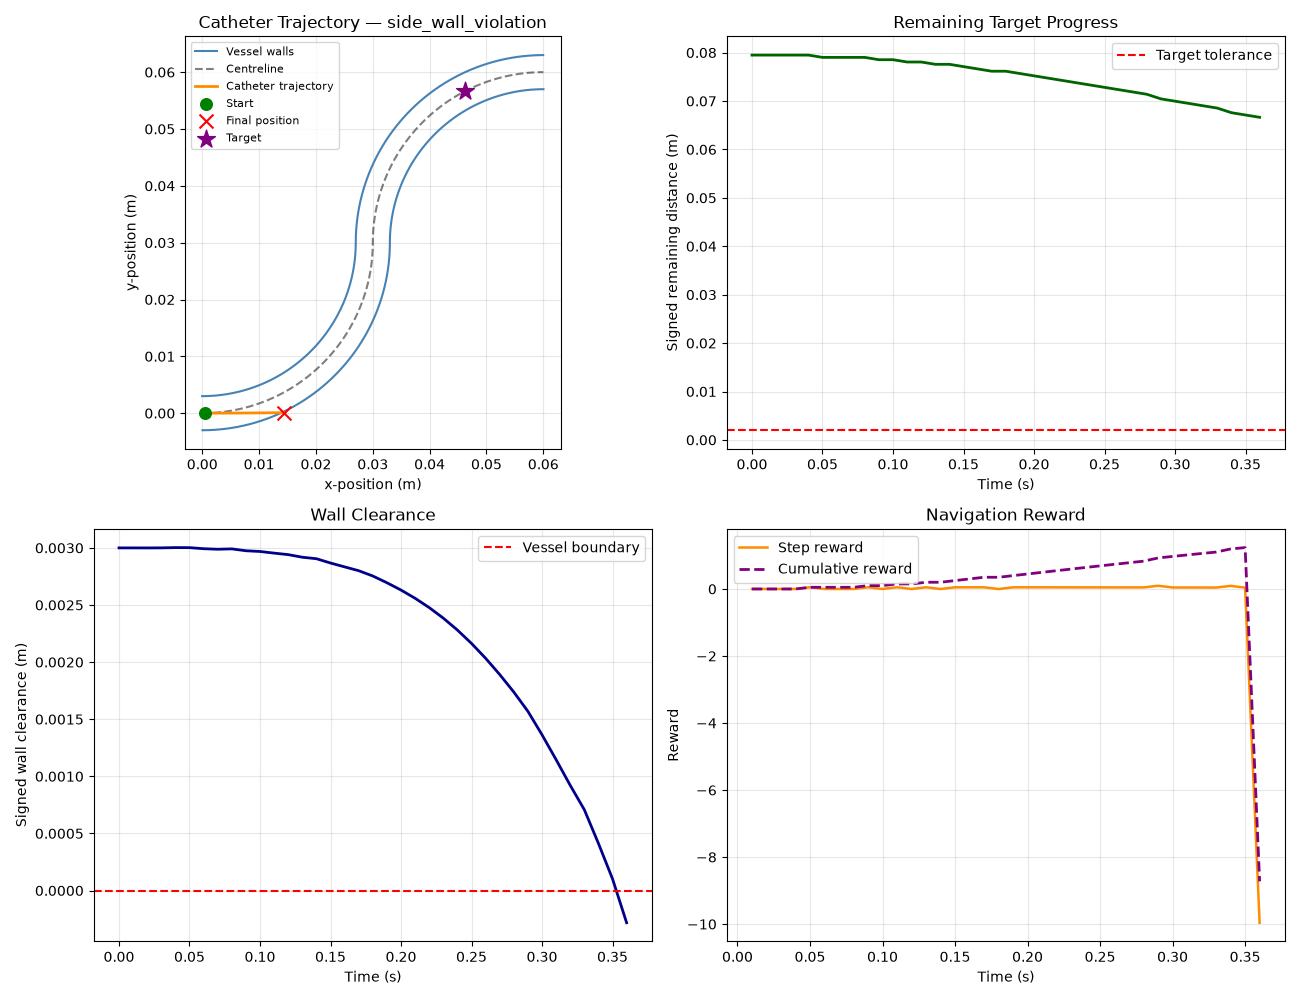

In [24]:

# ============================================================
# VISUALISE CATHETER TRAJECTORY AND NAVIGATION PERFORMANCE
# ============================================================

# Create one figure containing four plots arranged in 2 rows and 2 columns.
fig, axes = plt.subplots(2, 2, figsize=(13, 10))


# ============================================================
# PLOT 1: CATHETER TRAJECTORY WITHIN THE VESSEL
# ============================================================

# Select the plot in the first row, first column.
ax = axes[0, 0]

# Plot the two vessel walls using their x and y coordinates.
# [:, 0] selects all x-coordinates; [:, 1] selects all y-coordinates.
ax.plot(vessel.wall1[:, 0], vessel.wall1[:, 1],
        color="steelblue", label="Vessel walls")

ax.plot(vessel.wall2[:, 0], vessel.wall2[:, 1],
        color="steelblue")

# Plot the vessel centreline as a dashed black line.
ax.plot(vessel.centreline[:, 0], vessel.centreline[:, 1],
        "k--", alpha=0.5, label="Centreline")

# Plot the catheter trajectory using all recorded positions.
ax.plot(states[:, 0], states[:, 1],
        color="darkorange", linewidth=2, label="Catheter trajectory")

# Mark the initial catheter position.
# s controls marker size; zorder=5 places the marker above the plotted lines.
ax.scatter(states[0, 0], states[0, 1],
           color="green", s=70, label="Start", zorder=5)

# Mark the final catheter position with a red cross.
# [-1, 0] selects the last x-position; [-1, 1] selects the last y-position.
ax.scatter(states[-1, 0], states[-1, 1],
           color="red", marker="x", s=100,
           label="Final position", zorder=5)

# Mark the target position with a purple star.
ax.scatter(vessel.target_position[0], vessel.target_position[1],
           color="purple", marker="*", s=180,
           label="Target", zorder=5)

# Add title, axis labels, grid and legend.
ax.set_title(f"Catheter Trajectory — {final_outcome}")
ax.set_xlabel("x-position (m)")
ax.set_ylabel("y-position (m)")

# Maintain equal spatial scaling so the vessel shape is not distorted.
ax.set_aspect("equal")

ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)


# ============================================================
# PLOT 2: REMAINING TARGET PROGRESS
# ============================================================

# Select the plot in the first row, second column.
ax = axes[0, 1]

# Plot the remaining centreline distance to the target against time.
# observations[:, 4] selects the fifth observation component (which is distance to the target, d_target).
ax.plot(times, observations[:, 4],
        color="darkgreen", linewidth=2)

# Draw a horizontal dashed line representing the target tolerance.
# axhline draws a line at the specified y-value.
ax.axhline(env_config.target_tolerance,
           color="red", linestyle="--", label="Target tolerance")

ax.set_title("Remaining Target Progress")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Signed remaining distance (m)")
ax.grid(True, alpha=0.3)
ax.legend()


# ============================================================
# PLOT 3: VESSEL WALL CLEARANCE
# ============================================================

# Select the plot in the second row, first column.
ax = axes[1, 0]

# Plot signed wall clearance against time.
# observations[:, 5] selects the sixth observation component (which is the distance to the vessle wall, d_wall).
# Positive values mean inside the vessel; negative values mean outside.
ax.plot(times, observations[:, 5],
        color="darkblue", linewidth=2)

# Add a horizontal reference line at zero clearance.
# Crossing below this line indicates that the catheter is outside the vessel.
ax.axhline(0.0, color="red",
           linestyle="--", label="Vessel boundary")

ax.set_title("Wall Clearance")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Signed wall clearance (m)")
ax.grid(True, alpha=0.3)
ax.legend()


# ============================================================
# PLOT 4: STEP REWARD AND CUMULATIVE REWARD
# ============================================================

# Select the plot in the second row, second column.
ax = axes[1, 1]

# Plot the reward received after each simulation step.
# times[1:] excludes the initial time because no reward exists at reset.
ax.plot(times[1:], rewards,
        color="darkorange", linewidth=1.8, label="Step reward")

# np.cumsum(rewards) calculates the accumulated reward after each step.
# A dashed line helps distinguish cumulative reward from step reward.
ax.plot(times[1:], np.cumsum(rewards),
        color="purple", linestyle="--",
        linewidth=2, label="Cumulative reward")

ax.set_title("Navigation Reward")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Reward")
ax.grid(True, alpha=0.3)
ax.legend()


# ============================================================
# DISPLAY THE COMPLETED FIGURE
# ============================================================

# Automatically adjust spacing to prevent overlapping labels and titles.
plt.tight_layout()

# Display the figure containing all four plots.
plt.show()


The visualization above shows that so far, the environment behaved as expected this includes
1. Terminating after a wall perforation
2. Reduction in distance to target as the controller takes steps
3. Initially increasing cummulative reward up till the point where the catheter perforates the wall 
4. Decreasing wall clearance as the catheter approaches the vessel walls


### Visualising the Environment Using Gymnasium Rendering

We now extend `CatheterEnv` with optional human-mode rendering. The `render()` method will display the vessel walls, centreline, navigation target and catheter trajectory as the simulation progresses.

Rendering is intended for visual inspection and debugging. It can be disabled during controller training to avoid unnecessary computational overhead.


In [25]:

# ======================================================================
# UPDATE THE CATHETER NAVIGATION ENVIRONMENT WITH RENDERING OPTION
# ======================================================================

class CatheterEnv(gym.Env):
    """Gymnasium environment for catheter navigation using SAC and MPC."""

    # Only human rendering is supported and is limited to 30 frames per second.
    metadata = {"render_modes": ["human"], "render_fps": 30}

    def __init__(self, vessel, config, reward_config, render_mode=None):
        """Initialise vessel geometry, physics, rewards and Gymnasium spaces."""
        super().__init__()

        self.vessel = vessel
        self.config = config
        self.reward_config = reward_config

        # Rendering is optional and supports human mode only.
        if render_mode not in (None, "human"):
            raise ValueError("render_mode must be None or 'human'.")

        self.render_mode = render_mode
        self.fig = None
        self.ax = None
        self.trajectory = []

        # Controller forces [Fx, Fy].
        self.action_space = spaces.Box(
            low=-config.max_force,
            high=config.max_force,
            shape=(2,),
            dtype=np.float32
        )

        # Observations [x, y, vx, vy, d_target, d_wall].
        self.observation_space = spaces.Box(
            low=-np.inf,
            high=np.inf,
            shape=(6,),
            dtype=np.float32
        )

        # Episode state and tracking variables.
        self.state = None
        self.steps = 0
        self.episode_done = False

    def _get_observation(self):
        """
        Construct the six-dimensional observation vector.

        The physical state [x, y, vx, vy] is supplemented with signed
        target progress and signed nearest-wall clearance.
        """
        position = self.state[:2]

        d_target = self.vessel.distance_to_target(position)
        d_wall, _ = self.vessel.wall_clearance(position)

        observation = np.array([
            self.state[0],
            self.state[1],
            self.state[2],
            self.state[3],
            d_target,
            d_wall
        ], dtype=np.float32)

        return observation

    def _calculate_reward(self, previous_d_target, current_d_target,
                          d_wall, local_radius, control_force,
                          success, failure):
        """
        Calculate the navigation reward and its individual components.

        Includes normalised progress, wall proximity, control effort,
        and terminal success or failure rewards.
        """

        # Reward forward centreline progress.
        progress_reward = self.reward_config.progress_weight * (
            (previous_d_target - current_d_target) / self.vessel.length
        )

        # Penalise proximity to the wall, normalised by local radius.
        wall_penalty = np.clip(
            1.0 - d_wall / local_radius, 0.0, 1.0
        )
        wall_reward = -self.reward_config.wall_weight * wall_penalty

        # Penalise large applied forces.
        normalised_force = control_force / self.config.max_force
        control_reward = -self.reward_config.control_weight * np.sum(
            normalised_force**2
        )

        # Reward success or penalise an unsuccessful vessel exit.
        terminal_reward = (
            self.reward_config.success_bonus * success
            - self.reward_config.failure_penalty * failure
        )

        reward = (
            progress_reward + wall_reward
            + control_reward + terminal_reward
        ) #Total reward is the sum of progress, wall, control, and terminal components.

        components = {
            "progress": float(progress_reward),
            "wall": float(wall_reward),
            "control": float(control_reward),
            "terminal": float(terminal_reward)
        } #Describe each reward component for analysis and debugging.

        return float(reward), components

    def reset(self, *, seed=None, options=None):
        """
        Reset the catheter position, velocity and episode counter.

        Optional reset settings:
            initial_position: Starting [x, y] coordinates (m).
            initial_velocity: Starting [vx, vy] velocity (m/s).

        Returns:
            observation: Initial six-dimensional observation.
            info: Initial environment information.
        """
        super().reset(seed=seed)

        if options is None:
            options = {}

        # Default: start just inside the vessel entrance, at rest.
        initial_position = options.get(
            "initial_position", self.vessel.centreline[1]
        )
        initial_velocity = options.get(
            "initial_velocity", [0.0, 0.0]
        )

        # Four-dimensional physical state [x, y, vx, vy].
        self.state = np.concatenate((
            np.asarray(initial_position, dtype=float),
            np.asarray(initial_velocity, dtype=float)
        ))

        if self.state.shape != (4,) or not np.all(np.isfinite(self.state)):
            raise ValueError("Initial state must contain four finite values.")

        _, inside = self.vessel.wall_clearance(self.state[:2])

        if not inside:
            raise ValueError("Initial catheter position must be inside the vessel.")

        self.steps = 0
        self.episode_done = False

        # Begin a new trajectory from the initial catheter position.
        self.trajectory = [self.state[:2].copy()]

        observation = self._get_observation()

        info = {
            "target_position": self.vessel.target_position.copy(),
            "inside_vessel": bool(inside)
        }

        # Display the initial catheter position when rendering is enabled.
        if self.render_mode == "human":
            self.render()

        return observation, info

    def step(self, action):
        """
        Advance catheter dynamics by one timestep using RK45.

        Classifies vessel-boundary crossings before determining success,
        termination, truncation and the navigation reward.

        Returns:
            observation: Updated six-dimensional observation.
            reward: Scalar navigation reward.
            terminated: Whether success or a vessel exit occurred.
            truncated: Whether the episode time limit was reached.
            info: Navigation outcome, geometry and reward breakdown.
        """

        if self.state is None or self.episode_done:
            raise RuntimeError("Call reset() before stepping a new episode.")

        # Validate the applied control forces.
        action = np.asarray(action, dtype=float)

        if action.shape != (2,) or not np.all(np.isfinite(action)):
            raise ValueError("Action must contain two finite force values.")

        if not self.action_space.contains(action.astype(np.float32)):
            raise ValueError("Action exceeds the configured force limits.")

        # Record the position and target progress before integration.
        previous_position = self.state[:2].copy()
        previous_d_target = self.vessel.distance_to_target(previous_position)

        # Integrate the four-dimensional physical state using RK45.
        self.state = integrate_catheter(
            self.state,
            action,
            self.config.dt,
            self.vessel.centreline,
            self.vessel.s,
            self.vessel.local_radius,
            self.config.max_flow_speed,
            self.config.mass,
            self.config.blood_density,
            self.config.drag_coefficient,
            self.config.reference_area,
            rtol=self.config.rtol,
            atol=self.config.atol
        )

        self.steps += 1

        # Save the updated catheter position for trajectory visualisation.
        self.trajectory.append(self.state[:2].copy())

        # Evaluate geometry at the updated catheter position.
        position = self.state[:2]
        d_target = self.vessel.distance_to_target(position)
        d_wall, inside = self.vessel.wall_clearance(position)

        # Identify the first boundary crossed during this timestep.
        boundary_crossing = self.vessel.classify_boundary_crossing(
            previous_position, position
        )

        # Determine the local vessel radius.
        _, _, nearest_index = centreline_distance(
            position, self.vessel.centreline
        )
        local_radius = self.vessel.local_radius[nearest_index]

        # A boundary crossing takes precedence over target success.
        vessel_exit = bool(boundary_crossing is not None or not inside)

        success = bool(
            not vessel_exit
            and inside
            and d_target <= self.config.target_tolerance
        )

        terminated = bool(success or vessel_exit)

        truncated = bool(
            self.steps >= self.config.max_episode_steps
            and not terminated
        )

        # Record the specific navigation outcome.
        if boundary_crossing is not None:
            outcome = boundary_crossing
        elif not inside:
            outcome = "unclassified_exit"
        elif success:
            outcome = "success"
        elif truncated:
            outcome = "time_limit"
        else:
            outcome = "ongoing"

        self.episode_done = terminated or truncated

        # Calculate reward using the class's reward method.
        reward, reward_components = self._calculate_reward(
            previous_d_target=previous_d_target,
            current_d_target=d_target,
            d_wall=d_wall,
            local_radius=local_radius,
            control_force=action,
            success=success,
            failure=vessel_exit
        )

        observation = self._get_observation()

        info = {
            "outcome": outcome,
            "is_success": success,
            "inside_vessel": bool(inside),
            "boundary_crossing": boundary_crossing,
            "target_progress": float(d_target),
            "wall_clearance": float(d_wall),
            "reward_components": reward_components
        }

        # Update the figure after advancing the simulation.
        if self.render_mode == "human":
            self.render()

        return observation, reward, terminated, truncated, info

    def render(self):
        """
        Display the vessel geometry, target and catheter trajectory.

        In human mode, an existing Matplotlib figure is updated after
        each timestep rather than creating a new figure.
        """

        if self.render_mode != "human" or self.state is None:
            return

        # Create the figure only on the first rendering call.
        if self.fig is None:
            self.fig, self.ax = plt.subplots(figsize=(8, 7))

        # Clear the previous frame before drawing the updated state.
        self.ax.clear()

        # Plot both vessel walls.
        self.ax.plot(
            self.vessel.wall1[:, 0],
            self.vessel.wall1[:, 1],
            color="steelblue",
            label="Vessel walls"
        )

        self.ax.plot(
            self.vessel.wall2[:, 0],
            self.vessel.wall2[:, 1],
            color="steelblue"
        )

        # Plot the dashed vessel centreline.
        self.ax.plot(
            self.vessel.centreline[:, 0],
            self.vessel.centreline[:, 1],
            "k--",
            alpha=0.5,
            label="Centreline"
        )

        # Mark the navigation target.
        self.ax.scatter(
            self.vessel.target_position[0],
            self.vessel.target_position[1],
            color="purple",
            marker="*",
            s=180,
            label="Target",
            zorder=5
        )

        # Convert the recorded positions into an array of [x, y] coordinates.
        trajectory = np.asarray(self.trajectory)

        # Draw the path travelled by the catheter so far.
        self.ax.plot(
            trajectory[:, 0],
            trajectory[:, 1],
            color="darkorange",
            linewidth=2,
            label="Catheter trajectory"
        )

        # Mark the starting position.
        self.ax.scatter(
            trajectory[0, 0],
            trajectory[0, 1],
            color="green",
            s=65,
            label="Start",
            zorder=5
        )

        # Mark the current catheter position.
        self.ax.scatter(
            self.state[0],
            self.state[1],
            color="red",
            s=65,
            label="Catheter",
            zorder=6
        )

        # Configure the axes and display the current simulation step.
        self.ax.set_title(f"Catheter Navigation — Step {self.steps}")
        self.ax.set_xlabel("x-position (m)")
        self.ax.set_ylabel("y-position (m)")
        self.ax.set_aspect("equal")
        self.ax.grid(True, alpha=0.3)
        self.ax.legend(fontsize=8)

        # Request a redraw of the existing interactive figure..
        self.fig.canvas.draw_idle()


    def close(self):
        """Close the Matplotlib figure and release rendering resources."""

        if self.fig is not None:
            plt.close(self.fig)

        self.fig = None
        self.ax = None

Final outcome: side_wall_violation
Number of steps: 36
Recorded trajectory points: 37


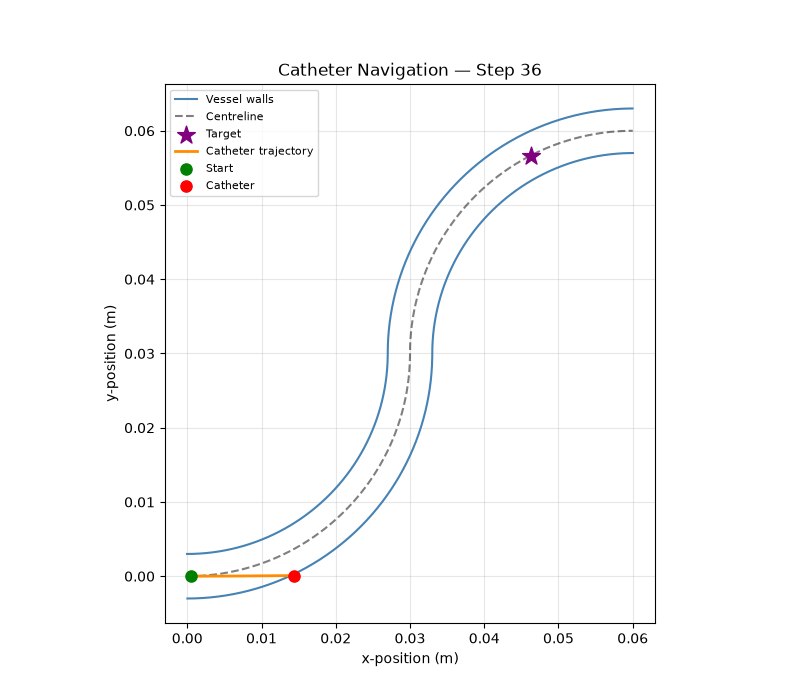

In [ ]:

# ============================================================
# TEST HUMAN-MODE RENDERING
# ============================================================

render_env = CatheterEnv(
    vessel=vessel,
    config=env_config,
    reward_config=reward_config,
    render_mode="human"
)

# Reuse the constant-force policy and episode runner defined earlier.
render_history, render_outcome = run_episode(
    render_env, constant_force_policy, seed=42
)

print("Final outcome:", render_outcome)
print("Number of steps:", render_env.steps)
print("Recorded trajectory points:", len(render_env.trajectory))


render_env.close()



### Numerical Validation: Timestep Convergence

With rendering now included in the environment, we now perform further testing of the environment to ensure that it functions as expected. 

First, we investigate whether the simulated catheter trajectory remains consistent as the environment timestep, $\Delta t$, is reduced.

Using the same initial state, constant control force and simulation duration, we compare results for several timestep sizes. All other physical and numerical parameters remain unchanged.

We evaluate differences in catheter position and velocity relative to the smallest timestep. Consistent results indicate that the simulation result are not significantly affected by the timestep we choose. It will also help us determine that the choosen timestep is sufficiently small and appropriate. 


Reference timestep: 0.0025 s
Reference final state: [0.00484 0.00002 0.04336 0.00023]

dt (s)      Steps     Position error (m)    Velocity error (m/s)
0.0200      10        1.23409652e-08        3.60958609e-07
0.0100      20        2.62236096e-08        5.15556556e-08
0.0050      40        2.27277548e-08        5.05726394e-07
0.0025      80        0.00000000e+00        0.00000000e+00


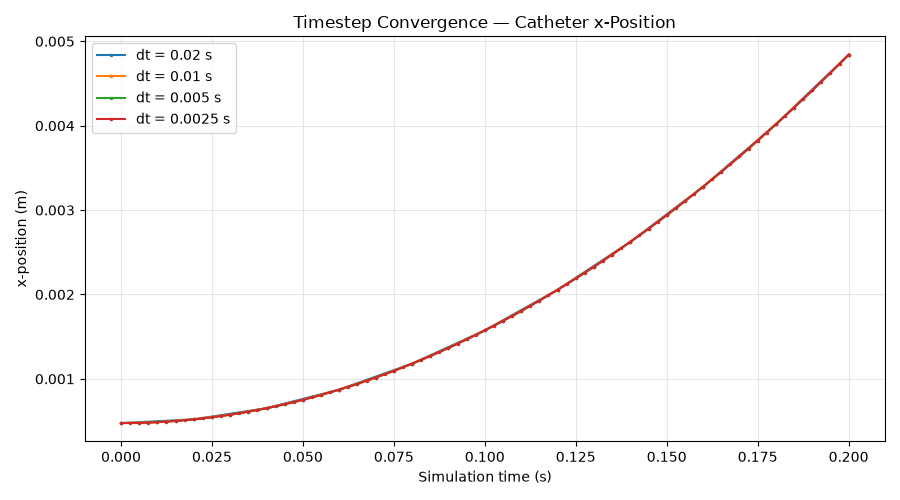

In [27]:

# ============================================================
# NUMERICAL VALIDATION: TIMESTEP CONVERGENCE
# ============================================================

# Test different timesteps while keeping the simulation duration fixed.
dt_values = [0.02, 0.01, 0.005, 0.0025]
simulation_duration = 0.20

# Use the same control force and initial state in every simulation.
test_action = np.array([0.0002, 0.0], dtype=np.float32)
initial_state = np.concatenate((
    vessel.centreline[1],
    np.array([0.0, 0.0])
))


def simulate_fixed_duration(dt):
    """
    Integrate the catheter dynamics over a fixed physical duration.

    Returns:
        times: Recorded simulation times.
        states: Recorded four-dimensional physical states.
    """

    # Determine how many timesteps are required.
    num_steps = round(simulation_duration / dt)

    # Confirm that the timestep divides the duration exactly.
    if not np.isclose(num_steps * dt, simulation_duration):
        raise ValueError("Timestep must divide the simulation duration.")

    state = initial_state.copy()

    times = [0.0]
    states = [state.copy()]

    for step in range(num_steps):

        # Integrate using the same physics and RK45 tolerances.
        state = integrate_catheter(
            state,
            test_action,
            dt,
            vessel.centreline,
            vessel.s,
            vessel.local_radius,
            env_config.max_flow_speed,
            env_config.mass,
            env_config.blood_density,
            env_config.drag_coefficient,
            env_config.reference_area,
            rtol=env_config.rtol,
            atol=env_config.atol
        )

        # Record the state after each timestep.
        times.append((step + 1) * dt)
        states.append(state.copy())

    return np.array(times), np.array(states)


# Run the simulation separately for each timestep.
results = {}

for dt in dt_values:
    times_dt, states_dt = simulate_fixed_duration(dt)

    results[dt] = {
        "time": times_dt,
        "state": states_dt
    }


# Use the smallest timestep as the numerical reference. 
# This is expected to be the most accurate solution for comparison due to smaller timesteps. 
reference_dt = min(dt_values)
reference_state = results[reference_dt]["state"][-1]

print("Reference timestep:", reference_dt, "s")
print("Reference final state:", reference_state)
print()

print(f"{'dt (s)':<12}{'Steps':<10}{'Position error (m)':<22}{'Velocity error (m/s)'}")

for dt in dt_values:

    final_state = results[dt]["state"][-1]

    # Compare final position and velocity against the reference run.
    position_error = np.linalg.norm(
        final_state[:2] - reference_state[:2]
    )

    velocity_error = np.linalg.norm(
        final_state[2:] - reference_state[2:]
    )

    print(
        f"{dt:<12.4f}"
        f"{len(results[dt]['time']) - 1:<10}"
        f"{position_error:<22.8e}"
        f"{velocity_error:.8e}"
    )


# Plot the x-position over the same physical time interval.
plt.figure(figsize=(9, 5))

for dt in dt_values:
    plt.plot(
        results[dt]["time"],
        results[dt]["state"][:, 0],
        marker=".",
        markersize=3,
        label=f"dt = {dt} s"
    )

plt.title("Timestep Convergence — Catheter x-Position")
plt.xlabel("Simulation time (s)")
plt.ylabel("x-position (m)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()



### Numerical Validation: RK45 Tolerance Sensitivity

The timestep convergence test showed negligible differences in catheter position and velocity across the tested timesteps, supporting the use of $\Delta t=0.01$ s under the examined conditions.

We now investigate the sensitivity of the adaptive Runge–Kutta (RK45) solver to its relative tolerance (`rtol`) and absolute tolerance (`atol`). Keeping the timestep, initial state, control force and simulation duration fixed, we compare several tolerance settings against a tighter numerical reference to assess whether our current settings provide sufficient accuracy.

Reference: Tight RK45 tolerances
Reference final state: [0.00484 0.00002 0.04336 0.00023]

Setting     rtol        atol        Position error (m)    Velocity error (m/s)
Loose       1.0e-03     1.0e-06     9.08675482e-08        2.42425576e-06
Moderate    1.0e-05     1.0e-08     6.20639003e-08        1.50644867e-06
Current     1.0e-06     1.0e-09     7.08610014e-09        6.70805903e-08
Tight       1.0e-09     1.0e-12     0.00000000e+00        0.00000000e+00


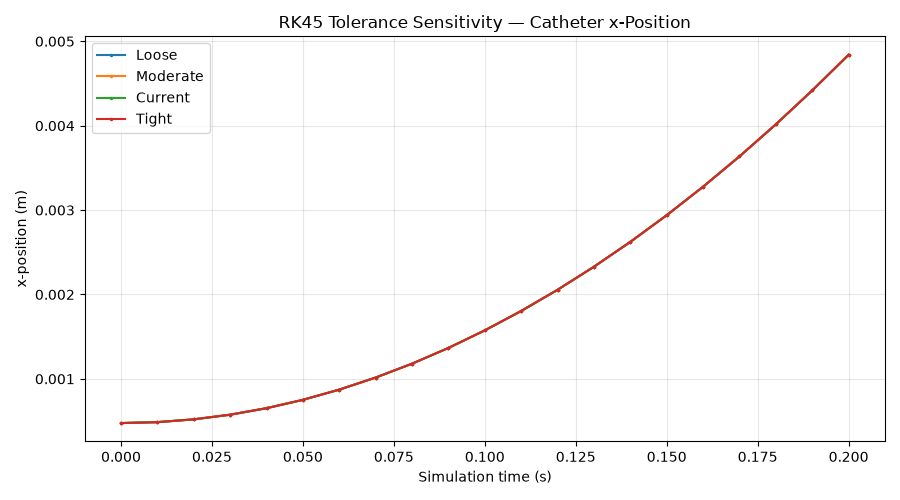

In [28]:

# ============================================================
# NUMERICAL VALIDATION: RK45 TOLERANCE SENSITIVITY
# ============================================================

# Define the relative and absolute tolerance configurations to be tested. 
tolerance_settings = {
    "Loose":    (1e-3, 1e-6),
    "Moderate": (1e-5, 1e-8),
    "Current":  (1e-6, 1e-9),
    "Tight":    (1e-9, 1e-12)
}

# Keep the timestep, simulation duration and control force unchanged.
dt = env_config.dt
simulation_duration = 0.20
test_action = np.array([0.0002, 0.0], dtype=np.float32)

# Start from the same initial physical state for every simulation.
initial_state = np.concatenate((
    vessel.centreline[1],
    np.array([0.0, 0.0])
))


def simulate_with_tolerances(rtol, atol):
    """
    Simulate catheter motion using specified RK45 error tolerances.

    Returns:
        times: Simulation time points.
        states: Recorded four-dimensional physical states.
    """

    # Calculate the number of environment timesteps.
    num_steps = round(simulation_duration / dt)

    if not np.isclose(num_steps * dt, simulation_duration):
        raise ValueError("Timestep must divide the simulation duration.")

    state = initial_state.copy()
    times = [0.0]
    states = [state.copy()]

    for step in range(num_steps):

        # Use the existing integrator, changing only RK45 tolerances.
        state = integrate_catheter(
            state,
            test_action,
            dt,
            vessel.centreline,
            vessel.s,
            vessel.local_radius,
            env_config.max_flow_speed,
            env_config.mass,
            env_config.blood_density,
            env_config.drag_coefficient,
            env_config.reference_area,
            rtol=rtol,
            atol=atol
        )

        # Record the updated state and corresponding simulation time.
        times.append((step + 1) * dt)
        states.append(state.copy())

    return np.array(times), np.array(states)


# Run one simulation for each tolerance configuration.
tolerance_results = {}

for name, (rtol, atol) in tolerance_settings.items():
    times_tol, states_tol = simulate_with_tolerances(rtol, atol)

    tolerance_results[name] = {
        "time": times_tol,
        "state": states_tol
    }


# Use the tightest tolerance configuration as the numerical reference.
reference_state = tolerance_results["Tight"]["state"][-1]

print("Reference: Tight RK45 tolerances")
print("Reference final state:", reference_state)
print()

print(
    f"{'Setting':<12}{'rtol':<12}{'atol':<12}"
    f"{'Position error (m)':<22}{'Velocity error (m/s)'}"
)

for name, (rtol, atol) in tolerance_settings.items():

    final_state = tolerance_results[name]["state"][-1]

    # Calculate Euclidean differences from the tight reference.
    position_error = np.linalg.norm(
        final_state[:2] - reference_state[:2]
    )

    velocity_error = np.linalg.norm(
        final_state[2:] - reference_state[2:]
    )

    print(
        f"{name:<12}{rtol:<12.1e}{atol:<12.1e}"
        f"{position_error:<22.8e}{velocity_error:.8e}"
    )


# Compare the calculated x-position trajectories.
plt.figure(figsize=(9, 5))

for name in tolerance_settings:
    plt.plot(
        tolerance_results[name]["time"],
        tolerance_results[name]["state"][:, 0],
        marker=".",
        markersize=3,
        label=name
    )

plt.title("RK45 Tolerance Sensitivity — Catheter x-Position")
plt.xlabel("Simulation time (s)")
plt.ylabel("x-position (m)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()



### Numerical Validation: Vessel Sampling Convergence

The RK45 tolerance sensitivity test showed negligible differences in catheter motion, supporting the existing tolerances of `rtol=1e-6` and `atol=1e-9` under the tested conditions.

We now examine whether increasing the number of sampled centreline points improves the consistency of the vessel geometry calculations. Using the same S-shaped vessel dimensions and fixed catheter test positions, we will compare target progress, wall clearance and local vessel directions across different sampling resolutions. This will help determine whether our current geometric resolution is sufficiently accurate.


Reference sampling: 2000 points per arc
Test positions (m):
[[0.01764 0.00574]
 [0.03    0.03   ]
 [0.0388  0.05122]]

Points/arc    Max wall error (m)    Max target error (m)    Max direction error (deg)
50            3.28236428e-05        7.50881013e-04          0.89585609
100           7.66598860e-06        3.62034749e-04          0.43203420
200           1.70452346e-06        1.70607522e-04          0.20361940
500           1.88302328e-07        5.66939551e-05          0.06766911
1000          2.08811998e-08        1.88785883e-05          0.02253379
2000          0.00000000e+00        0.00000000e+00          0.00000085


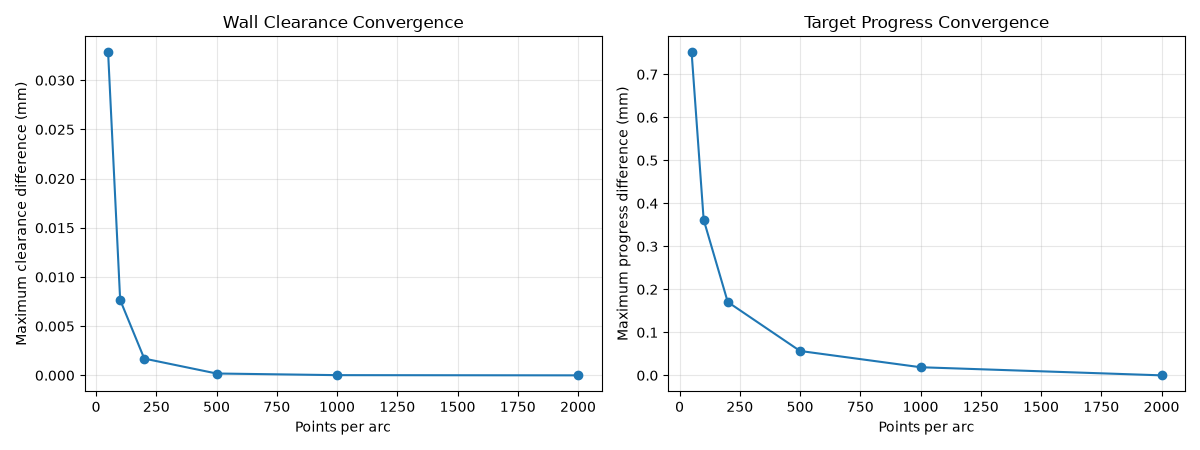

In [29]:

# ============================================================
# NUMERICAL VALIDATION: VESSEL SAMPLING CONVERGENCE
# ============================================================

# Number of sampled points per S-vessel arc.
sampling_values = [50, 100, 200, 500, 1000, 2000]
reference_sampling = max(sampling_values)

# Select fixed physical positions using fractions of a fine centreline.
reference_config = replace(config, num_points=reference_sampling)

reference_vessel = SVessel(
    config=reference_config,
    width_profile=constant_width,
    radius=vessel_radius,
    target_fraction=0.85
)

# Use the same three positions for every sampling resolution.
test_fractions = [0.20, 0.50, 0.75]

test_positions = np.array([
    reference_vessel.centreline[
        np.argmin(np.abs(reference_vessel.s - fraction * reference_vessel.length))
    ]
    for fraction in test_fractions
])


def evaluate_geometry(test_vessel, positions):
    """
    Evaluate vessel geometry at fixed catheter positions.

    Returns arrays of target progress, wall clearance and
    local unit flow direction for each position.
    """

    target_progress = []
    wall_clearances = []
    flow_directions = []

    for position in positions:

        # Signed remaining centreline distance to the target.
        target_progress.append(
            test_vessel.distance_to_target(position)
        )

        # Signed distance to the nearest sampled vessel-wall point.
        d_wall, inside = test_vessel.wall_clearance(position)

        if not inside:
            raise ValueError("A test position is outside the vessel.")

        wall_clearances.append(d_wall)

        # Local unit tangent, which determines blood-flow direction.
        flow_directions.append(
            test_vessel.flow_direction(position)
        )

    return {
        "target": np.array(target_progress),
        "wall": np.array(wall_clearances),
        "direction": np.array(flow_directions)
    }


# Evaluate all sampling resolutions using identical test positions.
sampling_results = {}

for num_points in sampling_values:

    # Change only the number of points used to generate each arc.
    test_config = replace(config, num_points=num_points)

    test_vessel = SVessel(
        config=test_config,
        width_profile=constant_width,
        radius=vessel_radius,
        target_fraction=0.85
    )

    sampling_results[num_points] = evaluate_geometry(
        test_vessel, test_positions
    )


# Compare geometric measurements against the finest resolution.
reference = sampling_results[reference_sampling]

print("Reference sampling:", reference_sampling, "points per arc")
print("Test positions (m):")
print(test_positions)
print()

print(
    f"{'Points/arc':<14}"
    f"{'Max wall error (m)':<22}"
    f"{'Max target error (m)':<24}"
    f"{'Max direction error (deg)'}"
)

wall_errors = []
target_errors = []
direction_errors = []

for num_points in sampling_values:

    result = sampling_results[num_points]

    # Largest absolute difference in wall clearance across test positions.
    wall_error = np.max(
        np.abs(result["wall"] - reference["wall"])
    )

    # Largest absolute difference in signed target progress.
    target_error = np.max(
        np.abs(result["target"] - reference["target"])
    )

    # Angle between local flow-direction vectors and reference vectors.
    dot_products = np.sum(
        result["direction"] * reference["direction"], axis=1
    )

    direction_angles = np.degrees(
        np.arccos(np.clip(dot_products, -1.0, 1.0))
    )

    direction_error = np.max(direction_angles)

    wall_errors.append(wall_error)
    target_errors.append(target_error)
    direction_errors.append(direction_error)

    print(
        f"{num_points:<14}"
        f"{wall_error:<22.8e}"
        f"{target_error:<24.8e}"
        f"{direction_error:.8f}"
    )


# Plot the two most important geometric errors against sampling resolution.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Convert metre-based errors into millimetres for easier interpretation.
axes[0].plot(sampling_values, np.array(wall_errors) * 1000, "o-")
axes[0].set_title("Wall Clearance Convergence")
axes[0].set_xlabel("Points per arc")
axes[0].set_ylabel("Maximum clearance difference (mm)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(sampling_values, np.array(target_errors) * 1000, "o-")
axes[1].set_title("Target Progress Convergence")
axes[1].set_xlabel("Points per arc")
axes[1].set_ylabel("Maximum progress difference (mm)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



#### Vessel Sampling Convergence: Findings

The sampling convergence test showed decreasing errors in wall clearance, target progress and local vessel direction as the number of centreline points increased.

At 100 points per arc, wall-clearance and direction errors were small, but the maximum target-progress difference was approximately 0.362 mm. Increasing to 500 points per arc reduced this difference to approximately 0.056 mm and improved the other geometric measurements.

We therefore provisionally adopt **500 points per arc** for subsequent simulations, subject to computational performance checks.


In [30]:

# ============================================================
# UPDATE S-VESSEL SAMPLING RESOLUTION to 500 POINTS PER ARC
# ============================================================

# Create a new vessel configuration with 500 points per arc.
# All other geometric parameters remain unchanged.
config = replace(config, num_points=500)

# Regenerate the vessel using the updated sampling resolution.
vessel = SVessel(
    config=config,
    width_profile=constant_width,
    radius=vessel_radius,
    target_fraction=0.85
)

# Recreate the environment using the updated vessel geometry.
env = CatheterEnv(
    vessel=vessel,
    config=env_config,
    reward_config=reward_config
)

observation, info = env.reset(seed=42)

print("Points per arc:", config.num_points)
print("Total centreline points:", len(vessel.centreline))
print(f"Vessel length: {vessel.length:.6f} m")
print("Target position:", vessel.target_position)
print("Initial catheter state:", env.state)
print("Observation valid:", env.observation_space.contains(observation))


Points per arc: 500
Total centreline points: 999
Vessel length: 0.094248 m
Target position: [0.04636 0.05672]
Initial catheter state: [0.00009 0.      0.      0.     ]
Observation valid: True



### Final Gymnasium Environment Validation

The S-shaped catheter environment has passed initial tests of its dynamics, rewards, termination conditions and numerical sensitivity.  We now use Gymnasium's built-in environment checker to verify compliance with the Gymnasium API, including action and observation spaces, reset behaviour, step outputs and reproducibility. This is an interface validation rather than a guarantee of physical accuracy or controller performance.


In [33]:

# ============================================================
# FINAL GYMNASIUM ENVIRONMENT VALIDATION
# ============================================================

# Create a fresh environment with rendering disabled for testing.
check_environment = CatheterEnv(
    vessel=vessel,
    config=env_config,
    reward_config=reward_config,
    render_mode=None
)

# Run Gymnasium's built-in API and environment consistency checks.
check_env(check_environment, skip_render_check=True)

print("Gymnasium environment checker: PASSED")

# Verify that resetting with the same seed reproduces the initial state.
observation_1, info_1 = check_environment.reset(seed=42)
observation_2, info_2 = check_environment.reset(seed=42)

assert np.array_equal(observation_1, observation_2)
print("Reset reproducibility: PASSED")

# Verify observation shape, type and declared observation-space bounds.
assert observation_2.shape == (6,)
assert check_environment.observation_space.contains(observation_2)
print("Observation-space validation: PASSED")

# Test a valid action and the standard five-element step output.
action = np.zeros(2, dtype=np.float32)

observation, reward, terminated, truncated, info = (
    check_environment.step(action)
)

assert check_environment.observation_space.contains(observation)
assert isinstance(reward, (float, np.floating))
assert isinstance(terminated, (bool, np.bool_))
assert isinstance(truncated, (bool, np.bool_))
assert isinstance(info, dict)

print("Step output validation: PASSED")

# Check that the recorded reward components sum to the total reward.
components = info["reward_components"]

assert np.isclose(
    reward,
    sum(components.values())
)

print("Reward consistency: PASSED")

# Verify that an invalid force is rejected.
invalid_action = np.array(
    [2 * env_config.max_force, 0.0],
    dtype=np.float32
)

try:
    check_environment.step(invalid_action)
except ValueError:
    print("Invalid-action rejection: PASSED")
else:
    raise AssertionError("Environment accepted an invalid action.")

# Release any resources used by the environment.
check_environment.close()

print("\nFinal Gymnasium API validation completed.")


Gymnasium environment checker: PASSED
Reset reproducibility: PASSED
Observation-space validation: PASSED
Step output validation: PASSED
Reward consistency: PASSED
Invalid-action rejection: PASSED

Final Gymnasium API validation completed.


c:\Users\kizit\anaconda3\envs\CONTROL\Lib\site-packages\gymnasium\utils\env_checker.py:317: UserWarning: WARN: A Box observation space minimum value is -infinity. This is probably too low.
  logger.warn(
c:\Users\kizit\anaconda3\envs\CONTROL\Lib\site-packages\gymnasium\utils\env_checker.py:321: UserWarning: WARN: A Box observation space maximum value is infinity. This is probably too high.
  logger.warn(



## Stage 7 - Control Feasibility and task difficulty. 

Here we will train a simple RL algorithm to verify the an RL controller can actually navigate to the target. 

## Preliminary Reinforcement Learning Feasibility Test

Having developed and validated the S-shaped catheter navigation environment, we now investigate whether a reinforcement learning agent can learn to navigate it successfully.

We will train a Soft Actor-Critic (SAC) agent using Stable-Baselines3 with default hyperparameters, without systematic tuning. Training will use the deterministic, constant-width S-shaped environment. We will then evaluate navigation success, vessel-wall violations, time to target and accumulated reward across multiple episodes.

This preliminary experiment assesses whether the environment is learnable using RL; it is not intended as the final SAC–MPC performance comparison.


In [ ]:

# ============================================================
# PRELIMINARY SAC TRAINING: SETUP AND COMPATIBILITY CHECK
# ============================================================

# Create a fresh deterministic environment for SAC training.
# Rendering is disabled to avoid slowing down training.
train_env = CatheterEnv(
    vessel=vessel,
    config=env_config,
    reward_config=reward_config,
    render_mode=None
)

# Check compatibility with Stable-Baselines3.
# This checks the observation/action spaces and Gymnasium API.
sb3_check_env(train_env, warn=True)

# Reset the environment and inspect its initial observation.
observation, info = train_env.reset(seed=42)

# Sample one valid action to confirm the action-space configuration.
sample_action = train_env.action_space.sample()

print("Stable-Baselines3 version:", sb3.__version__)
print("SAC environment compatibility: PASSED")
print("Observation space:", train_env.observation_space)
print("Action space:", train_env.action_space)
print("Initial observation:", observation)
print("Sample action:", sample_action)
print("Action within limits:", train_env.action_space.contains(sample_action))
print("Episode step limit:", train_env.config.max_episode_steps)


c:\Users\kizit\anaconda3\envs\CONTROL\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


Stable-Baselines3 version: 2.9.0
SAC environment compatibility: PASSED
Observation space: Box(-inf, inf, (6,), float32)
Action space: Box(-0.001, 0.001, (2,), float32)
Initial observation: [0.00009 0.      0.      0.      0.07999 0.003  ]
Sample action: [0.00019 0.00095]
Action within limits: True
Episode step limit: 1000


c:\Users\kizit\anaconda3\envs\CONTROL\Lib\site-packages\stable_baselines3\common\env_checker.py:515: UserWarning: We recommend you to use a symmetric and normalized Box action space (range=[-1, 1]) cf. https://stable-baselines3.readthedocs.io/en/master/guide/rl_tips.html
  warnings.warn(



The environment passed the Stable-Baselines3 compatibility check, confirming that its observation space, action space and Gymnasium interface are suitable for SAC training. 
The warnings, I understand, will not prevent training.


In [35]:

# =======================================================================
# PRELIMINARY SAC TRAINING: TRAIN FOR 50,000 ENVIRONMENT INTERACTIONS
# =======================================================================

# Number of environment interactions for the initial experiment.
training_timesteps = 50_000

# Initialise SAC using its default learning hyperparameters. 
# We use the MLP (multi-layer perceptron nework) policy for this simple continuous control tasks.

sac_model = SAC(
    policy="MlpPolicy",
    env=train_env,
    seed=42,
    verbose=1
)

# Train the agent on the deterministic S-shaped vessel.
sac_model.learn(
    total_timesteps=training_timesteps,
    log_interval=10
)

print("\nSAC preliminary training completed.")
print("Total training timesteps:", sac_model.num_timesteps)


Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 6.7      |
|    ep_rew_mean     | -9.99    |
|    success_rate    | 0        |
| time/              |          |
|    episodes        | 10       |
|    fps             | 102      |
|    time_elapsed    | 0        |
|    total_timesteps | 67       |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 15.6     |
|    ep_rew_mean     | -9.62    |
|    success_rate    | 0        |
| time/              |          |
|    episodes        | 20       |
|    fps             | 49       |
|    time_elapsed    | 6        |
|    total_timesteps | 312      |
| train/             |          |
|    actor_loss      | -2.11    |
|    critic_loss     | 9.9      |
|    ent_coef        | 0.939    |
|    ent_coef_loss   | -0.207   |
|    learning_rate   |


SAC completed 50,000 training timesteps, with mean episode rewards improving from approximately −9.99 to −4.84, suggesting some learning. 
However, the reported success rate remained at 0%, indicating that successful navigation had not yet been achieved.


In [ ]:

# ============================================================
# PRELIMINARY SAC EVALUATION: ASSESS NAVIGATION PERFORMANCE
# ============================================================

#Here we evaluate the trained SAC agent over multiple episodes to assess its navigation performance.
n_eval_episodes = 20

# Create a separate environment for evaluation.
eval_env = CatheterEnv(
    vessel=vessel,
    config=env_config,
    reward_config=reward_config,
    render_mode=None
)

evaluation_results = [] #Create a list to store evaluation results for each episode.

for episode in range(n_eval_episodes): #Evaluate the trained SAC agent over multiple episodes.

    observation, info = eval_env.reset(seed=100 + episode)

    episode_reward = 0.0
    terminated = False
    truncated = False

    while not (terminated or truncated):

        # Use the learned policy to select an action based on the current observation.
        action, _ = sac_model.predict(
            observation,
            deterministic=True
        )

        # Step the environment using the selected action and receive the next observation, reward, and episode status.
        observation, reward, terminated, truncated, info = (
            eval_env.step(action)
        ) 

        episode_reward += reward

    # Record the final navigation outcome and episode statistics.
    evaluation_results.append({
        "episode": episode + 1,
        "outcome": info["outcome"],
        "steps": eval_env.steps,
        "reward": episode_reward,
        "remaining_distance": observation[4],
        "wall_clearance": observation[5]
    })

eval_env.close()

# Summarise performance across evaluation episodes.
outcomes = [result["outcome"] for result in evaluation_results]

success_count = outcomes.count("success") #Count the number of successful episodes.
success_rate = success_count / n_eval_episodes #Calculate the success rate as a fraction of total episodes.

print("PRELIMINARY SAC EVALUATION")
print("-" * 40)
print(f"Evaluation episodes: {n_eval_episodes}")
print(f"Successful episodes: {success_count}")
print(f"Success rate: {success_rate:.1%}")
print(f"Mean episode length: {np.mean([r['steps'] for r in evaluation_results]):.1f}")
print(f"Mean episode reward: {np.mean([r['reward'] for r in evaluation_results]):.4f}")

print("\nOutcome distribution:")
for outcome in sorted(set(outcomes)):
    print(f"  {outcome}: {outcomes.count(outcome)}")

print("\nFirst five evaluation episodes:")
for result in evaluation_results[:5]:
    print(result)


PRELIMINARY SAC EVALUATION
----------------------------------------
Evaluation episodes: 20
Successful episodes: 0
Success rate: 0.0%
Mean episode length: 145.0
Mean episode reward: -5.1317

Outcome distribution:
  side_wall_violation: 20

First five evaluation episodes:
{'episode': 1, 'outcome': 'side_wall_violation', 'steps': 145, 'reward': -5.131659360485838, 'remaining_distance': np.float32(0.02899204), 'wall_clearance': np.float32(-3.504296e-05)}
{'episode': 2, 'outcome': 'side_wall_violation', 'steps': 145, 'reward': -5.131659360485838, 'remaining_distance': np.float32(0.02899204), 'wall_clearance': np.float32(-3.504296e-05)}
{'episode': 3, 'outcome': 'side_wall_violation', 'steps': 145, 'reward': -5.131659360485838, 'remaining_distance': np.float32(0.02899204), 'wall_clearance': np.float32(-3.504296e-05)}
{'episode': 4, 'outcome': 'side_wall_violation', 'steps': 145, 'reward': -5.131659360485838, 'remaining_distance': np.float32(0.02899204), 'wall_clearance': np.float32(-3.50429


Deterministic evaluation over 20 episodes produced a 0% success rate, with every episode terminating in a side-wall violation after 145 steps. The catheter nevertheless covered approximately 64% of the initial centreline distance to the target, indicating substantial forward progress without successful navigation.

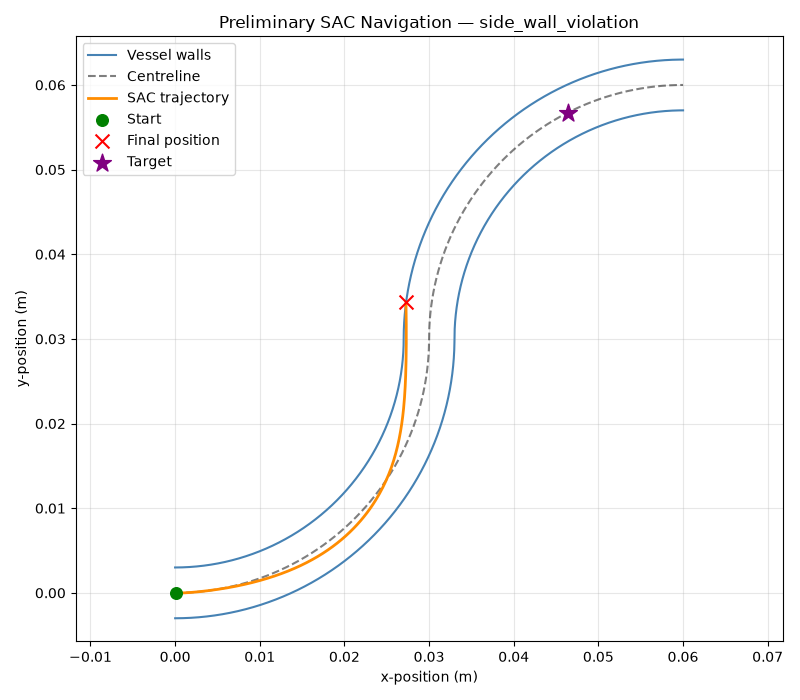

Final outcome: side_wall_violation
Final position: [0.02727 0.03432]
Final velocity: [-0.0006   0.03899]
Maximum absolute force: 0.0009908805 N


In [ ]:

# ============================================================
# PRELIMINARY SAC EVALUATION:VISUALISE LEARNED SAC NAVIGATION TRAJECTORY
# ============================================================

# The goal here is to visualise the catheter's trajectory when controlled by the trained SAC policy.
# We will run a single episode, record and visualize the catheter's position, applied forces, and rewards at each timestep.

# Create a separate environment for visualising the trained SAC policy.
# Rendering is disabled because we will generate our own trajectory plot.
plot_env = CatheterEnv(
    vessel=vessel,
    config=env_config,
    reward_config=reward_config,
    render_mode=None
)

# Reset the environment to its initial catheter state.
observation, info = plot_env.reset(seed=42)

# Store the initial state before any control force is applied.
# Each state contains [x, y, vx, vy].
trajectory = [plot_env.state.copy()]

# Store the forces and rewards generated during navigation.
actions = []
rewards = []

terminated = False
truncated = False

# Run one complete episode using the trained SAC policy.
while not (terminated or truncated):

    # Predict the next control force without exploration randomness.
    action, _ = sac_model.predict(
        observation,
        deterministic=True
    )

    # Apply the predicted force and advance the catheter dynamics.
    observation, reward, terminated, truncated, info = (
        plot_env.step(action)
    )

    # Record the updated state, applied force and received reward.
    trajectory.append(plot_env.state.copy())
    actions.append(action.copy())
    rewards.append(reward)

# Convert recorded values into arrays for indexing and plotting.
trajectory = np.array(trajectory)
actions = np.array(actions)

# ------------------------------------------------------------
# PLOT THE VESSEL GEOMETRY AND SAC TRAJECTORY
# ------------------------------------------------------------

plt.figure(figsize=(8, 7))

# Plot both vessel walls to show the permitted navigation region.
plt.plot(
    vessel.wall1[:, 0], vessel.wall1[:, 1],
    color="steelblue", label="Vessel walls"
)
plt.plot(
    vessel.wall2[:, 0], vessel.wall2[:, 1],
    color="steelblue"
)

# Plot the centreline as a reference for ideal navigation.
plt.plot(
    vessel.centreline[:, 0], vessel.centreline[:, 1],
    "k--", alpha=0.5, label="Centreline"
)

# Plot the catheter positions recorded during the episode.
# Columns 0 and 1 contain the x- and y-coordinates, respectively.
plt.plot(
    trajectory[:, 0], trajectory[:, 1],
    color="darkorange", linewidth=2, label="SAC trajectory"
)

# Mark the catheter's initial position.
plt.scatter(
    trajectory[0, 0], trajectory[0, 1],
    color="green", s=70, label="Start", zorder=5
)

# Mark the final position, where the episode terminated.
plt.scatter(
    trajectory[-1, 0], trajectory[-1, 1],
    color="red", marker="x", s=100,
    label="Final position", zorder=5
)

# Mark the target location defined in the vessel geometry.
plt.scatter(
    vessel.target_position[0], vessel.target_position[1],
    color="purple", marker="*", s=180,
    label="Target", zorder=5
)

# Format the figure for easier interpretation.
plt.title(f"Preliminary SAC Navigation — {info['outcome']}")
plt.xlabel("x-position (m)")
plt.ylabel("y-position (m)")
plt.axis("equal")  # Preserve the vessel's actual geometric proportions.
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# SUMMARISE THE FINAL NAVIGATION STATE
# ------------------------------------------------------------

print("Final outcome:", info["outcome"])

# The final row contains the catheter state at episode termination.
print("Final position:", trajectory[-1, :2])
print("Final velocity:", trajectory[-1, 2:4])

# Identify the largest absolute force component applied during the episode.
print("Maximum absolute force:", np.max(np.abs(actions)), "N")

# Close the evaluation environment.
plot_env.close()



The trajectory shows that SAC follows the initial vessel curvature but collides with the wall near the transition between the two bends. 
The final velocity indicates predominantly upward motion.


### Next Steps: Observation Normalisation and Reward Sensitivity

Although SAC demonstrated partial learning, it failed to complete the navigation task, suggesting that further investigation of the training configuration is necessary.

We will first investigate **observation normalisation**, which rescales the six observation variables (position, velocity, target distance and wall clearance) to comparable numerical ranges. Currently, these variables have different magnitudes, potentially making it more difficult for the neural network to learn their relative importance.

Normalisation changes only the observations supplied to SAC; the underlying physical states, catheter dynamics and control forces remain unchanged. We will compare SAC performance with and without normalisation while keeping the reward function and training hyperparameters fixed.

We may subsequently conduct a **reward sensitivity analysis**, investigating how different reward weights influence navigation behaviour. Particular attention will be given to the wall-proximity penalty, since the initial SAC agent made substantial forward progress but failed to avoid vessel-wall collisions.

These experiments will help determine whether SAC's initial failure arises partly from numerical scaling or from the balance between progress, wall avoidance and control effort. Their outcomes will guide subsequent training experiments before undertaking the final SAC–MPC comparison.


In [75]:

# ============================================================
# PRELIMINARY SAC EVALUATION 2: OBSERVATION NORMALISATION SETUP
# ============================================================

# Create a fresh catheter environment using the same vessel,
# physics and reward configurations as the baseline experiment.
def make_normalised_env():
    """Create an unrendered environment for SAC training."""
    return CatheterEnv(
        vessel=vessel,
        config=env_config,
        reward_config=reward_config,
        render_mode=None
    )


# DummyVecEnv provides the vectorised environment interface
# required by Stable-Baselines3's VecNormalize wrapper.
normalised_train_env = DummyVecEnv([make_normalised_env])

# Normalise observations using running mean and variance.
# Keep rewards unchanged so only observation scaling differs.
normalised_train_env = VecNormalize(
    normalised_train_env,
    training=True,
    norm_obs=True,
    norm_reward=False,
    clip_obs=10.0
)

# Reset the wrapped environment to inspect its initial observation.
# VecEnv.reset() returns observations only, with a batch dimension.
normalised_observation = normalised_train_env.reset()

print("Observation normalisation: ENABLED")
print("Reward normalisation: DISABLED")
print("Observation shape:", normalised_observation.shape)
print("Normalised initial observation:", normalised_observation)
print("Action space:", normalised_train_env.action_space)
print("Maximum episode steps:", env_config.max_episode_steps)


Observation normalisation: ENABLED
Reward normalisation: DISABLED
Observation shape: (1, 6)
Normalised initial observation: [[0.      0.      0.      0.      0.0008  0.00003]]
Action space: Box(-0.001, 0.001, (2,), float32)
Maximum episode steps: 1000


In [76]:

# ============================================================
# PRELIMINARY SAC EVALUATION 2: TRAIN WITH NORMALISED OBSERVATIONS
# ============================================================

# Use the same training duration as the unnormalised baseline.
normalised_training_timesteps = 50_000

# Initialise a new SAC model with the normalised environment.
# Keep the default hyperparameters and the same random seed.
sac_normalised_model = SAC(
    policy="MlpPolicy",
    env=normalised_train_env,
    seed=42,
    verbose=1
)

# Train SAC using normalised observations but unchanged rewards.
sac_normalised_model.learn(
    total_timesteps=normalised_training_timesteps,
    log_interval=10
)

# Save the trained policy and the observation-normalisation statistics.
# Both are needed to reproduce the trained agent's behaviour later.
sac_normalised_model.save("sac_normalised_50k")
normalised_train_env.save("sac_normalised_50k_vecnormalize.pkl")

print("\nNormalised SAC training completed.")
print("Total training timesteps:", sac_normalised_model.num_timesteps)
print("Model saved: sac_normalised_50k.zip")
print("Normalisation statistics saved: sac_normalised_50k_vecnormalize.pkl")


Using cpu device
---------------------------------
| rollout/           |          |
|    success_rate    | 0        |
| time/              |          |
|    episodes        | 10       |
|    fps             | 153      |
|    time_elapsed    | 0        |
|    total_timesteps | 67       |
---------------------------------
---------------------------------
| rollout/           |          |
|    success_rate    | 0        |
| time/              |          |
|    episodes        | 20       |
|    fps             | 64       |
|    time_elapsed    | 8        |
|    total_timesteps | 525      |
| train/             |          |
|    actor_loss      | -2.7     |
|    critic_loss     | 1.5      |
|    ent_coef        | 0.883    |
|    ent_coef_loss   | -0.388   |
|    learning_rate   | 0.0003   |
|    n_updates       | 424      |
---------------------------------
---------------------------------
| rollout/           |          |
|    success_rate    | 0        |
| time/              |         


### Evaluation of SAC with Normalised Observations

Following 50,000 training timesteps, the normalised SAC agent still recorded a 0% training success rate, although fewer episodes were completed compared with the unnormalised experiment. We will evaluate the trained policy over 20 deterministic episodes, using the observation-normalisation statistics obtained during training. The evaluation will assess navigation success, episode duration, accumulated reward and termination outcomes to determine whether normalisation improved the agent's behaviour.


In [77]:

# ============================================================
# PRELIMINARY SAC EVALUATION 2: EVALUATE NORMALISED SAC POLICY
# ============================================================

n_normalised_eval_episodes = 20

# Create a fresh environment using the same geometry and dynamics.
normalised_eval_env = DummyVecEnv([make_normalised_env])

# Load the observation statistics collected during SAC training.
# This ensures evaluation uses the same scaling as training.
normalised_eval_env = VecNormalize.load(
    "sac_normalised_50k_vecnormalize.pkl",
    normalised_eval_env
)

# Freeze the statistics so evaluation does not change them.
# Rewards remain unnormalised, as in the training experiment.
normalised_eval_env.training = False
normalised_eval_env.norm_reward = False

normalised_evaluation_results = []

for episode in range(n_normalised_eval_episodes):

    # VecEnv.reset() returns a batch of observations.
    observation = normalised_eval_env.reset()

    episode_reward = 0.0
    episode_steps = 0
    done = False

    while not done:

        # The policy receives the normalised observation.
        action, _ = sac_normalised_model.predict(
            observation,
            deterministic=True
        )

        # VecEnv.step() returns arrays for rewards and termination flags.
        observation, rewards, dones, infos = (
            normalised_eval_env.step(action)
        )

        episode_reward += float(rewards[0])
        episode_steps += 1
        done = bool(dones[0])

    # Record the outcome reported by the underlying catheter environment.
    normalised_evaluation_results.append({
        "episode": episode + 1,
        "outcome": infos[0]["outcome"],
        "steps": episode_steps,
        "reward": episode_reward
    })

# Summarise navigation performance.
normalised_outcomes = [
    result["outcome"] for result in normalised_evaluation_results
]

normalised_successes = normalised_outcomes.count("success")

print("NORMALISED SAC EVALUATION")
print("-" * 40)
print("Evaluation episodes:", n_normalised_eval_episodes)
print(f"Success rate: {normalised_successes / n_normalised_eval_episodes:.1%}")
print(f"Mean episode length: {np.mean([r['steps'] for r in normalised_evaluation_results]):.1f}")
print(f"Mean episode reward: {np.mean([r['reward'] for r in normalised_evaluation_results]):.4f}")

print("\nOutcome distribution:")
for outcome in sorted(set(normalised_outcomes)):
    print(f"  {outcome}: {normalised_outcomes.count(outcome)}")

print("\nFirst five evaluation episodes:")
for result in normalised_evaluation_results[:5]:
    print(result)

normalised_eval_env.close()


NORMALISED SAC EVALUATION
----------------------------------------
Evaluation episodes: 20
Success rate: 0.0%
Mean episode length: 1000.0
Mean episode reward: -5.9193

Outcome distribution:
  time_limit: 20

First five evaluation episodes:
{'episode': 1, 'outcome': 'time_limit', 'steps': 1000, 'reward': -5.919294556602836}
{'episode': 2, 'outcome': 'time_limit', 'steps': 1000, 'reward': -5.919294556602836}
{'episode': 3, 'outcome': 'time_limit', 'steps': 1000, 'reward': -5.919294556602836}
{'episode': 4, 'outcome': 'time_limit', 'steps': 1000, 'reward': -5.919294556602836}
{'episode': 5, 'outcome': 'time_limit', 'steps': 1000, 'reward': -5.919294556602836}



### Findings from Normalised SAC Evaluation

Following observation normalisation, SAC achieved a 0% success rate across 20 deterministic evaluation episodes, with all episodes reaching the 1,000-step time limit. This contrasts with the unnormalised agent, which consistently exited the vessel after 145 steps, indicating a substantial change in learned behaviour without successful navigation. A trajectory analysis or visualization is therefore required to determine whether the normalised agent has improved wall avoidance or adopted a strategy involving limited forward progress.


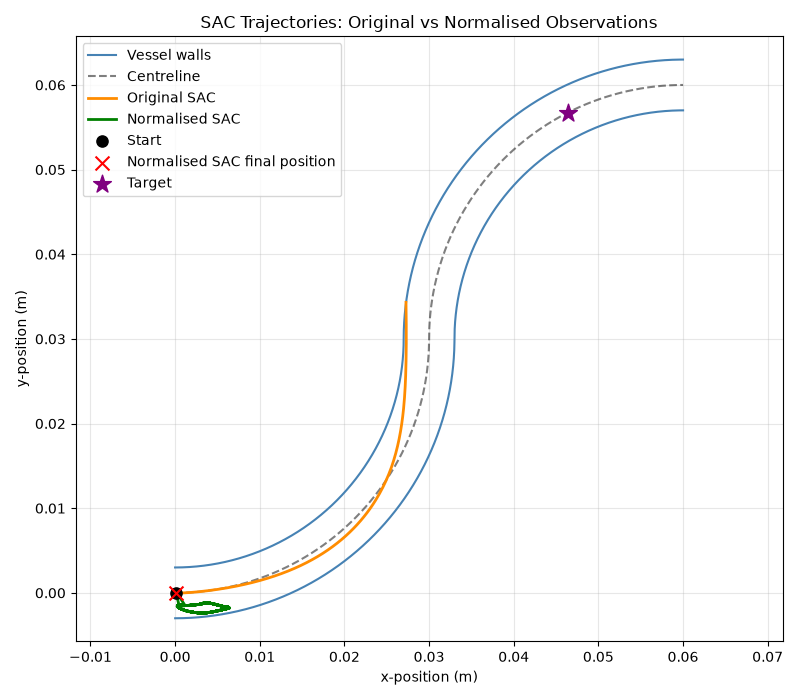

Final outcome: time_limit
Episode steps: 1000
Final position: [0.00009 0.     ]
Final velocity: [0. 0.]
Remaining target distance: 0.079988 m
Final wall clearance: 0.003000 m
Maximum absolute force: 0.000982 N


In [78]:

# ================================================================================
# PRELIMINARY SAC EVALUATION 2: VISUALISE NORMALISED SAC NAVIGATION TRAJECTORY
# ================================================================================

# Create a fresh evaluation environment and restore the observation
# statistics learned during normalised SAC training.
normalised_plot_env = DummyVecEnv([make_normalised_env])

normalised_plot_env = VecNormalize.load(
    "sac_normalised_50k_vecnormalize.pkl",
    normalised_plot_env
)

# Freeze observation statistics and retain the original reward values.
normalised_plot_env.training = False
normalised_plot_env.norm_reward = False

# Reset the environment; the returned observation is already normalised.
observation = normalised_plot_env.reset()

# Access the underlying physical environment to record actual states.
physical_env = normalised_plot_env.venv.envs[0]

# Record the initial position and velocity [x, y, vx, vy].
normalised_trajectory = [physical_env.state.copy()]
normalised_actions = []
normalised_rewards = []

done = False

# Run one complete episode using the trained normalised SAC policy.
while not done:

    # Predict a control force from the normalised observation.
    # Deterministic evaluation removes stochastic action sampling.
    action, _ = sac_normalised_model.predict(
        observation,
        deterministic=True
    )

    # Apply the action through the wrapped environment.
    observation, rewards, dones, infos = normalised_plot_env.step(action)

    # Save the updated physical state, force and reward.
    normalised_trajectory.append(physical_env.state.copy())
    normalised_actions.append(action[0].copy())
    normalised_rewards.append(float(rewards[0]))

    done = bool(dones[0])

# Convert the recorded values to NumPy arrays for analysis.
normalised_trajectory = np.array(normalised_trajectory)
normalised_actions = np.array(normalised_actions)

# ------------------------------------------------------------
# COMPARE ORIGINAL AND NORMALISED SAC TRAJECTORIES
# ------------------------------------------------------------

plt.figure(figsize=(8, 7))

# Plot the vessel boundaries and centreline.
plt.plot(
    vessel.wall1[:, 0], vessel.wall1[:, 1],
    color="steelblue", label="Vessel walls"
)
plt.plot(
    vessel.wall2[:, 0], vessel.wall2[:, 1],
    color="steelblue"
)
plt.plot(
    vessel.centreline[:, 0], vessel.centreline[:, 1],
    "k--", alpha=0.5, label="Centreline"
)

# Show the original SAC trajectory from the previous experiment.
plt.plot(
    trajectory[:, 0], trajectory[:, 1],
    color="darkorange", linewidth=2,
    label="Original SAC"
)

# Show the trajectory obtained using normalised observations.
plt.plot(
    normalised_trajectory[:, 0], normalised_trajectory[:, 1],
    color="green", linewidth=2,
    label="Normalised SAC"
)

# Identify the starting position, target and final catheter position.
plt.scatter(
    normalised_trajectory[0, 0], normalised_trajectory[0, 1],
    color="black", s=65, label="Start", zorder=5
)
plt.scatter(
    normalised_trajectory[-1, 0], normalised_trajectory[-1, 1],
    color="red", marker="x", s=100,
    label="Normalised SAC final position", zorder=5
)
plt.scatter(
    vessel.target_position[0], vessel.target_position[1],
    color="purple", marker="*", s=180,
    label="Target", zorder=5
)

# Format the comparison plot.
plt.title("SAC Trajectories: Original vs Normalised Observations")
plt.xlabel("x-position (m)")
plt.ylabel("y-position (m)")
plt.axis("equal")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# SUMMARISE NORMALISED SAC NAVIGATION
# ------------------------------------------------------------

final_position = normalised_trajectory[-1, :2]

# Calculate the signed remaining centreline distance to the target.
remaining_distance = vessel.distance_to_target(final_position)

# Calculate signed wall clearance and whether the catheter is inside.
wall_distance, inside = vessel.wall_clearance(final_position)

print("Final outcome:", infos[0]["outcome"])
print("Episode steps:", len(normalised_actions))
print("Final position:", final_position)
print("Final velocity:", normalised_trajectory[-1, 2:4])
print(f"Remaining target distance: {remaining_distance:.6f} m")
print(f"Final wall clearance: {wall_distance:.6f} m")
print(f"Maximum absolute force: {np.max(np.abs(normalised_actions)):.6f} N")

# Release the evaluation environment.
normalised_plot_env.close()



### Reward Contribution Analysis

The original and normalised SAC agents exhibited different navigation behaviours, despite both applying control forces close to the maximum permitted magnitude. To investigate whether the reward function contributes to these differences, we will examine the cumulative contributions of the progress, wall-proximity, control-effort and terminal reward components.

Each trained policy will be evaluated over one deterministic episode, with the reward components recorded at every timestep. Comparing these contributions will help determine whether SAC prioritises forward progress, collision avoidance or reduced control effort, and whether the current reward structure unintentionally encourages remaining near the vessel entrance.

The findings will guide any subsequent reward sensitivity experiments before modifying the reward weights.


CUMULATIVE REWARD CONTRIBUTIONS
---------------------------------------------------------------
Component                   Original SAC      Normalised SAC
progress                          5.4108              0.0301
wall                             -0.5008             -5.7706
control                          -0.0416             -0.1788
terminal                        -10.0000              0.0000
---------------------------------------------------------------
Total reward                     -5.1317             -5.9193

Original SAC outcome: side_wall_violation
Normalised SAC outcome: time_limit
Original SAC steps: 145
Normalised SAC steps: 1000

Reward component consistency: PASSED


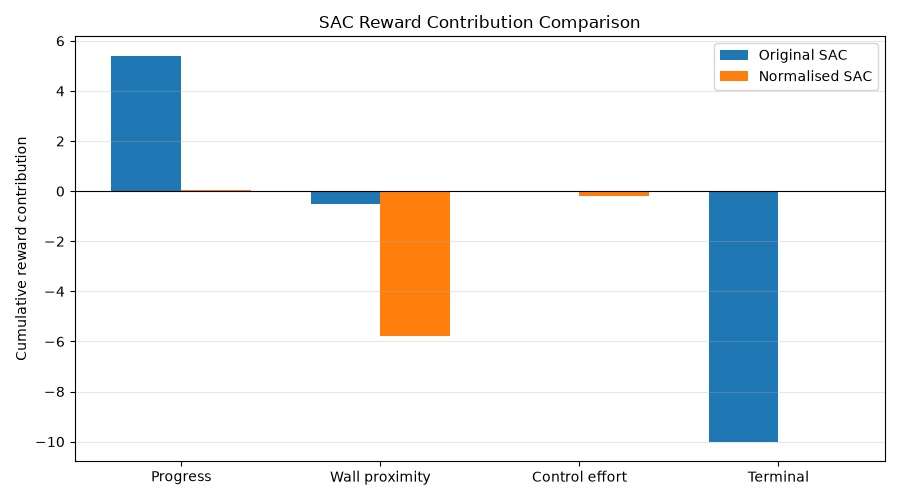

In [ ]:

# ===================================================================================
# PRELIMINARY SAC EVALUATION 2:COMPARE REWARD CONTRIBUTIONS OF BOTH SAC POLICIES
# ===================================================================================

#Here, we compare the cumulative contributions of each reward component for both the original and normalised SAC policies.
#This helps us understand how bith policies balance the different objectives encoded in the reward function. And potentially how to vary the reward weights to improve performance. 

# Reward components returned by CatheterEnv.step().
reward_names = ["progress", "wall", "control", "terminal"]



def evaluate_reward_components(model, environment, normalised=False):
    """Record cumulative reward contributions for one SAC episode."""

    # Gymnasium and SB3 vectorised environments have different reset APIs.
    if normalised:
        observation = environment.reset()
    else:
        observation, info = environment.reset(seed=42)

    # Initialise cumulative rewards for each component.
    reward_totals = {name: 0.0 for name in reward_names}

    episode_reward = 0.0
    episode_steps = 0
    done = False

    while not done:

        # Select an action without stochastic policy exploration.
        action, _ = model.predict(
            observation,
            deterministic=True
        )

        if normalised:
            # SB3 vectorised environments return four batched outputs.
            observation, rewards, dones, infos = environment.step(action)

            reward = float(rewards[0])
            info = infos[0]
            done = bool(dones[0])

        else:
            # Standard Gymnasium environments return five outputs.
            observation, reward, terminated, truncated, info = (
                environment.step(action)
            )

            done = terminated or truncated

        # Accumulate each component of the reward function.
        for name in reward_names:
            reward_totals[name] += float(
                info["reward_components"][name]
            )

        episode_reward += float(reward)
        episode_steps += 1

    #Return a summary of the episode's outcome, total steps, cumulative reward contributions, and overall reward.
    return {
        "outcome": info["outcome"],
        "steps": episode_steps,
        "components": reward_totals,
        "total_reward": episode_reward
    }


# ------------------------------------------------------------
# EVALUATE THE ORIGINAL AND NORMALISED SAC POLICIES
# ------------------------------------------------------------

# Original SAC receives the six unnormalised observations.
original_reward_env = CatheterEnv(
    vessel=vessel,
    config=env_config,
    reward_config=reward_config,
    render_mode=None
)

original_reward_results = evaluate_reward_components(
    sac_model, original_reward_env
)

# Normalised SAC uses the statistics saved during its training.
normalised_reward_env = DummyVecEnv([make_normalised_env])

normalised_reward_env = VecNormalize.load(
    "sac_normalised_50k_vecnormalize.pkl",
    normalised_reward_env
)

# Freeze observation statistics and preserve physical reward values.
normalised_reward_env.training = False
normalised_reward_env.norm_reward = False

normalised_reward_results = evaluate_reward_components(
    sac_normalised_model,
    normalised_reward_env,
    normalised=True
)

# ------------------------------------------------------------
# PRINT REWARD CONTRIBUTION COMPARISON
# ------------------------------------------------------------

print("CUMULATIVE REWARD CONTRIBUTIONS")
print("-" * 63)
print(f"{'Component':<20}{'Original SAC':>20}{'Normalised SAC':>20}")

for name in reward_names:
    original_value = original_reward_results["components"][name]
    normalised_value = normalised_reward_results["components"][name]

    print(f"{name:<20}{original_value:>20.4f}{normalised_value:>20.4f}")

print("-" * 63)
print(
    f"{'Total reward':<20}"
    f"{original_reward_results['total_reward']:>20.4f}"
    f"{normalised_reward_results['total_reward']:>20.4f}"
)

print("\nOriginal SAC outcome:", original_reward_results["outcome"])
print("Normalised SAC outcome:", normalised_reward_results["outcome"])
print("Original SAC steps:", original_reward_results["steps"])
print("Normalised SAC steps:", normalised_reward_results["steps"])

# Verify that the individual components reproduce the total reward.
for result in [original_reward_results, normalised_reward_results]:
    assert np.isclose(
        sum(result["components"].values()),
        result["total_reward"]
    )

print("\nReward component consistency: PASSED")

# ------------------------------------------------------------
# VISUALISE THE CONTRIBUTION OF EACH REWARD COMPONENT
# ------------------------------------------------------------

x = np.arange(len(reward_names))
bar_width = 0.35

original_values = [
    original_reward_results["components"][name] for name in reward_names
]
normalised_values = [
    normalised_reward_results["components"][name] for name in reward_names
]

plt.figure(figsize=(9, 5))

plt.bar(
    x - bar_width / 2, original_values,
    width=bar_width, label="Original SAC"
)

plt.bar(
    x + bar_width / 2, normalised_values,
    width=bar_width, label="Normalised SAC"
)

plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(x, ["Progress", "Wall proximity", "Control effort", "Terminal"])
plt.ylabel("Cumulative reward contribution")
plt.title("SAC Reward Contribution Comparison")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Close both evaluation environments.
original_reward_env.close()
normalised_reward_env.close()



### Findings from Reward Contribution Analysis

The original SAC agent accumulated substantial progress reward (+5.41) but terminated through a side-wall collision, whereas the normalised agent accumulated negligible progress reward (+0.03) and reached the episode time limit. The latter also incurred a larger cumulative wall-proximity penalty (−5.77), partly reflecting its longer episode duration.

These findings suggest that the two policies learned different unsuccessful behaviours: prioritising forward progress without sufficient collision avoidance, and remaining near the vessel entrance without meaningful navigation. A controlled reward sensitivity experiment will therefore investigate whether increasing the progress reward weight improves navigation while keeping other reward components and training settings unchanged.


In [48]:

# ============================================================
# PRELIMINARY SAC EVALUATION 3: PROGRESS REWARD SENSITIVITY (10 → 20)
# ============================================================

# Create a new reward configuration with double the progress weight from 10 to 20.
# All other reward parameters remain unchanged.
reward_config_20 = replace(
    reward_config,
    progress_weight=20.0
)

# Create a fresh environment using the updated reward configuration.
# The vessel geometry, dynamics and episode limits remain unchanged.
def make_progress_20_env():
    """Create the S-shaped environment with progress weight = 20."""
    return CatheterEnv(
        vessel=vessel,
        config=env_config,
        reward_config=reward_config_20,
        render_mode=None
    )


# Wrap the new environment for observation normalisation.
progress_20_env = DummyVecEnv([make_progress_20_env])

progress_20_env = VecNormalize(
    progress_20_env,
    training=True,
    norm_obs=True,
    norm_reward=False,
    clip_obs=10.0
)

# Initialise SAC from scratch using the same baseline hyperparameters.
# The new model is stored separately from our previous experiments.
sac_progress_20_model = SAC(
    policy="MlpPolicy",
    env=progress_20_env,
    seed=42,
    verbose=1
)

# Train for the same number of environment interactions.
sac_progress_20_model.learn(
    total_timesteps=50_000,
    log_interval=10
)

print("\nProgress-weight sensitivity training completed.")
print("Progress weight:", reward_config_20.progress_weight)
print("Total training timesteps:", sac_progress_20_model.num_timesteps)

# ------------------------------------------------------------
# SAVE MODEL AND NORMALISATION STATISTICS
# ------------------------------------------------------------

# Reuse the previous filenames to avoid creating additional files.
# Saving overwrites the earlier normalised SAC checkpoint and statistics.
sac_progress_20_model.save("sac_normalised_50k")
progress_20_env.save("sac_normalised_50k_vecnormalize.pkl")

print("\nSaved files (previous versions overwritten):")
print("  sac_normalised_50k.zip")
print("  sac_normalised_50k_vecnormalize.pkl")


Using cpu device
---------------------------------
| rollout/           |          |
|    success_rate    | 0        |
| time/              |          |
|    episodes        | 10       |
|    fps             | 127      |
|    time_elapsed    | 0        |
|    total_timesteps | 67       |
---------------------------------
---------------------------------
| rollout/           |          |
|    success_rate    | 0        |
| time/              |          |
|    episodes        | 20       |
|    fps             | 64       |
|    time_elapsed    | 7        |
|    total_timesteps | 458      |
| train/             |          |
|    actor_loss      | -2.74    |
|    critic_loss     | 2.9      |
|    ent_coef        | 0.9      |
|    ent_coef_loss   | -0.34    |
|    learning_rate   | 0.0003   |
|    n_updates       | 357      |
---------------------------------
---------------------------------
| rollout/           |          |
|    success_rate    | 0        |
| time/              |         


### Findings from Progress-Reward Sensitivity Training

Increasing the progress reward weight from 10 to 20, while retaining observation normalisation and the original SAC hyperparameters, resulted in successful navigation during training. The reported training success rate increased from 7% at approximately 44,000 timesteps to 12% near 48,000 timesteps, whereas both previous configurations had reported 0% success.

These findings provide preliminary evidence that SAC can learn successful navigation in the S-shaped environment and that performance is sensitive to the reward formulation. A separate deterministic evaluation is required to assess the final learned policy.


In [50]:

# ============================================================
# PRELIMINARY SAC EVALUATION 3: DETERMINISTIC AND STOCHASTIC EVALUATION
# ===========================================================================

# Create a fresh evaluation environment with progress_weight = 20.
progress_20_eval_env = DummyVecEnv([make_progress_20_env])

# Restore the observation-normalisation statistics from training.
progress_20_eval_env = VecNormalize.load(
    "sac_normalised_50k_vecnormalize.pkl",
    progress_20_eval_env
)

# Keep normalisation statistics fixed during evaluation.
# Preserve the original reward values without reward normalisation.
progress_20_eval_env.training = False
progress_20_eval_env.norm_reward = False


def evaluate_sac_policy(model, environment, n_episodes, deterministic):
    """Evaluate SAC and record navigation outcomes for each episode."""

    results = []

    for episode in range(n_episodes):

        # Reset the environment to the initial catheter state.
        observation = environment.reset()

        episode_reward = 0.0
        episode_steps = 0
        done = False

        while not done:

            # Deterministic=True selects the learned mean action.
            # Deterministic=False samples from the learned policy.
            action, _ = model.predict(
                observation,
                deterministic=deterministic
            )

            # Advance the environment using the selected control force.
            observation, rewards, dones, infos = environment.step(action)

            episode_reward += float(rewards[0])
            episode_steps += 1
            done = bool(dones[0])

        # Record the final outcome and statistics for this episode.
        results.append({
            "episode": episode + 1,
            "outcome": infos[0]["outcome"],
            "steps": episode_steps,
            "reward": episode_reward
        })

    return results


# ------------------------------------------------------------
# EVALUATE BOTH POLICY VARIANTS
# ------------------------------------------------------------

# One episode is sufficient for the deterministic policy because
# the initial conditions and catheter dynamics are unchanged.
deterministic_results = evaluate_sac_policy(
    sac_progress_20_model,
    progress_20_eval_env,
    n_episodes=1,
    deterministic=True
)

# Sample actions from the trained stochastic SAC policy.
# This introduces variation between otherwise identical episodes.
stochastic_results = evaluate_sac_policy(
    sac_progress_20_model,
    progress_20_eval_env,
    n_episodes=30,
    deterministic=False
)


# ------------------------------------------------------------
# SUMMARISE AND COMPARE EVALUATION RESULTS
# ------------------------------------------------------------

def summarise_sac_evaluation(results, label):
    """Print success rate, episode statistics and outcome counts."""

    outcomes = [result["outcome"] for result in results]
    successes = outcomes.count("success")

    print(f"\n{label}")
    print("-" * 45)
    print("Evaluation episodes:", len(results))
    print(f"Success rate: {successes / len(results):.1%}")
    print(f"Mean episode length: {np.mean([r['steps'] for r in results]):.1f}")
    print(f"Mean episode reward: {np.mean([r['reward'] for r in results]):.4f}")

    print("\nOutcome distribution:")
    for outcome in sorted(set(outcomes)):
        print(f"  {outcome}: {outcomes.count(outcome)}")


summarise_sac_evaluation(
    deterministic_results,
    "DETERMINISTIC SAC EVALUATION"
)

summarise_sac_evaluation(
    stochastic_results,
    "STOCHASTIC SAC EVALUATION"
)

# Close the evaluation environment after both tests.
progress_20_eval_env.close()



DETERMINISTIC SAC EVALUATION
---------------------------------------------
Evaluation episodes: 1
Success rate: 0.0%
Mean episode length: 1000.0
Mean episode reward: 4.9095

Outcome distribution:
  time_limit: 1

STOCHASTIC SAC EVALUATION
---------------------------------------------
Evaluation episodes: 30
Success rate: 0.0%
Mean episode length: 540.7
Mean episode reward: 3.6815

Outcome distribution:
  side_wall_violation: 27
  time_limit: 3



### Evaluation Findings: Increased Progress Reward

Although increasing the progress weight to 20 produced successful navigation during SAC training, the final policy achieved no successes during evaluation. The deterministic policy reached the 1,000-step time limit with a positive accumulated reward (+4.91), while the stochastic policy experienced side-wall violations in 27 of 30 episodes.

These results indicate that successful trajectories were discovered during training but were not reliably reproduced by the final learned policy. Further trajectory analysis is needed to determine whether the remaining difficulty involves forward progress, steering or reaching the target.


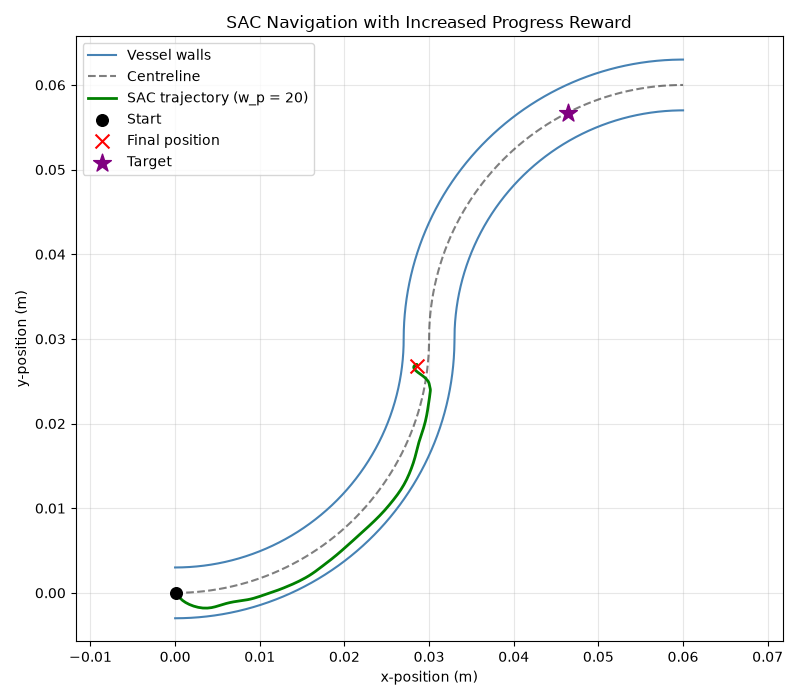

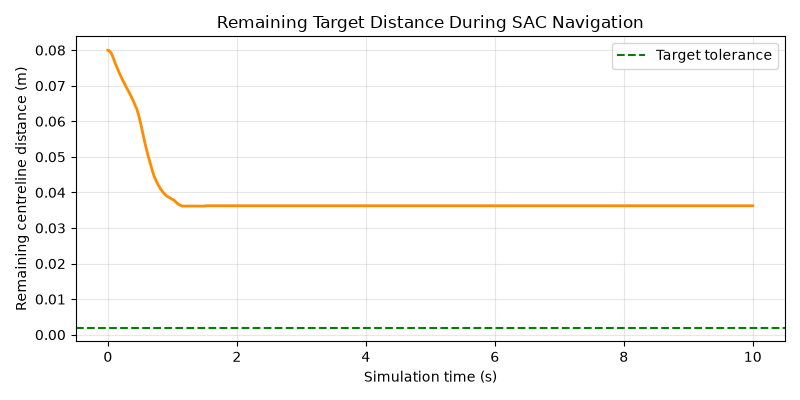

Final outcome: time_limit
Episode steps: 1000
Final position: [0.02854 0.02683]
Final velocity: [-0.  0.]
Initial target distance: 0.079988 m
Final target distance: 0.036264 m
Minimum target distance: 0.036169 m
Maximum absolute force: 0.000960 N


In [52]:

# ============================================================
# VISUALISE SAC NAVIGATION: PROGRESS WEIGHT = 20
# ============================================================

# Create a fresh evaluation environment using progress_weight = 20.
progress_20_plot_env = DummyVecEnv([make_progress_20_env])

# Restore the observation-normalisation statistics from training.
progress_20_plot_env = VecNormalize.load(
    "sac_normalised_50k_vecnormalize.pkl",
    progress_20_plot_env
)

# Freeze the statistics and preserve the original reward values.
progress_20_plot_env.training = False
progress_20_plot_env.norm_reward = False

# Access the underlying catheter environment to record physical states.
physical_env_20 = progress_20_plot_env.venv.envs[0]

# Reset the environment and record its initial state.
observation = progress_20_plot_env.reset()

trajectory_20 = [physical_env_20.state.copy()]
actions_20 = []
target_distances_20 = [physical_env_20.vessel.distance_to_target(
    physical_env_20.state[:2]
)]

done = False

# Run one deterministic evaluation episode.
while not done:

    # Predict a force using the trained policy and normalised observation.
    action, _ = sac_progress_20_model.predict(
        observation,
        deterministic=True
    )

    # Advance the catheter dynamics through the wrapped environment.
    observation, rewards, dones, infos = progress_20_plot_env.step(action)

    # DummyVecEnv automatically resets after episode termination.
    # At the final step, retrieve the terminal observation before reset.
    if dones[0]:
        # VecNormalize stores terminal observations in normalised form,
        # so convert them back to physical observation units.
        current_state = progress_20_plot_env.unnormalize_obs(
            infos[0]["terminal_observation"]
        )[:4].copy()
    else:
        # During an active episode, the physical state is directly available.
        current_state = physical_env_20.state.copy()    

    trajectory_20.append(current_state)
    actions_20.append(action[0].copy())
    target_distances_20.append(
        physical_env_20.vessel.distance_to_target(current_state[:2])
    )

    done = bool(dones[0])

# Convert recorded quantities into arrays for plotting.
trajectory_20 = np.array(trajectory_20)
actions_20 = np.array(actions_20)
target_distances_20 = np.array(target_distances_20)

# Calculate elapsed simulation time for each recorded position.
times_20 = np.arange(len(trajectory_20)) * env_config.dt

# ------------------------------------------------------------
# PLOT THE CATHETER TRAJECTORY
# ------------------------------------------------------------

plt.figure(figsize=(8, 7))

# Plot the vessel boundaries and reference centreline.
plt.plot(vessel.wall1[:, 0], vessel.wall1[:, 1],
         color="steelblue", label="Vessel walls")
plt.plot(vessel.wall2[:, 0], vessel.wall2[:, 1],
         color="steelblue")

plt.plot(vessel.centreline[:, 0], vessel.centreline[:, 1],
         "k--", alpha=0.5, label="Centreline")

# Plot the trajectory produced by the progress-weight-20 SAC policy.
plt.plot(trajectory_20[:, 0], trajectory_20[:, 1],
         color="green", linewidth=2, label="SAC trajectory (w_p = 20)")

# Mark the starting position, final position and navigation target.
plt.scatter(trajectory_20[0, 0], trajectory_20[0, 1],
            color="black", s=70, label="Start", zorder=5)

plt.scatter(trajectory_20[-1, 0], trajectory_20[-1, 1],
            color="red", marker="x", s=100, label="Final position", zorder=5)

plt.scatter(vessel.target_position[0], vessel.target_position[1],
            color="purple", marker="*", s=180, label="Target", zorder=5)

plt.title("SAC Navigation with Increased Progress Reward")
plt.xlabel("x-position (m)")
plt.ylabel("y-position (m)")
plt.axis("equal")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# PLOT REMAINING TARGET DISTANCE OVER TIME
# ------------------------------------------------------------

plt.figure(figsize=(8, 4))

# Show how the signed remaining centreline distance changes during navigation.
plt.plot(times_20, target_distances_20,
         color="darkorange", linewidth=2)

# Display the target tolerance used for successful navigation.
plt.axhline(env_config.target_tolerance,
            color="green", linestyle="--", label="Target tolerance")

plt.title("Remaining Target Distance During SAC Navigation")
plt.xlabel("Simulation time (s)")
plt.ylabel("Remaining centreline distance (m)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# SUMMARISE THE NAVIGATION OUTCOME
# ------------------------------------------------------------

print("Final outcome:", infos[0]["outcome"])
print("Episode steps:", len(actions_20))
print("Final position:", trajectory_20[-1, :2])
print("Final velocity:", trajectory_20[-1, 2:4])
print(f"Initial target distance: {target_distances_20[0]:.6f} m")
print(f"Final target distance: {target_distances_20[-1]:.6f} m")
print(f"Minimum target distance: {np.min(target_distances_20):.6f} m")
print(f"Maximum absolute force: {np.max(np.abs(actions_20)):.6f} N")

# Close the evaluation environment.
progress_20_plot_env.close()



### SAC Feasibility Test with Increased Success Reward

Previous SAC experiments demonstrated partial navigation and occasional successful episodes during training, but the final policies failed to reproduce successful navigation during evaluation. To investigate whether the delayed terminal reward is limiting learning, we will increase the success bonus from **+10 to +1000**, while retaining the progress weight of 20, observation normalisation and all other reward and SAC hyperparameters.

The larger success bonus is intended to make reaching the target substantially more valuable than obtaining partial progress or remaining stationary until the episode time limit. This deliberately amplified reward is being tested to establish RL feasibility and is not necessarily the reward configuration that will be adopted for the final SAC–MPC comparison.

A fresh SAC agent will be trained for 50,000 environment interactions, with periodic evaluations used to monitor navigation performance and preserve the best-performing policy. The final and best-performing policies will then be evaluated separately to determine whether successful navigation can be reproduced consistently.


In [53]:

# ============================================================
# PRELIMINARY SAC EVALUATION 4: EVALUATING USING +1000 AS SUCCESS REWARD
# ============================================================

# Create a new reward configuration for the feasibility experiment.
# Retain the progress weight of 20 and change only the success bonus.
reward_config_1000 = replace(
    reward_config_20,
    success_bonus=1000.0
)

def make_success_1000_env():
    """Create the S-shaped catheter environment with a +1000 success bonus."""
    return CatheterEnv(
        vessel=vessel,
        config=env_config,
        reward_config=reward_config_1000,
        render_mode=None
    )


# ------------------------------------------------------------
# CREATE THE TRAINING ENVIRONMENT
# ------------------------------------------------------------

# Wrap the environment to support Stable-Baselines3 normalisation.
success_1000_train_env = DummyVecEnv([make_success_1000_env])

# Normalise observations while preserving the original reward values.
success_1000_train_env = VecNormalize(
    success_1000_train_env,
    training=True,
    norm_obs=True,
    norm_reward=False,
    clip_obs=10.0
)


# ------------------------------------------------------------
# CREATE THE EVALUATION ENVIRONMENT
# ------------------------------------------------------------

# Use a separate environment for periodic policy evaluation.
success_1000_eval_env = DummyVecEnv([make_success_1000_env])

success_1000_eval_env = VecNormalize(
    success_1000_eval_env,
    training=False,
    norm_obs=True,
    norm_reward=False,
    clip_obs=10.0
)

# Evaluation statistics will be synchronised with training
# before each evaluation, then kept fixed during evaluation.


# ------------------------------------------------------------
# INITIALISE A FRESH SAC MODEL
# ------------------------------------------------------------

# Use SAC's default learning hyperparameters and the original seed.
sac_success_1000_model = SAC(
    policy="MlpPolicy",
    env=success_1000_train_env,
    seed=42,
    verbose=1
)

print("EXPERIMENT 4 CONFIGURATION")
print("-" * 45)
print("Progress weight:", reward_config_1000.progress_weight)
print("Wall weight:", reward_config_1000.wall_weight)
print("Control weight:", reward_config_1000.control_weight)
print("Success bonus:", reward_config_1000.success_bonus)
print("Failure penalty:", reward_config_1000.failure_penalty)
print("Observation normalisation:", success_1000_train_env.norm_obs)
print("Reward normalisation:", success_1000_train_env.norm_reward)
print("SAC discount factor:", sac_success_1000_model.gamma)
print("Training budget: 50,000 timesteps")


Using cpu device
EXPERIMENT 4 CONFIGURATION
---------------------------------------------
Progress weight: 20.0
Wall weight: 0.01
Control weight: 0.001
Success bonus: 1000.0
Failure penalty: 10.0
Observation normalisation: True
Reward normalisation: False
SAC discount factor: 0.99
Training budget: 50,000 timesteps


In [54]:

# ============================================================
# PRELIMINARY SAC EVALUATION 4: TRAINING AND BEST-MODEL CHECKPOINTING
# ============================================================

from stable_baselines3.common.callbacks import EvalCallback #Callback for periodic evaluation and model checkpointing.

class SACFeasibilityCallback(EvalCallback):
    """Save the normalisation statistics whenever a new best policy is found."""

    def _on_step(self):
        # Remember the best evaluation reward before the current step.
        previous_best_reward = self.best_mean_reward #self.best_mean_reward is a variable maintained by EvalCallback.

        # Run the standard evaluation and save the best SAC policy.
        # EvalCallback also synchronises observation-normalisation statistics.
        continue_training = super()._on_step()

        # Save the statistics associated with the new best checkpoint.
        # No need to save the best model as that is already handled internally by the parent callback i.e. EvalCallback.
        if self.best_mean_reward > previous_best_reward:
            self.training_env.save("best_model_vecnormalize.pkl") #Save the VecNormalize statistics for the best model.

        return continue_training 


# ------------------------------------------------------------
# CONFIGURE PERIODIC EVALUATION
# ------------------------------------------------------------

# Instantiate the callback to evaluate the SAC policy during training.
# We evaluate every 5,000 training timesteps and save the best model.
success_1000_callback = SACFeasibilityCallback(
    eval_env=success_1000_eval_env,
    best_model_save_path=".",
    log_path=None, 
    eval_freq=5_000,
    n_eval_episodes=1,
    deterministic=True,
    render=False,
    verbose=1
)


# ------------------------------------------------------------
# TRAIN THE SAC AGENT
# ------------------------------------------------------------

# Train from scratch using the model initialised in Cell 1.
# Periodic evaluations do not contribute to the training timestep count.
sac_success_1000_model.learn(
    total_timesteps=50_000,
    callback=success_1000_callback,
    log_interval=10
)


# ------------------------------------------------------------
# SAVE THE FINAL MODEL AND NORMALISATION STATISTICS
# ------------------------------------------------------------

# Overwrite the previous normalised SAC files to keep the folder tidy.
sac_success_1000_model.save("sac_normalised_50k")
success_1000_train_env.save("sac_normalised_50k_vecnormalize.pkl")

print("\nSAC EXPERIMENT 4 COMPLETED")
print("-" * 45)
print("Total training timesteps:", sac_success_1000_model.num_timesteps)
print("Best periodic evaluation reward:",
      success_1000_callback.best_mean_reward)

print("\nSaved checkpoints:")
print("Final model: sac_normalised_50k.zip")
print("Final statistics: sac_normalised_50k_vecnormalize.pkl")
print("Best model: best_model.zip")
print("Best statistics: best_model_vecnormalize.pkl")


---------------------------------
| rollout/           |          |
|    success_rate    | 0        |
| time/              |          |
|    episodes        | 10       |
|    fps             | 102      |
|    time_elapsed    | 0        |
|    total_timesteps | 67       |
---------------------------------
---------------------------------
| rollout/           |          |
|    success_rate    | 0        |
| time/              |          |
|    episodes        | 20       |
|    fps             | 49       |
|    time_elapsed    | 9        |
|    total_timesteps | 458      |
| train/             |          |
|    actor_loss      | -2.74    |
|    critic_loss     | 2.9      |
|    ent_coef        | 0.9      |
|    ent_coef_loss   | -0.34    |
|    learning_rate   | 0.0003   |
|    n_updates       | 357      |
---------------------------------
---------------------------------
| rollout/           |          |
|    success_rate    | 0        |
| time/              |          |
|    episodes 

c:\Users\kizit\anaconda3\envs\CONTROL\Lib\site-packages\stable_baselines3\common\evaluation.py:71: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


Eval num_timesteps=5000, episode_reward=4.44 +/- 0.00
Episode length: 134.00 +/- 0.00
Success rate: 0.00%
---------------------------------
| eval/              |          |
|    mean_ep_length  | 134      |
|    mean_reward     | 4.44     |
|    success_rate    | 0        |
| time/              |          |
|    total_timesteps | 5000     |
| train/             |          |
|    actor_loss      | -12.5    |
|    critic_loss     | 0.829    |
|    ent_coef        | 0.246    |
|    ent_coef_loss   | -3.05    |
|    learning_rate   | 0.0003   |
|    n_updates       | 4899     |
---------------------------------
New best mean reward!
---------------------------------
| rollout/           |          |
|    success_rate    | 0.0111   |
| time/              |          |
|    episodes        | 90       |
|    fps             | 43       |
|    time_elapsed    | 131      |
|    total_timesteps | 5698     |
| train/             |          |
|    actor_loss      | -14.4    |
|    critic_loss     |


### Findings from SAC Feasibility Experiment 4

Increasing the terminal success bonus to +1000, while retaining observation normalisation and a progress weight of 20, produced successful navigation during periodic deterministic evaluation. At the end of training, SAC reached the target in 110 steps (1.10 s), earning an episode reward of approximately +1016.21.

This demonstrates that SAC can learn a successful navigation policy within the simplified S-shaped vessel environment under the tested configuration. However, the 100% success rate represents a single deterministic evaluation with fixed initial conditions and therefore does not establish robustness or generalisation.

The amplified success reward was introduced specifically to investigate RL feasibility; its suitability for the final SAC–MPC comparison will require further investigation.

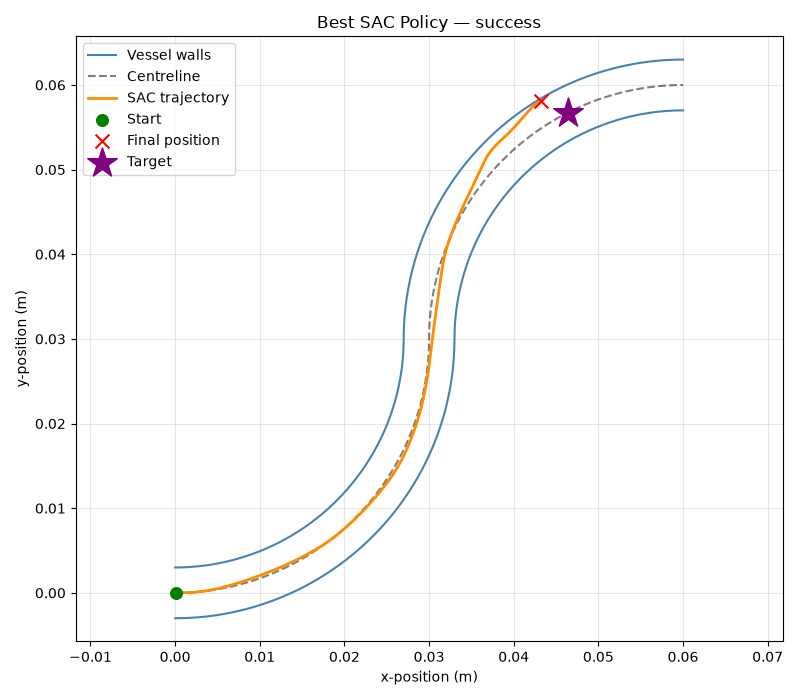

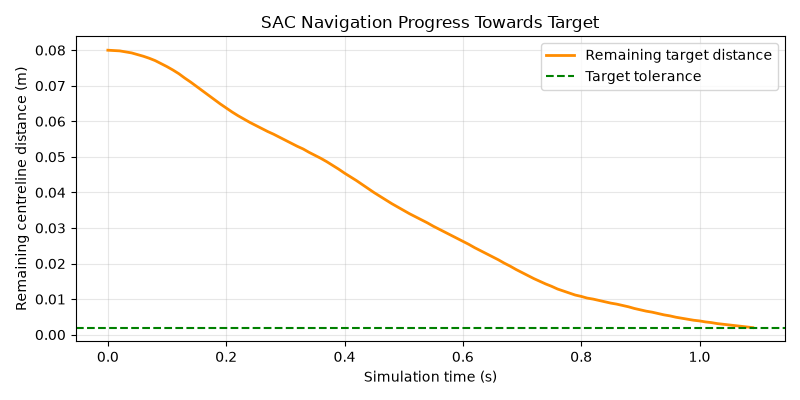

BEST SAC POLICY: NAVIGATION RESULTS
---------------------------------------------
Final outcome: success
Navigation successful: True
Episode steps: 109
Simulation time: 1.090 s
Final position: [0.0432  0.05816]
Final velocity: [0.01677 0.01002]
Final target distance: 0.001983 m
Minimum wall clearance: 0.000207 m
Maximum absolute control force: 0.000952 N
Total accumulated reward: 1016.2355

Navigation outcome and force-limit checks: PASSED


In [56]:

# ============================================================
# PRELIMINARY SAC EVALUATION 4: VERIFY SUCCESSFUL NAVIGATION
# ============================================================

# ------------------------------------------------------------
# LOAD THE BEST SAC MODEL AND NORMALISATION STATISTICS
# ------------------------------------------------------------

# Load the best policy saved during periodic evaluation.
best_sac_model = SAC.load("best_model.zip")

# Create a fresh physical environment for evaluating the policy.
# This allows us to record physical states without automatic resets.
physical_best_env = make_success_1000_env()

# Create a separate vectorised environment to restore the observation
# normalisation statistics obtained during training.
normalisation_env = VecNormalize.load(
    "best_model_vecnormalize.pkl",
    DummyVecEnv([make_success_1000_env])
)

# Freeze the normalisation statistics during evaluation.
# The wrapper will only be used to transform observations, not step the catheter.
normalisation_env.training = False
normalisation_env.norm_reward = False

# Reset the physical environment to its initial catheter state.
physical_observation, info = physical_best_env.reset(seed=42)

# Record the initial physical state [x, y, vx, vy].
best_trajectory = [physical_best_env.state.copy()]

# Record the initial remaining centreline distance to the target.
best_target_distances = [
    physical_best_env.vessel.distance_to_target(
        physical_best_env.state[:2]
    )
]

# Initialise lists for recording applied forces and received rewards.
best_actions = []
best_rewards = []

terminated = False
truncated = False

# ------------------------------------------------------------
# RUN ONE DETERMINISTIC NAVIGATION EPISODE
# ------------------------------------------------------------

while not (terminated or truncated):

    # Convert the six-dimensional physical observation into the
    # normalised observation expected by the trained SAC policy.
    # reshape(1, -1) adds a batch dimension: (6,) becomes (1, 6).
    normalised_observation = normalisation_env.normalize_obs(
        physical_observation.reshape(1, -1)
    )

    # Predict the control force using the best trained SAC policy.
    # deterministic=True removes stochastic action sampling.
    action, _ = best_sac_model.predict(
        normalised_observation,
        deterministic=True
    )

    # Apply the predicted force to the physical environment.
    # action[0] selects the two force components from the batch.
    physical_observation, reward, terminated, truncated, info = (
        physical_best_env.step(action[0])
    )

    # Record the updated physical state, applied force and reward.
    current_state = physical_best_env.state.copy()

    best_trajectory.append(current_state)
    best_actions.append(action[0].copy())
    best_rewards.append(float(reward))

    # Calculate the remaining target distance at the new position.
    best_target_distances.append(
        physical_best_env.vessel.distance_to_target(current_state[:2])
    )

# Convert the recorded lists into NumPy arrays for plotting and analysis.
best_trajectory = np.array(best_trajectory)
best_actions = np.array(best_actions)
best_rewards = np.array(best_rewards)
best_target_distances = np.array(best_target_distances)

# Calculate the elapsed simulation time at each recorded position.
best_times = np.arange(len(best_trajectory)) * env_config.dt

# ------------------------------------------------------------
# PLOT THE SAC NAVIGATION TRAJECTORY
# ------------------------------------------------------------

plt.figure(figsize=(8, 7))

# Plot the vessel boundaries and reference centreline.
plt.plot(
    vessel.wall1[:, 0], vessel.wall1[:, 1],
    color="steelblue", label="Vessel walls"
)
plt.plot(
    vessel.wall2[:, 0], vessel.wall2[:, 1],
    color="steelblue"
)
plt.plot(
    vessel.centreline[:, 0], vessel.centreline[:, 1],
    "k--", alpha=0.5, label="Centreline"
)

# Plot the physical catheter trajectory generated by SAC.
plt.plot(
    best_trajectory[:, 0], best_trajectory[:, 1],
    color="darkorange", linewidth=2, label="SAC trajectory"
)

# Mark the initial catheter position.
plt.scatter(
    best_trajectory[0, 0], best_trajectory[0, 1],
    color="green", s=70, label="Start", zorder=5
)

# Mark the catheter position at the end of the episode.
plt.scatter(
    best_trajectory[-1, 0], best_trajectory[-1, 1],
    color="red", marker="x", s=100, label="Final position", zorder=5
)

# Mark the navigation target defined in the vessel geometry.
plt.scatter(
    vessel.target_position[0], vessel.target_position[1],
    color="purple", marker="*", s=500, label="Target", zorder=5
)

# Format the trajectory plot.
plt.title(f"Best SAC Policy — {info['outcome']}")
plt.xlabel("x-position (m)")
plt.ylabel("y-position (m)")
plt.axis("equal")  # Preserve the vessel's actual geometric proportions.
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# PLOT TARGET DISTANCE AGAINST SIMULATION TIME
# ------------------------------------------------------------

plt.figure(figsize=(8, 4))

# Show how the remaining centreline distance changes during navigation.
plt.plot(
    best_times, best_target_distances,
    color="darkorange", linewidth=2,
    label="Remaining target distance"
)

# Display the target tolerance used to determine navigation success.
plt.axhline(
    env_config.target_tolerance,
    color="green", linestyle="--", label="Target tolerance"
)

plt.title("SAC Navigation Progress Towards Target")
plt.xlabel("Simulation time (s)")
plt.ylabel("Remaining centreline distance (m)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# SUMMARISE NAVIGATION PERFORMANCE
# ------------------------------------------------------------

# Calculate signed wall clearance for every recorded catheter position.
# The first returned value is the signed distance to the vessel wall.
best_wall_clearances = np.array([
    vessel.wall_clearance(state[:2])[0]
    for state in best_trajectory
])

print("BEST SAC POLICY: NAVIGATION RESULTS")
print("-" * 45)

print("Final outcome:", info["outcome"])
print("Navigation successful:", info["is_success"])
print("Episode steps:", len(best_actions))
print(f"Simulation time: {best_times[-1]:.3f} s")

# Report the catheter's final physical position and velocity.
print("Final position:", best_trajectory[-1, :2])
print("Final velocity:", best_trajectory[-1, 2:4])

# Report navigation progress, wall clearance and control effort.
print(f"Final target distance: {best_target_distances[-1]:.6f} m")
print(f"Minimum wall clearance: {np.min(best_wall_clearances):.6f} m")
print(f"Maximum absolute control force: {np.max(np.abs(best_actions)):.6f} N")
print(f"Total accumulated reward: {np.sum(best_rewards):.4f}")

# ------------------------------------------------------------
# VALIDATE NAVIGATION OUTCOME AND CONTROL LIMITS
# ------------------------------------------------------------

# Verify that the reported success flag agrees with the final outcome.
assert info["is_success"] == (info["outcome"] == "success")

# Verify that all actions respected the physical force limits.
assert np.all(
    np.abs(best_actions) <= env_config.max_force + 1e-8
)

print("\nNavigation outcome and force-limit checks: PASSED")

# Close both environments after evaluation.
physical_best_env.close()
normalisation_env.close()



### Conclusion of Preliminary SAC Feasibility Testing

The best saved SAC policy successfully navigated the S-shaped vessel in 109 timesteps (1.09 s), reaching a remaining centreline target distance of 1.983 mm within the configured 2 mm tolerance. The trajectory remained inside the vessel, with a minimum recorded wall clearance of 0.207 mm, and all applied forces respected the configured limits.

These findings confirm that successful RL navigation is achievable in the simplified deterministic environment under the tested configuration. The amplified success bonus of +1000 was introduced specifically to establish learning feasibility; its suitability for the final SAC–MPC experiments and the policy's robustness to disturbances remain to be investigated.



## Additinal Modifications
Here, we make addtional modifications that became necessary as the project implementation progress. These include
1. Adding the stenosis narrowing 
2. Including gaussian noise to the environment to mimic uncertainties in real blood flow. 

### Implementation of Variable-Width Vessel Geometry

To extend the S-shaped vessel geometry, we will introduce a variable-radius geometry to mimic a localised stenosis (narrowing) of the blood vessel. To achieve this, we will use **a smooth step function** to gradually reduce and restore the vessel radius over a specified section of its length.

The smooth step function will be defined as:

$$
h(t)=3t^2-2t^3,\qquad 0\leq t\leq1
$$


Additionally, stenosis will be controlled by three parameters:

- **Centre fraction:** Location of the narrowing along the total centreline length.
- **Stenosis length:** Total length of the affected vessel section.
- **Severity:** Maximum fractional reduction in vessel radius.

First, let us visualize the smooth step function

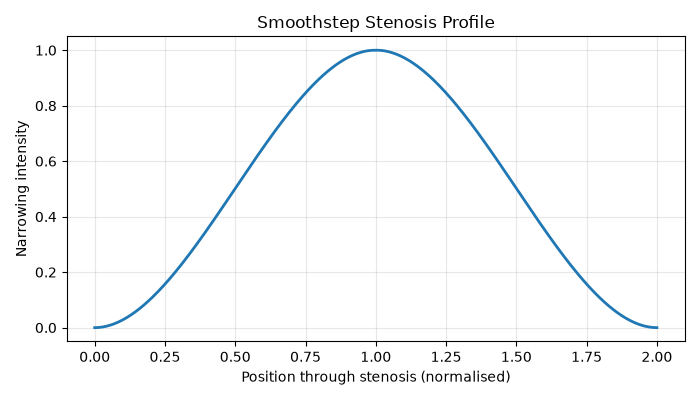

In [67]:

# ============================================================
# VISUALISE THE COMPLETE SMOOTHSTEP STENOSIS PROFILE
# ============================================================

def smoothstep(t):
    """Calculate smoothstep interpolation for values between 0 and 1."""
    return 3*t**2 - 2*t**3


# Generate transition values from 0 to 1.
t = np.linspace(0, 1, 200)

# Generate the contraction and expansion profiles using smoothstep.
h_left = smoothstep(t)
h_right = smoothstep(1 - t)

# Combine both halves into one continuous narrowing profile.
stenosis_profile = np.concatenate((h_left, h_right))
position = np.linspace(0, 2, len(stenosis_profile))

# Visualise the complete stenosis profile.
plt.figure(figsize=(7, 4))
plt.plot(position, stenosis_profile, linewidth=2)

plt.xlabel("Position through stenosis (normalised)")
plt.ylabel("Narrowing intensity")
plt.title("Smoothstep Stenosis Profile")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [68]:

# ============================================================
# IMPLEMENT VARIABLE VESSEL RADIUS USING SMOOTHSTEP
# ============================================================

#Redefine the smmothstep function. Redefining is only necessary to make this cell self-contained. 
def smoothstep(t):
    """Calculate smoothstep interpolation for values between 0 and 1."""
    return 3*t**2 - 2*t**3

#Define the variable_width function to generate a smooth, symmetric stenosis along the vessel centreline using the smoothstep function.
def variable_width(s, radius, centre_fraction=0.60,
                   stenosis_length=0.020, severity=0.30):
    """
    Generate a smooth, symmetric stenosis along the vessel centreline.

    Parameters
    ----------
    s : np.ndarray
        Cumulative distance along the vessel centreline (m).
    radius : float
        Nominal vessel radius (m).
    centre_fraction : float
        Location of stenosis centre as a fraction of vessel length.
    stenosis_length : float
        Total length of the stenosis (m).
    severity : float
        Maximum fractional reduction in vessel radius.

    Returns
    -------
    np.ndarray
        Local vessel radius at each centreline position (m).
    """

    # Validate the stenosis parameters.
    if not 0 <= centre_fraction <= 1:
        raise ValueError("centre_fraction must be between 0 and 1.")
    if not 0 < severity < 1:
        raise ValueError("severity must be between 0 and 1.")
    if radius <= 0 or stenosis_length <= 0:
        raise ValueError("Radius and stenosis length must be positive.")

    # Determine the stenosis centre, start and end along the centreline.
    vessel_length = s[-1]
    stenosis_centre = centre_fraction * vessel_length
    stenosis_start = stenosis_centre - stenosis_length / 2
    stenosis_end = stenosis_centre + stenosis_length / 2

    # Ensure the entire stenosis fits inside the vessel.
    if stenosis_start < 0 or stenosis_end > vessel_length:
        raise ValueError("Stenosis extends beyond the vessel boundaries.")

    # Initialise the radius profile at the nominal radius.
    local_radius = np.full_like(s, radius, dtype=float)

    # Identify the contraction and expansion sections.
    contraction = (s >= stenosis_start) & (s <= stenosis_centre)
    expansion = (s > stenosis_centre) & (s <= stenosis_end)

    # Convert distances in each half into transition fractions [0, 1].
    t_left = (s[contraction] - stenosis_start) / (stenosis_length / 2)
    t_right = (s[expansion] - stenosis_centre) / (stenosis_length / 2)

    # Use the smoothstep function to decrease(contraction) and then restore(expansion) the vessel radius.
    local_radius[contraction] = radius * (
        1 - severity * smoothstep(t_left)
    )
    local_radius[expansion] = radius * (
        1 - severity * smoothstep(1 - t_right)
    )

    return local_radius


VARIABLE-WIDTH VESSEL PROPERTIES
---------------------------------------------
Vessel length: 94.248 mm
Stenosis start: 36.549 mm
Stenosis centre: 56.549 mm
Stenosis end: 76.549 mm
Stenosis length: 40.000 mm
Nominal radius: 3.000 mm
Expected minimum radius: 2.100 mm
Sampled minimum radius: 2.100 mm


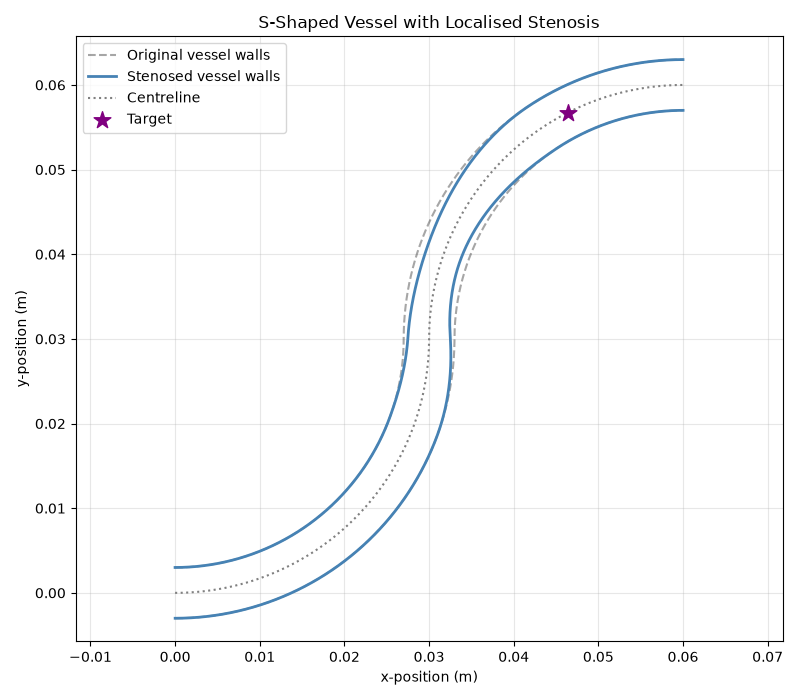

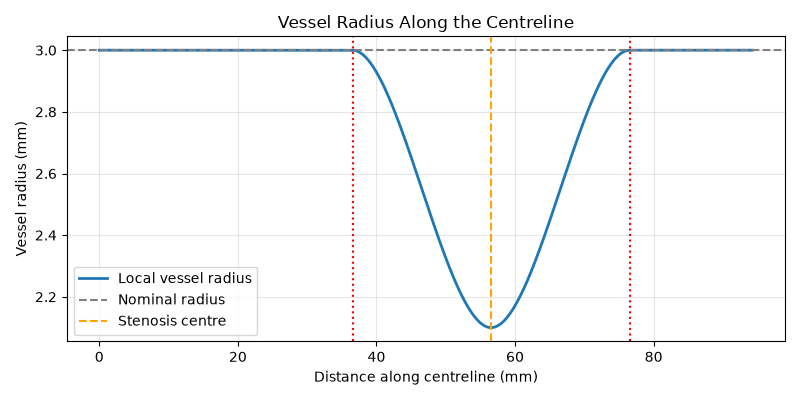


Variable-width geometry validation: PASSED


In [ ]:

# ============================================================
# GENERATE AND VERIFY VARIABLE-WIDTH S-VESSEL GEOMETRY
# ============================================================

# Configure the stenosis parameters.
centre_fraction = 0.60
stenosis_length = 0.040     # 40 mm.  Our default was 20 mm, but we can change it to 40 mm for this example.
severity = 0.30            # 30% radius reduction

# Use the built in functools.partial to pass variables to the variable_width function without changing its signature.
# This partial is only necessary if we want use stenosis parameters different from the default values in variable_width. such as stenosis_length 0f 0.04 instead of the default 0.02.
# otherwise, we can just pass the variable_width function directly to the SVessel constructor.
stenosis_profile = partial(
    variable_width,
    centre_fraction=centre_fraction,
    stenosis_length=stenosis_length,
    severity=severity
)

# Generate a new S-shaped vessel with variable radius.
# The original constant-width vessel remains unchanged.
stenosed_vessel = SVessel(
    config=config,
    width_profile=stenosis_profile,
    radius=vessel_radius,
    target_fraction=0.85
)

# ------------------------------------------------------------
# CALCULATE EXPECTED STENOSIS PROPERTIES
# ------------------------------------------------------------

# Determine the expected stenosis boundaries along the centreline.
# This calculation is only useful for providing a reference for the visualisation. 

s_centre = centre_fraction * stenosed_vessel.length
s_start = s_centre - stenosis_length / 2
s_end = s_centre + stenosis_length / 2

# Calculate the expected minimum radius.
expected_min_radius = vessel_radius * (1 - severity)

print("VARIABLE-WIDTH VESSEL PROPERTIES")
print("-" * 45)
print(f"Vessel length: {stenosed_vessel.length * 1000:.3f} mm")
print(f"Stenosis start: {s_start * 1000:.3f} mm")
print(f"Stenosis centre: {s_centre * 1000:.3f} mm")
print(f"Stenosis end: {s_end * 1000:.3f} mm")
print(f"Stenosis length: {stenosis_length * 1000:.3f} mm")
print(f"Nominal radius: {vessel_radius * 1000:.3f} mm")
print(f"Expected minimum radius: {expected_min_radius * 1000:.3f} mm")
print(f"Sampled minimum radius: {np.min(stenosed_vessel.local_radius) * 1000:.3f} mm")

# ------------------------------------------------------------
# VISUALISE THE ORIGINAL AND STENOSED VESSEL GEOMETRIES
# ------------------------------------------------------------
#Here we will plot the original constant-width vessel walls and the new variable-width stenosed vessel walls, along with the centreline and target position.
plt.figure(figsize=(8, 7))

# Plot the original constant-width vessel walls as reference.
plt.plot(
    vessel.wall1[:, 0], vessel.wall1[:, 1],
    "k--", alpha=0.35, label="Original vessel walls"
)
plt.plot(
    vessel.wall2[:, 0], vessel.wall2[:, 1],
    "k--", alpha=0.35
)

# Plot the new variable-width vessel walls.
plt.plot(
    stenosed_vessel.wall1[:, 0], stenosed_vessel.wall1[:, 1],
    color="steelblue", linewidth=2, label="Stenosed vessel walls"
)
plt.plot(
    stenosed_vessel.wall2[:, 0], stenosed_vessel.wall2[:, 1],
    color="steelblue", linewidth=2
)

# Show the unchanged centreline and target location.
plt.plot(
    stenosed_vessel.centreline[:, 0],
    stenosed_vessel.centreline[:, 1],
    ":", color="grey", label="Centreline"
)

plt.scatter(
    stenosed_vessel.target_position[0],
    stenosed_vessel.target_position[1],
    marker="*", s=160, color="purple", label="Target", zorder=5
)

plt.title("S-Shaped Vessel with Localised Stenosis")
plt.xlabel("x-position (m)")
plt.ylabel("y-position (m)")
plt.axis("equal")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# VISUALISE RADIUS VARIATION ALONG THE CENTRELINE
# ------------------------------------------------------------

plt.figure(figsize=(8, 4))

# Convert centreline distances and radii from metres to millimetres.
plt.plot(
    stenosed_vessel.s * 1000,
    stenosed_vessel.local_radius * 1000,
    linewidth=2, label="Local vessel radius"
)

# Mark the nominal radius and stenosis boundaries.
plt.axhline(
    vessel_radius * 1000,
    linestyle="--", color="grey", label="Nominal radius"
)
plt.axvline(s_start * 1000, linestyle=":", color="red")
plt.axvline(s_end * 1000, linestyle=":", color="red")
plt.axvline(
    s_centre * 1000,
    linestyle="--", color="orange", label="Stenosis centre"
)

plt.title("Vessel Radius Along the Centreline")
plt.xlabel("Distance along centreline (mm)")
plt.ylabel("Vessel radius (mm)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# VERIFY THE VARIABLE-WIDTH GEOMETRY
# ------------------------------------------------------------

# The centreline must remain unchanged by the stenosis.
assert np.allclose(stenosed_vessel.centreline, vessel.centreline)

# The vessel radius must remain positive everywhere.
assert np.all(stenosed_vessel.local_radius > 0)

# The sampled minimum radius should closely match the expected value.
assert np.isclose(
    np.min(stenosed_vessel.local_radius),
    expected_min_radius,
    atol=1e-5
)

# Outside the defined stenosis, the radius must remain constant.
outside_stenosis = (
    (stenosed_vessel.s < s_start) |
    (stenosed_vessel.s > s_end)
)

assert np.allclose(
    stenosed_vessel.local_radius[outside_stenosis],
    vessel_radius
)

print("\nVariable-width geometry validation: PASSED")


So far, the visualization shows that the vessel with the stenosis looks just as expected. 


### Implementation of Stochastic Catheter Dynamics

To investigate the effect of uncertainty on catheter navigation, we will extend the existing deterministic environment by introducing **additive Gaussian process noise**.

Currently, the catheter state is updated using the RK45 numerical integrator. We will modify this process by adding a random disturbance to the resulting state at each simulation step:

$$
\mathbf{x}_{k+1}
=
f_{\mathrm{RK45}}(\mathbf{x}_k,\mathbf{u}_k)
+
\boldsymbol{\epsilon}_k
$$

where:

- $\mathbf{x}_k = [x,y,v_x,v_y]^T$ is the catheter state.
- $\mathbf{u}_k$ is the applied control force.
- $f_{\mathrm{RK45}}$ represents the existing numerical integration of the catheter dynamics.
- $\boldsymbol{\epsilon}_k$ is a four-dimensional random disturbance vector.

The disturbance is modelled using a normal distribution as:

$$
\boldsymbol{\epsilon}_k
\sim
\mathcal{N}
\left(
\mathbf{0},
\operatorname{diag}(\sigma_p^2,\sigma_p^2,\sigma_v^2,\sigma_v^2)
\right)
$$

Here, $\sigma_p$ controls the standard deviation of the position disturbances (m), while $\sigma_v$ controls the velocity disturbances (m/s).

**Implementation approach**

Rather than creating a separate environment class, we will introduce two optional parameters, `sigma_position` and `sigma_velocity`, into the existing `CatheterEnv` class.

The noise will be applied immediately after RK45 integration and before boundary checks, reward calculations and observation generation. This ensures that the disturbances affect the actual catheter trajectory.

Both parameters will default to zero, preserving the original deterministic environment. Nonzero values will activate stochastic dynamics.

Noise will be generated using Gymnasium's seeded random number generator to ensure reproducibility.

**Modelling assumptions**

- Disturbances are independent, zero-mean Gaussian random variables, sampled once per environment step.
- Noise is applied directly to the physical state, rather than to observations or forces.
- The simulation time step remains fixed at 0.01 s, with noise magnitudes defined per step.
- The existing catheter dynamics, vessel geometry, reward function and termination conditions remain unchanged.


In [71]:

# ======================================================================
# UPDATE THE CATHETER NAVIGATION ENVIRONMENT WITH OPTIONAL PROCESS NOISE
# ======================================================================

class CatheterEnv(gym.Env):
    """Gymnasium environment for catheter navigation using SAC and MPC."""

    # Only human rendering is supported and is limited to 30 frames per second.
    metadata = {"render_modes": ["human"], "render_fps": 30}

    def __init__(self, vessel, config, reward_config, render_mode=None,
                 sigma_position=0.0, sigma_velocity=0.0):
        """Initialise vessel geometry, physics, rewards and Gymnasium spaces."""
        super().__init__()

        self.vessel = vessel
        self.config = config
        self.reward_config = reward_config

        # Configure optional Gaussian process noise for position and velocity.
        # Zero standard deviations preserve the deterministic environment.
        if not np.isfinite(sigma_position) or sigma_position < 0:
            raise ValueError("sigma_position must be finite and non-negative.")
        if not np.isfinite(sigma_velocity) or sigma_velocity < 0:
            raise ValueError("sigma_velocity must be finite and non-negative.")

        self.sigma_position = float(sigma_position)
        self.sigma_velocity = float(sigma_velocity)

        # Rendering is optional and supports human mode only.
        if render_mode not in (None, "human"):
            raise ValueError("render_mode must be None or 'human'.")

        self.render_mode = render_mode
        self.fig = None
        self.ax = None
        self.trajectory = []

        # Controller forces [Fx, Fy].
        self.action_space = spaces.Box(
            low=-config.max_force,
            high=config.max_force,
            shape=(2,),
            dtype=np.float32
        )

        # Observations [x, y, vx, vy, d_target, d_wall].
        self.observation_space = spaces.Box(
            low=-np.inf,
            high=np.inf,
            shape=(6,),
            dtype=np.float32
        )

        # Episode state and tracking variables.
        self.state = None
        self.steps = 0
        self.episode_done = False

    def _get_observation(self):
        """
        Construct the six-dimensional observation vector.

        The physical state [x, y, vx, vy] is supplemented with signed
        target progress and signed nearest-wall clearance.
        """
        position = self.state[:2]

        d_target = self.vessel.distance_to_target(position)
        d_wall, _ = self.vessel.wall_clearance(position)

        observation = np.array([
            self.state[0],
            self.state[1],
            self.state[2],
            self.state[3],
            d_target,
            d_wall
        ], dtype=np.float32)

        return observation

    def _calculate_reward(self, previous_d_target, current_d_target,
                          d_wall, local_radius, control_force,
                          success, failure):
        """
        Calculate the navigation reward and its individual components.

        Includes normalised progress, wall proximity, control effort,
        and terminal success or failure rewards.
        """

        # Reward forward centreline progress.
        progress_reward = self.reward_config.progress_weight * (
            (previous_d_target - current_d_target) / self.vessel.length
        )

        # Penalise proximity to the wall, normalised by local radius.
        wall_penalty = np.clip(
            1.0 - d_wall / local_radius, 0.0, 1.0
        )
        wall_reward = -self.reward_config.wall_weight * wall_penalty

        # Penalise large applied forces.
        normalised_force = control_force / self.config.max_force
        control_reward = -self.reward_config.control_weight * np.sum(
            normalised_force**2
        )

        # Reward success or penalise an unsuccessful vessel exit.
        terminal_reward = (
            self.reward_config.success_bonus * success
            - self.reward_config.failure_penalty * failure
        )

        reward = (
            progress_reward + wall_reward
            + control_reward + terminal_reward
        ) #Total reward is the sum of progress, wall, control, and terminal components.

        components = {
            "progress": float(progress_reward),
            "wall": float(wall_reward),
            "control": float(control_reward),
            "terminal": float(terminal_reward)
        } #Describe each reward component for analysis and debugging.

        return float(reward), components

    def reset(self, *, seed=None, options=None):
        """
        Reset the catheter position, velocity and episode counter.

        Optional reset settings:
            initial_position: Starting [x, y] coordinates (m).
            initial_velocity: Starting [vx, vy] velocity (m/s).

        Returns:
            observation: Initial six-dimensional observation.
            info: Initial environment information.
        """
        super().reset(seed=seed)

        if options is None:
            options = {}

        # Default: start just inside the vessel entrance, at rest.
        initial_position = options.get(
            "initial_position", self.vessel.centreline[1]
        )
        initial_velocity = options.get(
            "initial_velocity", [0.0, 0.0]
        )

        # Four-dimensional physical state [x, y, vx, vy].
        self.state = np.concatenate((
            np.asarray(initial_position, dtype=float),
            np.asarray(initial_velocity, dtype=float)
        ))

        if self.state.shape != (4,) or not np.all(np.isfinite(self.state)):
            raise ValueError("Initial state must contain four finite values.")

        _, inside = self.vessel.wall_clearance(self.state[:2])

        if not inside:
            raise ValueError("Initial catheter position must be inside the vessel.")

        self.steps = 0
        self.episode_done = False

        # Begin a new trajectory from the initial catheter position.
        self.trajectory = [self.state[:2].copy()]

        observation = self._get_observation()

        info = {
            "target_position": self.vessel.target_position.copy(),
            "inside_vessel": bool(inside)
        }

        # Display the initial catheter position when rendering is enabled.
        if self.render_mode == "human":
            self.render()

        return observation, info

    def step(self, action):
        """
        Advance catheter dynamics by one timestep using RK45.

        Classifies vessel-boundary crossings before determining success,
        termination, truncation and the navigation reward.

        Returns:
            observation: Updated six-dimensional observation.
            reward: Scalar navigation reward.
            terminated: Whether success or a vessel exit occurred.
            truncated: Whether the episode time limit was reached.
            info: Navigation outcome, geometry and reward breakdown.
        """

        if self.state is None or self.episode_done:
            raise RuntimeError("Call reset() before stepping a new episode.")

        # Validate the applied control forces.
        action = np.asarray(action, dtype=float)

        if action.shape != (2,) or not np.all(np.isfinite(action)):
            raise ValueError("Action must contain two finite force values.")

        if not self.action_space.contains(action.astype(np.float32)):
            raise ValueError("Action exceeds the configured force limits.")

        # Record the position and target progress before integration.
        previous_position = self.state[:2].copy()
        previous_d_target = self.vessel.distance_to_target(previous_position)

        # Integrate the four-dimensional physical state using RK45.
        self.state = integrate_catheter(
            self.state,
            action,
            self.config.dt,
            self.vessel.centreline,
            self.vessel.s,
            self.vessel.local_radius,
            self.config.max_flow_speed,
            self.config.mass,
            self.config.blood_density,
            self.config.drag_coefficient,
            self.config.reference_area,
            rtol=self.config.rtol,
            atol=self.config.atol
        )

        # Add independent Gaussian process noise to the physical state.
        # Position noise is in metres; velocity noise is in metres/second.
        # Noise is sampled once per environment step, after RK45 integration.
        if self.sigma_position > 0 or self.sigma_velocity > 0:
            noise = self.np_random.normal(
                loc=0.0,
                scale=[
                    self.sigma_position,
                    self.sigma_position,
                    self.sigma_velocity,
                    self.sigma_velocity
                ]
            )
            self.state = self.state + noise

        self.steps += 1

        # Save the updated catheter position for trajectory visualisation.
        self.trajectory.append(self.state[:2].copy())

        # Evaluate geometry at the updated catheter position.
        position = self.state[:2]
        d_target = self.vessel.distance_to_target(position)
        d_wall, inside = self.vessel.wall_clearance(position)

        # Identify the first boundary crossed during this timestep.
        boundary_crossing = self.vessel.classify_boundary_crossing(
            previous_position, position
        )

        # Determine the local vessel radius.
        _, _, nearest_index = centreline_distance(
            position, self.vessel.centreline
        )
        local_radius = self.vessel.local_radius[nearest_index]

        # A boundary crossing takes precedence over target success.
        vessel_exit = bool(boundary_crossing is not None or not inside)

        success = bool(
            not vessel_exit
            and inside
            and d_target <= self.config.target_tolerance
        )

        terminated = bool(success or vessel_exit)

        truncated = bool(
            self.steps >= self.config.max_episode_steps
            and not terminated
        )

        # Record the specific navigation outcome.
        if boundary_crossing is not None:
            outcome = boundary_crossing
        elif not inside:
            outcome = "unclassified_exit"
        elif success:
            outcome = "success"
        elif truncated:
            outcome = "time_limit"
        else:
            outcome = "ongoing"

        self.episode_done = terminated or truncated

        # Calculate reward using the class's reward method.
        reward, reward_components = self._calculate_reward(
            previous_d_target=previous_d_target,
            current_d_target=d_target,
            d_wall=d_wall,
            local_radius=local_radius,
            control_force=action,
            success=success,
            failure=vessel_exit
        )

        observation = self._get_observation()

        info = {
            "outcome": outcome,
            "is_success": success,
            "inside_vessel": bool(inside),
            "boundary_crossing": boundary_crossing,
            "target_progress": float(d_target),
            "wall_clearance": float(d_wall),
            "reward_components": reward_components
        }

        # Update the figure after advancing the simulation.
        if self.render_mode == "human":
            self.render()

        return observation, reward, terminated, truncated, info

    def render(self):
        """
        Display the vessel geometry, target and catheter trajectory.

        In human mode, an existing Matplotlib figure is updated after
        each timestep rather than creating a new figure.
        """

        if self.render_mode != "human" or self.state is None:
            return

        # Create the figure only on the first rendering call.
        if self.fig is None:
            self.fig, self.ax = plt.subplots(figsize=(8, 7))

        # Clear the previous frame before drawing the updated state.
        self.ax.clear()

        # Plot both vessel walls.
        self.ax.plot(
            self.vessel.wall1[:, 0],
            self.vessel.wall1[:, 1],
            color="steelblue",
            label="Vessel walls"
        )

        self.ax.plot(
            self.vessel.wall2[:, 0],
            self.vessel.wall2[:, 1],
            color="steelblue"
        )

        # Plot the dashed vessel centreline.
        self.ax.plot(
            self.vessel.centreline[:, 0],
            self.vessel.centreline[:, 1],
            "k--",
            alpha=0.5,
            label="Centreline"
        )

        # Mark the navigation target.
        self.ax.scatter(
            self.vessel.target_position[0],
            self.vessel.target_position[1],
            color="purple",
            marker="*",
            s=180,
            label="Target",
            zorder=5
        )

        # Convert the recorded positions into an array of [x, y] coordinates.
        trajectory = np.asarray(self.trajectory)

        # Draw the path travelled by the catheter so far.
        self.ax.plot(
            trajectory[:, 0],
            trajectory[:, 1],
            color="darkorange",
            linewidth=2,
            label="Catheter trajectory"
        )

        # Mark the starting position.
        self.ax.scatter(
            trajectory[0, 0],
            trajectory[0, 1],
            color="green",
            s=65,
            label="Start",
            zorder=5
        )

        # Mark the current catheter position.
        self.ax.scatter(
            self.state[0],
            self.state[1],
            color="red",
            s=65,
            label="Catheter",
            zorder=6
        )

        # Configure the axes and display the current simulation step.
        self.ax.set_title(f"Catheter Navigation — Step {self.steps}")
        self.ax.set_xlabel("x-position (m)")
        self.ax.set_ylabel("y-position (m)")
        self.ax.set_aspect("equal")
        self.ax.grid(True, alpha=0.3)
        self.ax.legend(fontsize=8)

        # Request a redraw of the existing interactive figure..
        self.fig.canvas.draw_idle()


    def close(self):
        """Close the Matplotlib figure and release rendering resources."""

        if self.fig is not None:
            plt.close(self.fig)

        self.fig = None
        self.ax = None



#### Validation of the Stochastic Catheter Environment

To verify the implementation of additive Gaussian process noise, we compare the state transitions of three catheter environments under identical initial conditions and control inputs:

1. **Deterministic environment:** Both noise standard deviations are set to zero.
2. **Stochastic environment 1:** Position and velocity noise are enabled.
3. **Stochastic environment 2:** The same noise parameters and random seed are used as in environment 1.

The stochastic environments use a position noise standard deviation of **0.05 mm** and a velocity noise standard deviation of **0.001 m/s** per simulation step.

All three environments are initialised with the same random seed (`42`) and subjected to a zero-force control input for one timestep.

The validation checks whether:

- Identical random seeds produce identical stochastic state transitions.
- Nonzero process noise changes the resulting physical state relative to the deterministic environment.
- The resulting state vectors remain finite and retain the expected four-dimensional structure.

This test verifies the basic implementation of process noise without involving controller training.


In [72]:

# ======================================================================
# VALIDATE DETERMINISTIC AND STOCHASTIC CATHETER DYNAMICS
# ======================================================================

# Create three environments with identical vessel geometry and physics.
deterministic_env = CatheterEnv(
    vessel=vessel,
    config=env_config,
    reward_config=reward_config
)

noisy_env_1 = CatheterEnv(
    vessel=vessel,
    config=env_config,
    reward_config=reward_config,
    sigma_position=0.00005,   # 0.05 mm position noise per step
    sigma_velocity=0.001      # 0.001 m/s velocity noise per step
)

noisy_env_2 = CatheterEnv(
    vessel=vessel,
    config=env_config,
    reward_config=reward_config,
    sigma_position=0.00005,
    sigma_velocity=0.001
)

# Reset all environments to the same initial state and random seed.
for env in (deterministic_env, noisy_env_1, noisy_env_2):
    env.reset(seed=42)

# Apply an identical zero-force action for one simulation step.
action = np.array([0.0, 0.0], dtype=np.float32)

deterministic_env.step(action)
noisy_env_1.step(action)
noisy_env_2.step(action)

# Compare the resulting four-dimensional physical states.
print("Deterministic state:", deterministic_env.state)
print("Noisy state 1:     ", noisy_env_1.state)
print("Noisy state 2:     ", noisy_env_2.state)

print("\nDifference introduced by noise:")
print(noisy_env_1.state - deterministic_env.state)

# ------------------------------------------------------------
# VALIDATION CHECKS
# ------------------------------------------------------------

# Same seed and actions must generate identical noisy states.
assert np.array_equal(noisy_env_1.state, noisy_env_2.state)

# The disturbed state should differ from the deterministic state.
assert not np.array_equal(noisy_env_1.state, deterministic_env.state)

# Verify that default noise parameters are zero.
assert deterministic_env.sigma_position == 0.0
assert deterministic_env.sigma_velocity == 0.0

# Confirm that each state contains four finite values.
for env in (deterministic_env, noisy_env_1, noisy_env_2):
    assert env.state.shape == (4,)
    assert np.all(np.isfinite(env.state))

print("\nStochastic environment validation: PASSED")

# Release resources.
for env in (deterministic_env, noisy_env_1, noisy_env_2):
    env.close()


Deterministic state: [0.0001  0.      0.00021 0.     ]
Noisy state 1:      [ 0.00011 -0.00005  0.00096  0.00094]
Noisy state 2:      [ 0.00011 -0.00005  0.00096  0.00094]

Difference introduced by noise:
[ 0.00002 -0.00005  0.00075  0.00094]

Stochastic environment validation: PASSED



#### Validation Results

The results confirm that:

- **Reproducibility:** Both stochastic environments produced identical results using the same seed and control input.
- **Effect of noise:** The stochastic state differed from the deterministic state, confirming that random disturbances were applied.
- **State validity:** All state vectors contained four finite values.

All programmed validation assertions passed.

These results demonstrate that additive Gaussian process noise has been successfully incorporated into the catheter environment while preserving deterministic behaviour when noise is disabled.

**Limitation:** This validation considers only a single timestep. It confirms the basic implementation but does not establish long-term trajectory behaviour or the statistical properties of disturbances over multiple steps. These aspects may be examined during subsequent environment evaluation.
